<a href="https://colab.research.google.com/github/Adriungs/TALENTO_TECH_CIENCIA_DE_DATOS/blob/main/3.PREPROCESAMIENTO%20Y%20PREPARACI%C3%93N%20DE%20DATOS/3.SupplyChain_FEATURE%20ENGINEERING%20Y%20TRANSFORMACI%C3%93N%20DE%20DATOS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#PREGUNTA PRINCIPAL DEL NEGOCIO(Business Problem)

¿Cómo impactan nuestros propios procesos de gestión interna, la burocracia administrativa y la elección del método de cumplimiento en la precisión de las fechas de entrega?

# <center><font size= "5" ><u>CARGA DE DATOS FORMA 1</u></font></center>

En este caso probamos si tenemos el dataset local con un bucle if... En caso de que no lo encuentre podemos dirigirnos directamente a la página en este caso de kaggle con else donde descargamos el dataset de divyeshardeshan "divyeshardeshana/supply-chain-shipment-pricing-data"(nombre del creador/nombre del dataset).

Este método nos permite verificar si tenemos el archivo tanto localmente, pero si por algún motivo se nos perdió el archivo o se cambio de lugar, el código automáticamente lo va a buscar directamente en la página donde se descarga

Esto es para cargas de datos de trabajos donde se use el dataset por un tiempo hasta llegar a una conclusión. Esto es bastante importante tambíen para conectar diferentes fuentes de datos sin tener que andar haciendo trabajo de más moviendo y descargando datasets de forma poco práctica.




In [139]:
import pandas as pd
import os

ruta_local = "/content/Delivery_History_Dataset.csv"
if os.path.exists(ruta_local):
  ruta_csv = ruta_local
else:
  import kagglehub

  ruta_dataset = kagglehub.dataset_download("divyeshardeshana/supply-chain-shipment-pricing-data") #Aca se guarda en una carpeta llamada ruta_dataset
  ruta_csv = os.path.join(ruta_dataset, "Delivery_History_Dataset.csv") #Aca une ó junta la carpeta con el archivo que buscamos de forma segura



In [140]:
e_comm = pd.read_csv(ruta_csv, sep=",", on_bad_lines="skip")
print("Dataset cargado correctamente. Forma:", e_comm.shape)
e_comm.head()

Dataset cargado correctamente. Forma: (10324, 33)


,ID,Project Code,PQ #,PO / SO #,ASN/DN #,Country,Managed By,Fulfill Via,Vendor INCO Term,Shipment Mode,...,Unit of Measure (Per Pack),Line Item Quantity,Line Item Value,Pack Price,Unit Price,Manufacturing Site,First Line Designation,Weight (Kilograms),Freight Cost (USD),Line Item Insurance (USD)
0,1,100-CI-T01,Pre-PQ Process,SCMS-4,ASN-8,Côte d'Ivoire,PMO - US,Direct Drop,EXW,Air,...,30,19,551.0,29.00,0.97,Ranbaxy Fine Chemicals LTD,Yes,13,780.34,NaN
1,3,108-VN-T01,Pre-PQ Process,SCMS-13,ASN-85,Vietnam,PMO - US,Direct Drop,EXW,Air,...,240,1000,6200.0,6.20,0.03,"Aurobindo Unit III, India",Yes,358,4521.5,NaN
2,4,100-CI-T01,Pre-PQ Process,SCMS-20,ASN-14,Côte d'Ivoire,PMO - US,Direct Drop,FCA,Air,...,100,500,40000.0,80.00,0.80,ABBVIE GmbH & Co.KG Wiesbaden,Yes,171,1653.78,NaN
3,15,108-VN-T01,Pre-PQ Process,SCMS-78,ASN-50,Vietnam,PMO - US,Direct Drop,EXW,Air,...,60,31920,127360.8,3.99,0.07,"Ranbaxy, Paonta Shahib, India",Yes,1855,16007.06,NaN
4,16,108-VN-T01,Pre-PQ Process,SCMS-81,ASN-55,Vietnam,PMO - US,Direct Drop,EXW,Air,...,60,38000,121600.0,3.20,0.05,"Aurobindo Unit III, India",Yes,7590,45450.08,NaN


In [141]:
display(e_comm.head())

,ID,Project Code,PQ #,PO / SO #,ASN/DN #,Country,Managed By,Fulfill Via,Vendor INCO Term,Shipment Mode,...,Unit of Measure (Per Pack),Line Item Quantity,Line Item Value,Pack Price,Unit Price,Manufacturing Site,First Line Designation,Weight (Kilograms),Freight Cost (USD),Line Item Insurance (USD)
0,1,100-CI-T01,Pre-PQ Process,SCMS-4,ASN-8,Côte d'Ivoire,PMO - US,Direct Drop,EXW,Air,...,30,19,551.0,29.00,0.97,Ranbaxy Fine Chemicals LTD,Yes,13,780.34,NaN
1,3,108-VN-T01,Pre-PQ Process,SCMS-13,ASN-85,Vietnam,PMO - US,Direct Drop,EXW,Air,...,240,1000,6200.0,6.20,0.03,"Aurobindo Unit III, India",Yes,358,4521.5,NaN
2,4,100-CI-T01,Pre-PQ Process,SCMS-20,ASN-14,Côte d'Ivoire,PMO - US,Direct Drop,FCA,Air,...,100,500,40000.0,80.00,0.80,ABBVIE GmbH & Co.KG Wiesbaden,Yes,171,1653.78,NaN
3,15,108-VN-T01,Pre-PQ Process,SCMS-78,ASN-50,Vietnam,PMO - US,Direct Drop,EXW,Air,...,60,31920,127360.8,3.99,0.07,"Ranbaxy, Paonta Shahib, India",Yes,1855,16007.06,NaN
4,16,108-VN-T01,Pre-PQ Process,SCMS-81,ASN-55,Vietnam,PMO - US,Direct Drop,EXW,Air,...,60,38000,121600.0,3.20,0.05,"Aurobindo Unit III, India",Yes,7590,45450.08,NaN


<center><font size= "5" ><u>CARGA DE DATOS FORMA 3</u></font></center>

Esta es la forma más complicada pero la más segura. Aunque se usa solo para proyectos que tienen que durar varios años en porfolios. Si la página donde extraiste el archivo se encuentra caida, podes cargarla desde tu github guardando el dataset entonces cuando una persona ejecute tu código el dataset se va a ejecutar desde tu propia página.

Lo complicado es guardar cada dataset en github


In [142]:
import pandas as pd

#definimos la ruta
url = "https://raw.githubusercontent.com/Adriungs/TALENTO_TECH_CIENCIA_DE_DATOS/refs/heads/main/2.%20ANALISIS_DE_DATOS/Delivery_History_Dataset.csv"

#Leer
tabla = pd.read_csv(url)

tabla.head(5)

,ID,Project Code,PQ #,PO / SO #,ASN/DN #,Country,Managed By,Fulfill Via,Vendor INCO Term,Shipment Mode,...,Unit of Measure (Per Pack),Line Item Quantity,Line Item Value,Pack Price,Unit Price,Manufacturing Site,First Line Designation,Weight (Kilograms),Freight Cost (USD),Line Item Insurance (USD)
0,1,100-CI-T01,Pre-PQ Process,SCMS-4,ASN-8,Côte d'Ivoire,PMO - US,Direct Drop,EXW,Air,...,30,19,551.0,29.00,0.97,Ranbaxy Fine Chemicals LTD,Yes,13,780.34,NaN
1,3,108-VN-T01,Pre-PQ Process,SCMS-13,ASN-85,Vietnam,PMO - US,Direct Drop,EXW,Air,...,240,1000,6200.0,6.20,0.03,"Aurobindo Unit III, India",Yes,358,4521.5,NaN
2,4,100-CI-T01,Pre-PQ Process,SCMS-20,ASN-14,Côte d'Ivoire,PMO - US,Direct Drop,FCA,Air,...,100,500,40000.0,80.00,0.80,ABBVIE GmbH & Co.KG Wiesbaden,Yes,171,1653.78,NaN
3,15,108-VN-T01,Pre-PQ Process,SCMS-78,ASN-50,Vietnam,PMO - US,Direct Drop,EXW,Air,...,60,31920,127360.8,3.99,0.07,"Ranbaxy, Paonta Shahib, India",Yes,1855,16007.06,NaN
4,16,108-VN-T01,Pre-PQ Process,SCMS-81,ASN-55,Vietnam,PMO - US,Direct Drop,EXW,Air,...,60,38000,121600.0,3.20,0.05,"Aurobindo Unit III, India",Yes,7590,45450.08,NaN


#CARGA DE DATOS FORMA 4

También podemos usar todas las formas anteriores en un mismo código con if/else pero con try y except.
Es la menos usada de todas pero es muy segura aunque lleva mucho trabajo de carga y es improductivo hacerlo de esta forma


In [143]:
import pandas as pd

#definimos la ruta
url = "https://raw.githubusercontent.com/Adriungs/TALENTO_TECH_CIENCIA_DE_DATOS/refs/heads/main/2.%20ANALISIS_DE_DATOS/Delivery_History_Dataset.csv"

#Leer
tabla = pd.read_csv(url)

tabla.head(5)

,ID,Project Code,PQ #,PO / SO #,ASN/DN #,Country,Managed By,Fulfill Via,Vendor INCO Term,Shipment Mode,...,Unit of Measure (Per Pack),Line Item Quantity,Line Item Value,Pack Price,Unit Price,Manufacturing Site,First Line Designation,Weight (Kilograms),Freight Cost (USD),Line Item Insurance (USD)
0,1,100-CI-T01,Pre-PQ Process,SCMS-4,ASN-8,Côte d'Ivoire,PMO - US,Direct Drop,EXW,Air,...,30,19,551.0,29.00,0.97,Ranbaxy Fine Chemicals LTD,Yes,13,780.34,NaN
1,3,108-VN-T01,Pre-PQ Process,SCMS-13,ASN-85,Vietnam,PMO - US,Direct Drop,EXW,Air,...,240,1000,6200.0,6.20,0.03,"Aurobindo Unit III, India",Yes,358,4521.5,NaN
2,4,100-CI-T01,Pre-PQ Process,SCMS-20,ASN-14,Côte d'Ivoire,PMO - US,Direct Drop,FCA,Air,...,100,500,40000.0,80.00,0.80,ABBVIE GmbH & Co.KG Wiesbaden,Yes,171,1653.78,NaN
3,15,108-VN-T01,Pre-PQ Process,SCMS-78,ASN-50,Vietnam,PMO - US,Direct Drop,EXW,Air,...,60,31920,127360.8,3.99,0.07,"Ranbaxy, Paonta Shahib, India",Yes,1855,16007.06,NaN
4,16,108-VN-T01,Pre-PQ Process,SCMS-81,ASN-55,Vietnam,PMO - US,Direct Drop,EXW,Air,...,60,38000,121600.0,3.20,0.05,"Aurobindo Unit III, India",Yes,7590,45450.08,NaN


<center><font size= "5" ><u>ANÁLISIS DE DATOS</u></font></center>

Antes de empezar a hacer cualquier tipo de análisis voy a explorar cada columna y anotar sus características:

* ID = identificador único del envío / numérico entero

* Project Code = código del proyecto asociado al envío / categórico

* PQ # = número de solicitud de cotización (Price Quote) / categórico

* PO / SO # = número de orden de compra (Purchase Order) o de venta (Sales Order) / categórico

* ASN/DN # = número de aviso de envío (Advanced Shipment Notice) o nota de entrega (Delivery Note) / categórico

* Country = país de destino de la entrega / categórico

* Managed By = entidad o grupo responsable de la gestión del pedido / categórico

* Fulfill Via = vía o método de cumplimiento del pedido / categórico

* Vendor INCO Term = términos internacionales de comercio (Incoterms) acordados con el proveedor / categórico

* Shipment Mode = modo de transporte utilizado (Air, Truck, Air Charter, Ocean) / categórico

* PQ First Sent to Client Date = fecha en que se envió la primera cotización al cliente / fecha (string)

* PO Sent to Vendor Date = fecha en que se envió la orden de compra al proveedor / fecha (string)

* Scheduled Delivery Date = fecha programada para la entrega del paquete / fecha (string)

* Delivered to Client Date = fecha real en la que el producto fue entregado al cliente / fecha (string)

* Delivery Recorded Date = fecha en la que se registró oficialmente la entrega en el sistema / fecha (string)

* Product Group = categoría broad o grupo al que pertenece el producto médico / categórico

* Sub Classification = subclasificación detallada del producto / categórico

* Vendor = nombre del proveedor que suministra los productos / categórico

* Item Description = descripción detallada del artículo enviado / categórico

* Dosage = dosis del medicamento / categórico

* Dosage Form = forma de presentación del medicamento (tabletas, solución, etc.) / categórico

* Unit of Measure (Per Pack) = cantidad de unidades contenidas por paquete / numérico entero

* Pack Price = precio por paquete individual / numérico flotante

* Unit Price = precio por unidad individual del producto / numérico flotante

* Manufacturing Site = planta o sitio de manufactura donde se fabricó el producto / categórico

* First Line Designation = indicadora de si la línea de pedido es prioritaria/principal / categórico (Yes/No)

* Weight (Kilograms) = peso total del envío en kilogramos / numérico flotante

* Freight Cost (USD) = costo total del flete o transporte en dólares / numérico flotante (requiere limpieza por posibles valores de texto)

* Line Item Quantity = cantidad total de unidades o paquetes en la línea de pedido / numérico entero

* Line Item Value = valor monetario total de los artículos en esa línea de pedido / numérico flotante

* Pack Price Ratio = relación o ratio de precio del paquete / numérico flotante

* Line Item Insurance (USD) = costo de seguro asociado a la línea del pedido en dólares / numérico flotante

  

# <font size= "5" ><u>RECONOCIMIENTO DEL DATASET</u></font>

Necesito saber cuantos datos tengo que analizar, estos son bastantes datos

In [144]:
tabla.shape

(10324, 33)

In [145]:
tabla.head()

,ID,Project Code,PQ #,PO / SO #,ASN/DN #,Country,Managed By,Fulfill Via,Vendor INCO Term,Shipment Mode,...,Unit of Measure (Per Pack),Line Item Quantity,Line Item Value,Pack Price,Unit Price,Manufacturing Site,First Line Designation,Weight (Kilograms),Freight Cost (USD),Line Item Insurance (USD)
0,1,100-CI-T01,Pre-PQ Process,SCMS-4,ASN-8,Côte d'Ivoire,PMO - US,Direct Drop,EXW,Air,...,30,19,551.0,29.00,0.97,Ranbaxy Fine Chemicals LTD,Yes,13,780.34,NaN
1,3,108-VN-T01,Pre-PQ Process,SCMS-13,ASN-85,Vietnam,PMO - US,Direct Drop,EXW,Air,...,240,1000,6200.0,6.20,0.03,"Aurobindo Unit III, India",Yes,358,4521.5,NaN
2,4,100-CI-T01,Pre-PQ Process,SCMS-20,ASN-14,Côte d'Ivoire,PMO - US,Direct Drop,FCA,Air,...,100,500,40000.0,80.00,0.80,ABBVIE GmbH & Co.KG Wiesbaden,Yes,171,1653.78,NaN
3,15,108-VN-T01,Pre-PQ Process,SCMS-78,ASN-50,Vietnam,PMO - US,Direct Drop,EXW,Air,...,60,31920,127360.8,3.99,0.07,"Ranbaxy, Paonta Shahib, India",Yes,1855,16007.06,NaN
4,16,108-VN-T01,Pre-PQ Process,SCMS-81,ASN-55,Vietnam,PMO - US,Direct Drop,EXW,Air,...,60,38000,121600.0,3.20,0.05,"Aurobindo Unit III, India",Yes,7590,45450.08,NaN


In [146]:
tabla.tail()

,ID,Project Code,PQ #,PO / SO #,ASN/DN #,Country,Managed By,Fulfill Via,Vendor INCO Term,Shipment Mode,...,Unit of Measure (Per Pack),Line Item Quantity,Line Item Value,Pack Price,Unit Price,Manufacturing Site,First Line Designation,Weight (Kilograms),Freight Cost (USD),Line Item Insurance (USD)
10319,86818,103-ZW-T30,FPQ-15197,SO-50020,DN-4307,Zimbabwe,PMO - US,From RDC,N/A - From RDC,Truck,...,60,166571,599655.60,3.60,0.06,"Mylan, H-12 & H-13, India",No,See DN-4307 (ID#:83920),See DN-4307 (ID#:83920),705.79
10320,86819,104-CI-T30,FPQ-15259,SO-50102,DN-4313,Côte d'Ivoire,PMO - US,From RDC,N/A - From RDC,Truck,...,60,21072,137389.44,6.52,0.11,Hetero Unit III Hyderabad IN,No,See DN-4313 (ID#:83921),See DN-4313 (ID#:83921),161.71
10321,86821,110-ZM-T30,FPQ-14784,SO-49600,DN-4316,Zambia,PMO - US,From RDC,N/A - From RDC,Truck,...,30,514526,5140114.74,9.99,0.33,Cipla Ltd A-42 MIDC Mahar. IN,No,Weight Captured Separately,Freight Included in Commodity Cost,5284.04
10322,86822,200-ZW-T30,FPQ-16523,SO-51680,DN-4334,Zimbabwe,PMO - US,From RDC,N/A - From RDC,Truck,...,60,17465,113871.80,6.52,0.11,Mylan (formerly Matrix) Nashik,Yes,1392,Freight Included in Commodity Cost,134.03
10323,86823,103-ZW-T30,FPQ-15197,SO-50022,DN-4336,Zimbabwe,PMO - US,From RDC,N/A - From RDC,Truck,...,60,36639,72911.61,1.99,0.03,"Cipla, Goa, India",No,Weight Captured Separately,Freight Included in Commodity Cost,85.82


In [147]:
tabla.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10324 entries, 0 to 10323
Data columns (total 33 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   ID                            10324 non-null  int64  
 1   Project Code                  10324 non-null  object 
 2   PQ #                          10324 non-null  object 
 3   PO / SO #                     10324 non-null  object 
 4   ASN/DN #                      10324 non-null  object 
 5   Country                       10324 non-null  object 
 6   Managed By                    10324 non-null  object 
 7   Fulfill Via                   10324 non-null  object 
 8   Vendor INCO Term              10324 non-null  object 
 9   Shipment Mode                 9964 non-null   object 
 10  PQ First Sent to Client Date  10324 non-null  object 
 11  PO Sent to Vendor Date        10324 non-null  object 
 12  Scheduled Delivery Date       10324 non-null  object 
 13  D

Aca me entere que hay más datos de los que pensaba como nulos y mire nuevamente el .info() para enterarme cuales son las dos columnas que tienen nulos y son estas:
* Shipment Mode
* Dosage
* Line Item Insurance (USD)

In [148]:
tabla.isnull().sum()

,0
ID,0
Project Code,0
PQ #,0
PO / SO #,0
ASN/DN #,0
Country,0
Managed By,0
Fulfill Via,0
Vendor INCO Term,0
Shipment Mode,360


Aca puse 2 formas de encontrar las columnas con nulos, la segunda forma como el isnull().sum() cuenta los nulos muchas tienen 0 nulos por eso cuando hacemos suma_nulos > 0 nos da una condición lógica True/False y despues se filtran los que tienen algun nulo mayor a 0.

Aunque ya con .info() ya vimos los nulos y sus columnas

In [149]:
colums_nulos = tabla.columns[tabla.isnull().any()].tolist()
colums_nulos

['Shipment Mode', 'Dosage', 'Line Item Insurance (USD)']

In [150]:
suma_nulos = tabla.isnull().sum()
columns_nulos = suma_nulos[suma_nulos > 0]
print(columns_nulos)

Shipment Mode                 360
Dosage                       1736
Line Item Insurance (USD)     287
dtype: int64


En este paso me encontre con varias filas duplicadas sin registro ID de clientes asi que solo puedo eliminarlas ya que no sabemos si es de otro cliente ó si se duplicaron.

In [151]:
tabla.duplicated().sum()

np.int64(0)

In [152]:
tabla[tabla.duplicated()]

,ID,Project Code,PQ #,PO / SO #,ASN/DN #,Country,Managed By,Fulfill Via,Vendor INCO Term,Shipment Mode,...,Unit of Measure (Per Pack),Line Item Quantity,Line Item Value,Pack Price,Unit Price,Manufacturing Site,First Line Designation,Weight (Kilograms),Freight Cost (USD),Line Item Insurance (USD)


In [153]:
tabla.describe()

,ID,Unit of Measure (Per Pack),Line Item Quantity,Line Item Value,Pack Price,Unit Price,Line Item Insurance (USD)
count,10324.000000,10324.000000,10324.000000,1.032400e+04,10324.000000,10324.000000,10037.000000
mean,51098.968229,77.990895,18332.534870,1.576506e+05,21.910241,0.611701,240.117626
std,31944.332496,76.579764,40035.302961,3.452921e+05,45.609223,3.275808,500.190568
min,1.000000,1.000000,1.000000,0.000000e+00,0.000000,0.000000,0.000000
25%,12795.750000,30.000000,408.000000,4.314593e+03,4.120000,0.080000,6.510000
50%,57540.500000,60.000000,3000.000000,3.047147e+04,9.300000,0.160000,47.040000
75%,83648.250000,90.000000,17039.750000,1.664471e+05,23.592500,0.470000,252.400000
max,86823.000000,1000.000000,619999.000000,5.951990e+06,1345.640000,238.650000,7708.440000


In [154]:

tabla = tabla.copy()

print("¡DataFrame independizado correctamente! Ya puedes crear o modificar columnas sin advertencias.")

¡DataFrame independizado correctamente! Ya puedes crear o modificar columnas sin advertencias.


# <font size= "5" ><u>LIMPIEZA INICIAL</u></font>

Vamos a empezar detallando los problemas que pudimos ver en el reconocimiento:
1) No hay una columna de id clientes para saber diferenciar
 * Hay datos faltantes en 2 columnas

2) Hay datos erroneos
3) posiblemente las haya errores de fecha
4) Cuando hice .describe vi bastantes outliers
Voy a empezar con los duplicados, ya que trabajar con datos duplicados supone un problema muy grande
5) Además voy a identificar columnas importantes ya que son 33 columnas y el proyecto no tendria dirección si lo hago con todas las columnas


## ELECCIÓN DE COLUMNAS:

Clasifique las 33 columnas en 4 "cajas" (Triage de Variables)
Antes de hacer código o gráficos, abre el listado de columnas y asigne cada una a una de estas categorías:

* Variables Clave (Imprescindibles): Son las que responden directamente a la pregunta (tiempos, fechas y plantas).

* Variables Contextuales (Secundarias): Aportan contexto útil para segmentar después (país, tipo de producto).

* Variables Irrelevantes para el alcance: Datos que no aportan a los tiempos/tiempos de gestión (costos de seguro, términos incoterms si no voy a medir transporte, identificadores administrativos redundantes).

* Metadatos / IDs: Identificadores únicos que no sirven para análisis estadístico (IDs de fila, números de orden).

In [155]:
import pandas as pd

columnas_originales = [
    'PQ First Sent to Client Date',
    'PO Sent to Vendor Date',
    'Scheduled Delivery Date',
    'Delivered to Client Date',
    'Delivery Recorded Date',
    'Manufacturing Site',
    'Managed By',
    'Fulfill Via',
    'First Line Designation',
    'Shipment Mode',
    'Country',
    'Vendor INCO Term',
    'Vendor',
    'Weight (Kilograms)',
    'Line Item Quantity'
]

tabla_limpia = tabla[columnas_originales].copy()

tabla_limpia = tabla_limpia.rename(columns={
    'PQ First Sent to Client Date': 'Cotizacion_First_Client_Date',
    'PO Sent to Vendor Date': 'Orden_Provedor_Date',
    'Scheduled Delivery Date': 'Programada_Delivery_Date',
    'Delivered to Client Date': 'Delivered_to_Client_Date_entregado',
    'Delivery Recorded Date': 'Delivery_Recorded_Date_sistema',
    'Managed By': 'Gestión_por',
    'Fulfill Via': 'método_de_cumplimiento_del_pedido',
    'Manufacturing Site': 'Manufacturing_Site_Fabricacion',
    'Shipment Mode': 'Modo_de_Envio',
    'Country': 'Pais_Destino',
    'Vendor INCO Term': 'Incoterm',
    'Vendor': 'Proveedor',
    'Weight (Kilograms)': 'Weight_Kilos',
    'Line Item Quantity': 'Item_Quantity_Cantidad'
})

tabla = tabla_limpia
tabla.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10324 entries, 0 to 10323
Data columns (total 15 columns):
 #   Column                              Non-Null Count  Dtype 
---  ------                              --------------  ----- 
 0   Cotizacion_First_Client_Date        10324 non-null  object
 1   Orden_Provedor_Date                 10324 non-null  object
 2   Programada_Delivery_Date            10324 non-null  object
 3   Delivered_to_Client_Date_entregado  10324 non-null  object
 4   Delivery_Recorded_Date_sistema      10324 non-null  object
 5   Manufacturing_Site_Fabricacion      10324 non-null  object
 6   Gestión_por                         10324 non-null  object
 7   método_de_cumplimiento_del_pedido   10324 non-null  object
 8   First Line Designation              10324 non-null  object
 9   Modo_de_Envio                       9964 non-null   object
 10  Pais_Destino                        10324 non-null  object
 11  Incoterm                            10324 non-null  ob

In [156]:

tabla = tabla.drop_duplicates()

print("Duplicados restantes:", tabla.duplicated().sum())
print("Nuevo tamaño del DataFrame:", tabla.shape)

Duplicados restantes: 0
Nuevo tamaño del DataFrame: (10183, 15)


##CONVERSIÓN DE FECHAS Y MÉTRICAS

In [157]:
tabla = tabla.copy()


In [158]:
import pandas as pd

cols_fechas = [
    'Cotizacion_First_Client_Date',
    'Orden_Provedor_Date',
    'Programada_Delivery_Date',
    'Delivered_to_Client_Date_entregado',
    'Delivery_Recorded_Date_sistema'
]

# Convertimos las columnas a fecha especificando 'format="mixed"' para evitar advertencias
for col in cols_fechas:
    tabla[col] = pd.to_datetime(tabla[col], errors='coerce', format='mixed')

Cree una columna nueva llamada **Dias_Gestion_Admin**.

Resté la fecha en que se envió la orden al proveedor (Orden_Provedor_Date) menos la fecha de la primera cotización al cliente (Cotizacion_First_Client_Date).

 Al final, .dt.days convierte esa diferencia de tiempo (que por defecto es un objeto Timedelta) a un número entero de días.

El objetivo es medir cuánto tiempo (en días) tardó la gestión administrativa interna antes de realizar la orden al proveedor.

Cree otra columna llamada **Dias_Retraso**.
Resté la fecha real en la que se entregó el producto al cliente (Delivered_to_Client_Date_entregado) menos la fecha que estaba programada para la entrega (Programada_Delivery_Date). Igualmente, .dt.days lo convierti a número de días.
El objetivo fue medir los días de desvío en la entrega. Un número positivo indica cuántos días de retraso tuvo el envío, mientras que un número negativo indicaría que el pedido llegó de forma anticipada.

In [159]:
# Creación de variables de tiempo en días
tabla['Dias_Gestion_Admin'] = (tabla['Orden_Provedor_Date'] - tabla['Cotizacion_First_Client_Date']).dt.days
tabla['Dias_Retraso'] = (tabla['Delivered_to_Client_Date_entregado'] - tabla['Programada_Delivery_Date']).dt.days



In [160]:
# Verificación de fechas parseadas vs NaT
fechas_resumen = pd.DataFrame({
    'Fechas_Válidas': tabla[cols_fechas].notnull().sum(),
    'Valores_NaT': tabla[cols_fechas].isnull().sum(),
    'Porcentaje_Nulos': (tabla[cols_fechas].isnull().sum() / len(tabla) * 100).round(2)
})

display(fechas_resumen)

,Fechas_Válidas,Valores_NaT,Porcentaje_Nulos
Cotizacion_First_Client_Date,7525,2658,26.10
Orden_Provedor_Date,4473,5710,56.07
Programada_Delivery_Date,10183,0,0.00
Delivered_to_Client_Date_entregado,10183,0,0.00
Delivery_Recorded_Date_sistema,10183,0,0.00


Aca me fije en .info() para ver que habia pasado con el dataset

In [161]:
tabla.info()


<class 'pandas.core.frame.DataFrame'>
Index: 10183 entries, 0 to 10323
Data columns (total 17 columns):
 #   Column                              Non-Null Count  Dtype         
---  ------                              --------------  -----         
 0   Cotizacion_First_Client_Date        7525 non-null   datetime64[ns]
 1   Orden_Provedor_Date                 4473 non-null   datetime64[ns]
 2   Programada_Delivery_Date            10183 non-null  datetime64[ns]
 3   Delivered_to_Client_Date_entregado  10183 non-null  datetime64[ns]
 4   Delivery_Recorded_Date_sistema      10183 non-null  datetime64[ns]
 5   Manufacturing_Site_Fabricacion      10183 non-null  object        
 6   Gestión_por                         10183 non-null  object        
 7   método_de_cumplimiento_del_pedido   10183 non-null  object        
 8   First Line Designation              10183 non-null  object        
 9   Modo_de_Envio                       9829 non-null   object        
 10  Pais_Destino               

##TARGET OBJETIVO

In [162]:
# Variable Objetivo (TARGET ML)
tabla['Es_Entrega_Tardia'] = (tabla['Dias_Retraso'] > 0).astype(int)

print(tabla['Es_Entrega_Tardia'].value_counts())


Es_Entrega_Tardia
0    9004
1    1179
Name: count, dtype: int64


Puedo hacer todas asi para cada columna:

In [163]:
tabla['Dias_Gestion_Admin'].nlargest(10)

,Dias_Gestion_Admin
2954,414.0
2956,414.0
3076,414.0
3103,414.0
3110,414.0
3146,414.0
3165,414.0
3224,414.0
3235,414.0
3256,414.0


Pero existe otra forma automatizada


Si le sacás el .values, Pandas intentará alinear las columnas usando el índice original de cada cliente. Como los 10 clientes con mayor edad no son las mismas personas que los 10 clientes con mayor ingreso, los índices no van a coincidir y la tabla se llenaría de valores NaN.





In [164]:
# 1. Definimos las variables numéricas y métricas de tiempo a auditar
cols_numericas_sc = [
    'Dias_Gestion_Admin',
    'Dias_Retraso',
]

# 2. Resumen de los 10 valores MÁXIMOS (Detección de outliers y posibles errores de fecha)
max10_sc = pd.DataFrame({
    col: tabla[col].nlargest(10).values
    for col in cols_numericas_sc
    if col in tabla.columns
})
print("--- 10 Valores Máximos (Outliers / Valores Extremos) ---")
max10_sc

--- 10 Valores Máximos (Outliers / Valores Extremos) ---


,Dias_Gestion_Admin,Dias_Retraso
0,414.0,192
1,414.0,165
2,414.0,165
3,414.0,165
4,414.0,165
5,414.0,165
6,414.0,165
7,414.0,165
8,414.0,165
9,414.0,164


In [165]:
min10_sc = pd.DataFrame({
    col: tabla[col].nsmallest(10).values
    for col in cols_numericas_sc if col in tabla.columns
})
min10_sc

,Dias_Gestion_Admin,Dias_Retraso
0,-224.0,-372
1,-108.0,-372
2,-96.0,-370
3,-96.0,-368
4,-37.0,-220
5,0.0,-220
6,0.0,-220
7,0.0,-220
8,0.0,-220
9,0.0,-220


Esto lo hice porque decia que la orden del proveedor llego 224 dias antes de que se enviara la cotización y esto es imposible ordenar un producto sin antes cotizarlo.

En Dias_Retraso decia -372, significa que se entrego 372 días antes este es un outlier hay un desfase o una fecha mal registrada.

Solo considera como válidos aquellos registros donde el trámite administrativo haya tardado 180 días o menos


Esta parte es bastante importante:

El .where() en esa instrucción funciona al revés de lo que suele sugerir el nombre en lenguaje cotidiano:

En Pandas, la sintaxis donde_es_true.where(condicion) mantiene los valores que CUMPLEN la condición y convierte en vacíos (NaN) a los que NO la cumplen.

In [166]:
# LIMPIEZA DE OUTLIERS E INCOHERENCIAS CON .where()

# Aplicamos límites lógicos sanos (lo que no cumple, se vuelve NaN automáticamente)

# Dias_Gestion_Admin: Debe ser >= 0 (no se puede ordenar antes de cotizar)
# y le ponemos un límite máximo razonable de <= 180 días (medio año de trámite máximo).
# El valor -224.0 y el 414.0 pasarán a ser NaN.
tabla['Dias_Gestion_Admin'] = tabla['Dias_Gestion_Admin'].where(
    (tabla['Dias_Gestion_Admin'] >= 0) & (tabla['Dias_Gestion_Admin'] <= 180)
)

# Dias_Retraso: Permitimos que llegue hasta 15 días antes (>= -15)
# y un retraso máximo tolerable para el análisis de <= 60 días.
# El valor -372 pasará a ser NaN.
tabla['Dias_Retraso'] = tabla['Dias_Retraso'].where(
    (tabla['Dias_Retraso'] >= -15) & (tabla['Dias_Retraso'] <= 60)
)

In [167]:
#Imputamos esos NaN generados usando la mediana de su respectiva Planta de Fabricación
mediana_gestion_site = tabla.groupby('Manufacturing_Site_Fabricacion')['Dias_Gestion_Admin'].transform('median')
tabla['Dias_Gestion_Admin'] = tabla['Dias_Gestion_Admin'].fillna(mediana_gestion_site)

mediana_retraso_site = tabla.groupby('Manufacturing_Site_Fabricacion')['Dias_Retraso'].transform('median')
tabla['Dias_Retraso'] = tabla['Dias_Retraso'].fillna(mediana_retraso_site)

In [168]:
tabla['Dias_Gestion_Admin'] = tabla['Dias_Gestion_Admin'].fillna(tabla['Dias_Gestion_Admin'].median()).round().astype(int)
tabla['Dias_Retraso'] = tabla['Dias_Retraso'].fillna(tabla['Dias_Retraso'].median()).round().astype(int)

In [169]:
#VERIFICACIÓN FINAL
cols_numericas_sc = ['Dias_Gestion_Admin', 'Dias_Retraso']

print("--- Nuevos 10 Valores MÁXIMOS (Limpios) ---")
display(pd.DataFrame({col: tabla[col].nlargest(10).values for col in cols_numericas_sc if col in tabla.columns}))

print("--- Nuevos 10 Valores MÍNIMOS (Limpios) ---")
display(pd.DataFrame({col: tabla[col].nsmallest(10).values for col in cols_numericas_sc if col in tabla.columns}))

--- Nuevos 10 Valores MÁXIMOS (Limpios) ---


,Dias_Gestion_Admin,Dias_Retraso
0,179,60
1,179,60
2,179,60
3,179,59
4,179,59
5,179,59
6,179,59
7,179,59
8,179,58
9,179,57


--- Nuevos 10 Valores MÍNIMOS (Limpios) ---


,Dias_Gestion_Admin,Dias_Retraso
0,0,-15
1,0,-15
2,0,-15
3,0,-15
4,0,-15
5,1,-15
6,1,-15
7,1,-15
8,1,-15
9,1,-15


In [170]:
tabla.shape

(10183, 18)

In [171]:
tabla.head()

,Cotizacion_First_Client_Date,Orden_Provedor_Date,Programada_Delivery_Date,Delivered_to_Client_Date_entregado,Delivery_Recorded_Date_sistema,Manufacturing_Site_Fabricacion,Gestión_por,método_de_cumplimiento_del_pedido,First Line Designation,Modo_de_Envio,Pais_Destino,Incoterm,Proveedor,Weight_Kilos,Item_Quantity_Cantidad,Dias_Gestion_Admin,Dias_Retraso,Es_Entrega_Tardia
0,NaT,NaT,2006-06-02,2006-06-02,2006-06-02,Ranbaxy Fine Chemicals LTD,PMO - US,Direct Drop,Yes,Air,Côte d'Ivoire,EXW,RANBAXY Fine Chemicals LTD.,13,19,24,0,0
1,NaT,NaT,2006-11-14,2006-11-14,2006-11-14,"Aurobindo Unit III, India",PMO - US,Direct Drop,Yes,Air,Vietnam,EXW,Aurobindo Pharma Limited,358,1000,24,0,0
2,NaT,NaT,2006-08-27,2006-08-27,2006-08-27,ABBVIE GmbH & Co.KG Wiesbaden,PMO - US,Direct Drop,Yes,Air,Côte d'Ivoire,FCA,Abbott GmbH & Co. KG,171,500,24,0,0
3,NaT,NaT,2006-09-01,2006-09-01,2006-09-01,"Ranbaxy, Paonta Shahib, India",PMO - US,Direct Drop,Yes,Air,Vietnam,EXW,SUN PHARMACEUTICAL INDUSTRIES LTD (RANBAXY LAB...,1855,31920,24,0,0
4,NaT,NaT,2006-08-11,2006-08-11,2006-08-11,"Aurobindo Unit III, India",PMO - US,Direct Drop,Yes,Air,Vietnam,EXW,Aurobindo Pharma Limited,7590,38000,24,0,0


##FECHAS UNICAS

Esto lo hago para ver si hay fechas que son incoherentes, no encontre nada pero vi que el formato era yyyy/mes/dd

In [172]:
# Lista exacta de tus columnas de fechas
cols_fechas = [
    'Cotizacion_First_Client_Date',
    'Orden_Provedor_Date',
    'Programada_Delivery_Date',
    'Delivered_to_Client_Date_entregado',
    'Delivery_Recorded_Date_sistema'
]

# Bucle para mostrar los valores únicos sin NaN por cada columna
for col in cols_fechas:
    if col in tabla.columns:
        # .dropna() quita los nulos, .unique() saca los valores únicos
        fechas_unicas = tabla[col].dropna().unique()

        print(f"--- Columna: {col} ---")
        print(f"Cantidad de fechas únicas: {len(fechas_unicas)}")
        print(fechas_unicas)
        print("="*50, "\n")

--- Columna: Cotizacion_First_Client_Date ---
Cantidad de fechas únicas: 763
<DatetimeArray>
['2009-11-18 00:00:00', '2013-05-03 00:00:00', '2014-08-19 00:00:00',
 '2012-01-06 00:00:00', '2013-02-22 00:00:00', '2014-10-28 00:00:00',
 '2013-02-20 00:00:00', '2012-02-17 00:00:00', '2011-11-09 00:00:00',
 '2014-02-06 00:00:00',
 ...
 '2011-11-01 00:00:00', '2012-01-16 00:00:00', '2013-03-16 00:00:00',
 '2015-02-26 00:00:00', '2010-02-12 00:00:00', '2013-12-03 00:00:00',
 '2014-12-19 00:00:00', '2011-08-02 00:00:00', '2012-02-02 00:00:00',
 '2013-08-29 00:00:00']
Length: 763, dtype: datetime64[ns]

--- Columna: Orden_Provedor_Date ---
Cantidad de fechas únicas: 895
<DatetimeArray>
['2006-11-13 00:00:00', '2006-12-01 00:00:00', '2006-12-22 00:00:00',
 '2007-01-10 00:00:00', '2007-04-12 00:00:00', '2007-05-13 00:00:00',
 '2007-05-17 00:00:00', '2007-07-13 00:00:00', '2007-07-04 00:00:00',
 '2007-07-26 00:00:00',
 ...
 '2012-01-31 00:00:00', '2014-06-03 00:00:00', '2010-08-11 00:00:00',
 '201

##NULOS DE CATEGORICAS

En este caso no encontre

In [173]:
cols_categoricas = ['Gestión_por', 'método_de_cumplimiento_del_pedido', 'Manufacturing_Site_Fabricacion']

# 1. La cantidad de nulos
nulos_cat = tabla[cols_categoricas].isnull().sum()

# 2. El porcentaje sobre el total de filas
porcentaje_cat = (nulos_cat / len(tabla)) * 100

# 3. El resultado en un resumen simple y prolijo
resumen_nulos = pd.DataFrame({
    'Cantidad_Nulos': nulos_cat,
    'Porcentaje_%': porcentaje_cat.round(2)
})

print("--- Resumen de Nulos en Columnas Categóricas ---")
display(resumen_nulos)



--- Resumen de Nulos en Columnas Categóricas ---


,Cantidad_Nulos,Porcentaje_%
Gestión_por,0,0.0
método_de_cumplimiento_del_pedido,0,0.0
Manufacturing_Site_Fabricacion,0,0.0


Aca pude usar missignio y aunque no me averiguo nada este grafico me ayudo a comprender que si hubiera faltantes en otra columna me ayuda a visualizar si esos nulos estan relacionados...En este caso los nulos son de las columnas que venimos analizando pero me sirve dejarlo para saber en un próximo análisis de datos

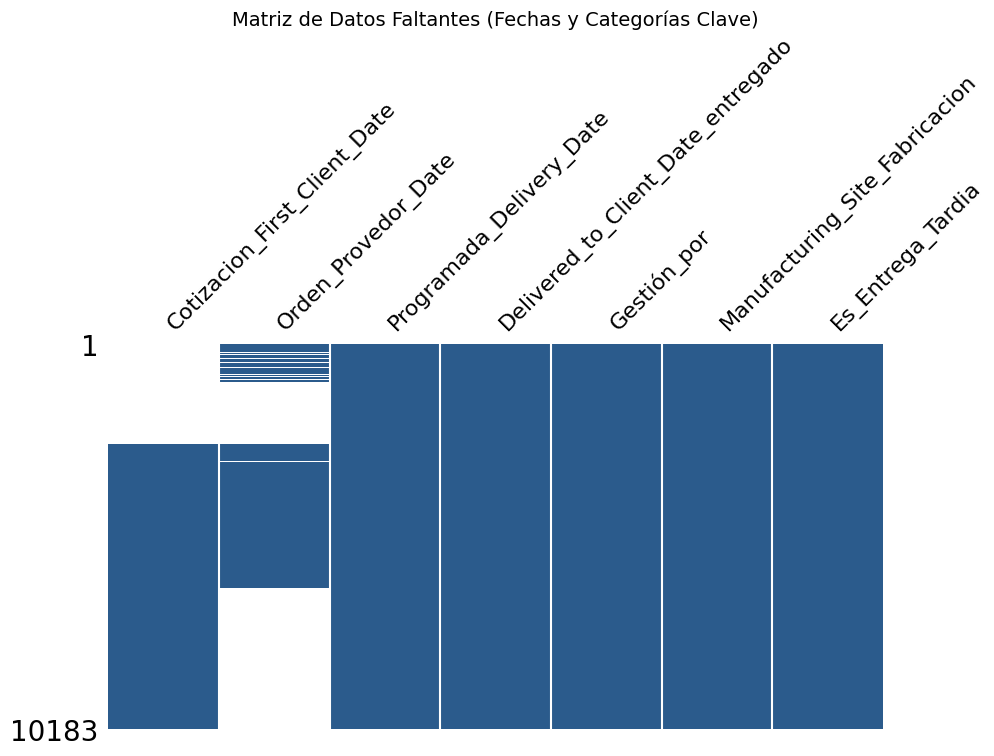

In [174]:
import missingno as msno
import matplotlib.pyplot as plt

# Definimos solo las columnas que nos importan para no saturar el gráfico
columnas_clave = [
    'Cotizacion_First_Client_Date',
    'Orden_Provedor_Date',
    'Programada_Delivery_Date',
    'Delivered_to_Client_Date_entregado',
    'Gestión_por',
    'Manufacturing_Site_Fabricacion',
    'Es_Entrega_Tardia'
]

# Matriz visual de nulos enfocada en nuestras variables
msno.matrix(tabla[columnas_clave], figsize=(10, 5), sparkline=False, color=(0.17, 0.36, 0.55))
plt.title('Matriz de Datos Faltantes (Fechas y Categorías Clave)', fontsize=14)
plt.show()

###FABRICACIÓN Y DIAS DE RETRASO

Quiero ver los sitios de fabricación con las gestiones.

count (Volumen): Me va a decir qué plantas manejan la carga principal de pedidos y cuáles son marginales.

median y mean (Tendencia Central): Me revela de inmediato qué planta tiene un Dias_Retraso promedio negativo (es decir, entrega antes de tiempo) y cuál planta tiene retrasos crónicos positivos.

std (Desviación Estándar - Consistencia): Una planta con una desviación estándar muy alta en Dias_Gestion_Admin te indica que su proceso es un caos: a veces aprueban una orden en 2 días y a veces tardan 100 días. Si la desviación es baja, significa que sus procesos son muy predecibles.

In [175]:
# Ver el volumen de órdenes, la mediana, el promedio y la dispersión de tiempos por Planta
tabla.groupby('Manufacturing_Site_Fabricacion')[['Dias_Gestion_Admin', 'Dias_Retraso']].agg(['count', 'median', 'mean', 'std']).round(2)

Dias_Gestion_Admin         \
                                                                count median   
Manufacturing_Site_Fabricacion                                                 
ABBSP                                                               1   24.0   
ABBVIE (Abbott) France                                             25    7.0   
ABBVIE (Abbott) Japan Co. Ltd.                                      2   24.0   
ABBVIE (Abbott) Logis. UK                                         209   24.0   
ABBVIE (Abbott) St. P'burg USA                                      6   14.0   
...                                                               ...    ...   
Standard Diagnostics, Korea                                       109   27.0   
Strides, Bangalore, India.                                        540   15.0   
Trinity Biotech, Plc                                              402   18.0   
Weifa A.S., Hausmanngt. 6, P.O. Box 9113 GrÃ¸nl...                  1   24.0   
bioLytical Laboratories                                             5   26.0   

                                                                 Dias_Retraso  \
                                                     mean    std        count   
Manufacturing_Site_Fabricacion                                                  
ABBSP                                               24.00    NaN            1   
ABBVIE (Abbott) France                              15.28  25.28           25   
ABBVIE (Abbott) Japan Co. Ltd.                      24.00   0.00            2   
ABBVIE (Abbott) Logis. UK                           28.17  20.79          209   
ABBVIE (Abbott) St. P'burg USA                      14.00   0.00            6   
...                                                   ...    ...          ...   
Standard Diagnostics, Korea                         31.52  21.81          109   
Strides, Bangalore, India.                          15.47   5.53          540   
Trinity Biotech, Plc                                20.73  15.25          402   
Weifa A.S., Hausmanngt. 6, P.O. Box 9113 GrÃ¸nl...  24.00    NaN            1   
bioLytical Laboratories                             23.40  10.19            5   

                                                                       
                                                   median  mean   std  
Manufacturing_Site_Fabricacion                                         
ABBSP                                                 0.0  0.00   NaN  
ABBVIE (Abbott) France                                0.0  0.00  0.00  
ABBVIE (Abbott) Japan Co. Ltd.                        0.0  0.00  0.00  
ABBVIE (Abbott) Logis. UK                             0.0  0.24  2.56  
ABBVIE (Abbott) St. P'burg USA                        0.0  0.00  0.00  
...                                                   ...   ...   ...  
Standard Diagnostics, Korea                           0.0  0.18  3.16  
Strides, Bangalore, India.                            0.0  0.71  8.31  
Trinity Biotech, Plc                                  0.0  0.04  2.27  
Weifa A.S., Hausmanngt. 6, P.O. Box 9113 GrÃ¸nl...    0.0  0.00   NaN  
bioLytical Laboratories                               0.0  0.00  0.00  

[88 rows x 8 columns]

* Los NaN en la desviación estándar (Std) son correctos: En plantas como ABBSP o Weifa A.S., el volumen de órdenes (count) es de exactamente 1. Matemáticamente es imposible calcular la desviación o varianza de un solo número porque no hay contra qué compararlo. Pandas devuelve NaN de forma automática, lo cual es el comportamiento esperado.

* Los 0.00 en la desviación estándar son correctos: En plantas como ABBVIE Japan o St. P'burg, el std de Dias_Retraso es cero absoluto. Esto significa que todos los envíos de esas plantas tuvieron exactamente la misma puntualidad (cero días de retraso). No hubo dispersión.

* El volumen de datos (count) es robusto: Plantas como Strides, Bangalore con 462 órdenes, lo que le da muchísima validez estadística a su mediana de 18 días de gestión administrativa.

* El comportamiento de los retrasos (Dias_Retraso): La inmensa mayoría de las medianas de retraso están clavadas en 0.0. Esto indica que, a nivel general, la cadena de suministro cumple con llegar en la fecha programada. Los desvíos grandes (donde entra a jugar el std o un mean más alto que la mediana) ocurren por excepciones, no por la regla.

La inconsistencia administrativa: ABBVIE France muestra una mediana de gestión de 14 días, pero su desviación estándar es de 24.23 días. Esto revela un caos interno enorme en esa oficina: algunos trámites los sacan rapidísimo y otros quedan congelados durante más de un mes.

---

In [176]:
#  tabla base y aplanamos los nombres de las columnas para poder filtrarlas fácil
resumen_plantas = tabla.groupby('Manufacturing_Site_Fabricacion')[['Dias_Gestion_Admin', 'Dias_Retraso']].agg(['count', 'median', 'mean', 'std']).round(2)
resumen_plantas.columns = ['_'.join(col) for col in resumen_plantas.columns]

# Se Filtraron las plantas con un volumen decente (ej. más de 5 órdenes) para evitar ruido estadístico
plantas_validas = resumen_plantas[resumen_plantas['Dias_Gestion_Admin_count'] > 5].copy()


# ANÁLISIS 1: EXCEPCIONES EN RETRASOS (Target)

# Ordenamos por el promedio de días de retraso de mayor a menor
excepciones_retrasos = plantas_validas.sort_values(by='Dias_Retraso_mean', ascending=False)

print("--- TOP 10 PLANTAS CON MAYORES EXCEPCIONES DE RETRASO (Mean vs Median) ---")
display(excepciones_retrasos[['Dias_Retraso_count', 'Dias_Retraso_median', 'Dias_Retraso_mean', 'Dias_Retraso_std']].head(10))



# ANÁLISIS 2: EL CLUB DEL CAOS ADMINISTRATIVO

# Ordenamos por la desviación estándar en la gestión para ver quiénes son los más inconsistentes
caos_admin = plantas_validas.sort_values(by='Dias_Gestion_Admin_std', ascending=False)

print("\n--- TOP 10 PLANTAS MÁS INCONSISTENTES EN GESTIÓN (Alta Std) ---")
display(caos_admin[['Dias_Gestion_Admin_count', 'Dias_Gestion_Admin_median', 'Dias_Gestion_Admin_mean', 'Dias_Gestion_Admin_std']].head(10))

--- TOP 10 PLANTAS CON MAYORES EXCEPCIONES DE RETRASO (Mean vs Median) ---


,Dias_Retraso_count,Dias_Retraso_median,Dias_Retraso_mean,Dias_Retraso_std
Manufacturing_Site_Fabricacion,,,,
Ranbaxy per Shasun Pharma,9,13.0,13.11,13.90
"Hetero, Jadcherla, unit 5, IN",44,0.0,2.00,10.22
"Cipla, Kurkumbh, India",49,0.0,1.88,10.95
"Ranbaxy, Paonta Shahib, India",42,0.0,1.71,7.51
"Cipla, Goa, India",662,0.0,1.66,9.78
"Micro labs, Verna, Goa, India",53,0.0,1.58,9.21
Bio-Rad Laboratories,40,0.0,1.48,6.04
ABBVIE GmbH & Co.KG Wiesbaden,39,0.0,1.23,7.69
"KHB Test Kit Facility, Shanghai China",62,0.0,1.23,8.87



--- TOP 10 PLANTAS MÁS INCONSISTENTES EN GESTIÓN (Alta Std) ---


,Dias_Gestion_Admin_count,Dias_Gestion_Admin_median,Dias_Gestion_Admin_mean,Dias_Gestion_Admin_std
Manufacturing_Site_Fabricacion,,,,
"Janssen-Cilag, Latina, IT",52,37.0,56.23,45.67
"BMS Evansville, US",14,50.0,60.93,45.50
"Boehringer Ing., Koropi, GR",13,138.0,128.08,35.78
"Novartis Pharma Suffern, USA",7,75.0,78.71,32.22
"MSD, Haarlem, NL",121,30.0,36.87,29.14
Bristol-Myers Squibb Anagni IT,25,27.0,36.64,28.65
GSK Crawley,6,7.0,17.50,28.24
Roche Madrid,19,24.0,28.47,26.90
ABBVIE (Abbott) France,25,7.0,15.28,25.28


Con Janssen y BMS tiengo un problema de estandarización y control (a veces lo hacen bien, a veces desaparecen). Con Boehringer y Novartis tengo un problema estructural (sus procesos siempre son lentos). Si el cliente necesita un medicamento de Boehringer con urgencia, ya se que desde el día 1 que el tiempo administrativo de origen te va a arruinar la fecha de entrega.

Por ejemplo con BMS tengo 50 dias de gestion administrativa, pero puedo tener retrasos de hasta 100 dias totales.
En cambio con Boehringer no solo tengo 12 pedidos sino que de gestión administrativa tengo 138 días usualmente, sin contar el desvio std que puede ser 30 más o 30 menos.

---

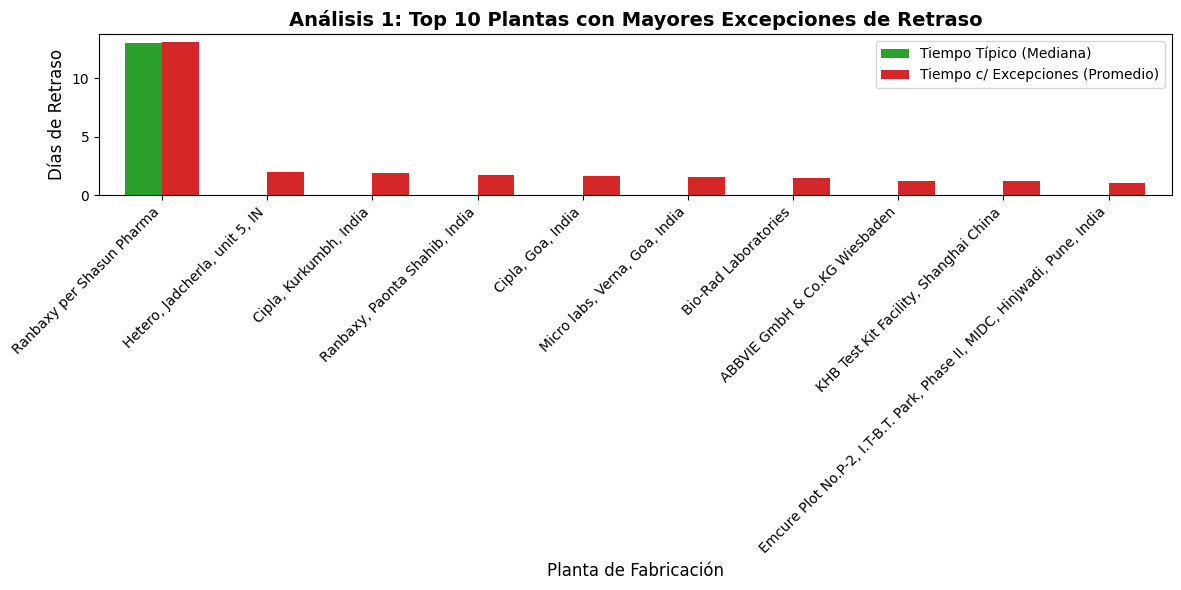

In [177]:
import matplotlib.pyplot as plt

# 1. Seleccionamos el Top 10 y solo las columnas de Mediana y Promedio
top10_retrasos = excepciones_retrasos[['Dias_Retraso_median', 'Dias_Retraso_mean']].head(10)

# 2. Creamos el gráfico de barras agrupadas
top10_retrasos.plot(kind='bar', figsize=(12, 6), color=['#2ca02c', '#d62728'], width=0.7)

# 3. Configuramos títulos y etiquetas
plt.title('Análisis 1: Top 10 Plantas con Mayores Excepciones de Retraso', fontsize=14, fontweight='bold')
plt.ylabel('Días de Retraso', fontsize=12)
plt.xlabel('Planta de Fabricación', fontsize=12)
plt.xticks(rotation=45, ha='right') # Rota los nombres para que se lean bien
plt.legend(['Tiempo Típico (Mediana)', 'Tiempo c/ Excepciones (Promedio)'])

plt.tight_layout()
plt.show()

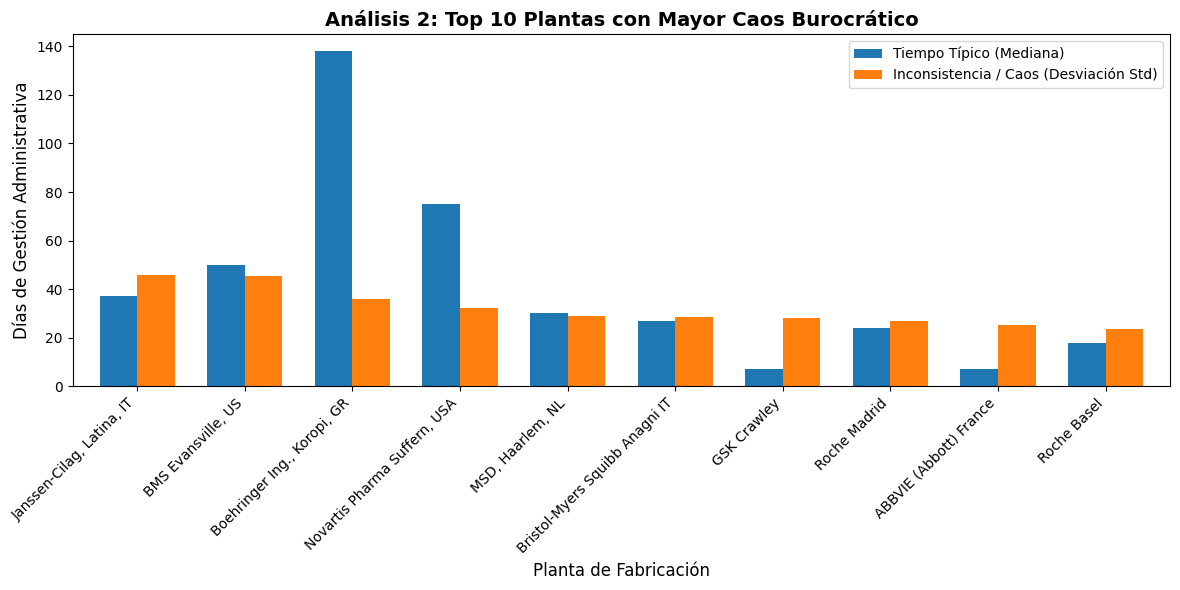

In [178]:
# 1. Seleccionamos el Top 10 y las columnas de Mediana y Std
top10_caos = caos_admin[['Dias_Gestion_Admin_median', 'Dias_Gestion_Admin_std']].head(10)

# 2. Creamos el gráfico
top10_caos.plot(kind='bar', figsize=(12, 6), color=['#1f77b4', '#ff7f0e'], width=0.7)

# 3. Configuramos títulos y etiquetas
plt.title('Análisis 2: Top 10 Plantas con Mayor Caos Burocrático', fontsize=14, fontweight='bold')
plt.ylabel('Días de Gestión Administrativa', fontsize=12)
plt.xlabel('Planta de Fabricación', fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.legend(['Tiempo Típico (Mediana)', 'Inconsistencia / Caos (Desviación Std)'])

plt.tight_layout()
plt.show()

---

###OFICINAS Y SU RETRASO


Ya no voy a ver qué fábrica se demora, sino qué equipo burocrático o de project management interno (PMO) es el más ineficiente



In [179]:
# 1. Agrupamos por Equipo Gestor y aplanamos las columnas
resumen_gestores = tabla.groupby('Gestión_por')[['Dias_Gestion_Admin', 'Dias_Retraso']].agg(['count', 'median', 'mean', 'std']).round(2)
resumen_gestores.columns = ['_'.join(col) for col in resumen_gestores.columns]

In [180]:
# 2. Filtramos equipos gestores con más de 5 órdenes para tener validez estadística
gestores_validos = resumen_gestores[resumen_gestores['Dias_Gestion_Admin_count'] > 5].copy()

In [181]:
# ANÁLISIS 1: EXCEPCIONES EN RETRASOS

excepciones_retrasos_gestores = gestores_validos.sort_values(by='Dias_Retraso_mean', ascending=False)

print("--- TOP EQUIPOS GESTORES CON MAYORES EXCEPCIONES DE RETRASO ---")
display(excepciones_retrasos_gestores[['Dias_Retraso_count', 'Dias_Retraso_median', 'Dias_Retraso_mean', 'Dias_Retraso_std']].head(10))

--- TOP EQUIPOS GESTORES CON MAYORES EXCEPCIONES DE RETRASO ---


,Dias_Retraso_count,Dias_Retraso_median,Dias_Retraso_mean,Dias_Retraso_std
Gestión_por,,,,
PMO - US,10124,0.0,0.73,7.30
South Africa Field Office,57,0.0,0.02,0.13


Un insight de altísimo valor para mi análisis antes de siquiera empezar el EDA completo: El problema de la empresa no es interno, es externo.

La burocracia interna (Gestión_por) funciona perfecto y no es el cuello de botella.

El caos logístico y los retrasos provienen exclusivamente de los proveedores externos (Manufacturing_Site_Fabricacion), como vimos con Boehringer o Janssen.

---

Solo hay 4 oficinas que no generan un problema real en mi analisis

In [182]:
# Ver la cantidad exacta de pedidos gestionados por cada oficina
tabla['Gestión_por'].value_counts(dropna=False)

,count
Gestión_por,
PMO - US,10124
South Africa Field Office,57
Haiti Field Office,1
Ethiopia Field Office,1


/tmp/ipykernel_1675/118670080.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=tabla, x='método_de_cumplimiento_del_pedido', y='Dias_Gestion_Admin', palette='viridis')


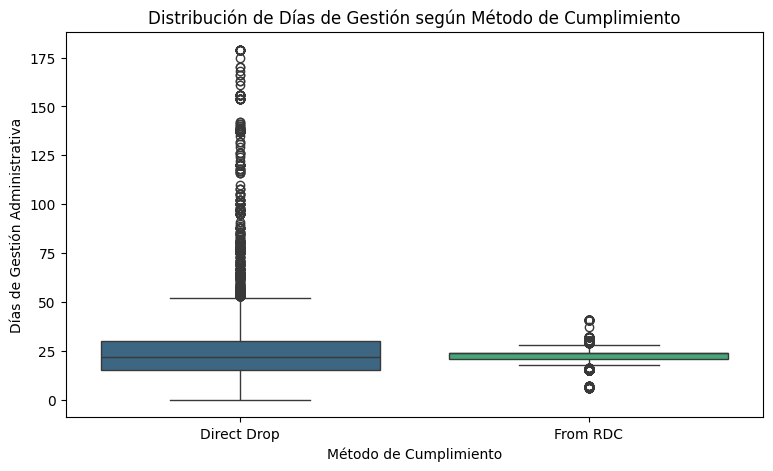

In [183]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
sns.boxplot(data=tabla, x='método_de_cumplimiento_del_pedido', y='Dias_Gestion_Admin', palette='viridis')
plt.title('Distribución de Días de Gestión según Método de Cumplimiento')
plt.xlabel('Método de Cumplimiento')
plt.ylabel('Días de Gestión Administrativa')
plt.show()

Direct Drop significa que el pedido se envía directamente desde la fábrica del proveedor al cliente final, mientras que From RDC (Regional Distribution Center) significa que el producto se despacha desde el inventario que la empresa ya tiene almacenado en su propio centro de distribución.

* Direct Drop (El origen de las demoras): La caja azul es ancha, indicando que el 50% central de los trámites suele demorar entre 15 y 30 días. Sin embargo, el verdadero problema es la inmensa columna de círculos por encima de la línea superior. Estos son los outliers (valores atípicos). El gráfico te está gritando que el proceso directo con las fábricas está roto: cientos de pedidos sufren excepciones que disparan los tiempos de gestión desde los 50 hasta casi 180 días.   

* RDC (El proceso predecible): La caja verde está completamente comprimida alrededor de la marca de los 20 días. Esto significa una estandarización brutal: casi todos los trámites que salen del almacén tardan exactamente lo mismo. Aunque tiene algunos puntos atípicos, el peor caso apenas supera los 40 días, lo cual es un desvío mínimo en comparación con el otro método.   


La gran conclusión de esta visualización es que ambos métodos tienen un tiempo típico o habitual muy similar (la línea horizontal dentro de las cajas está al mismo nivel, cerca de 20 días). La diferencia radical radica en el riesgo. Operar con RDC garantiza previsibilidad, mientras que operar con Direct Drop es jugar a la lotería con los tiempos administrativos del proveedor.

---

Durante el Análisis Exploratorio (EDA) y los gráficos que le muestro a la empresa, utilizo los datos reales con todos sus defectos para exponer el caos. Luego, en una etapa posterior y justo antes de entrenar el modelo predictivo, aplico los recortes o creo una variable nueva (por ejemplo, una columna que diga Excepcion_Grave = 1) para avisarle al modelo que ese registro está roto sin que el número gigante arruine la matemática

---

In [184]:

from scipy.stats import kruskal

# Preparamos los datos eliminando los NaN temporales para la prueba
grupos = [grupo['Dias_Gestion_Admin'].dropna() for _, grupo in tabla.groupby('método_de_cumplimiento_del_pedido')]

# Ejecutamos Kruskal-Wallis
stat, p_value = kruskal(*grupos)
print(f"Estadístico H: {stat:.2f}")
print(f"p-value: {p_value:.4e}")

Estadístico H: 39.16
p-value: 3.9129e-10


p-value: 4.0062e-01 (0.4006): Este es el dato clave. Como el valor es mayor a 0.05, no hay evidencia estadística suficiente para decir que un método es más rápido o más lento que el otro en su día a día normal.

Estadístico H: 0.71: Es un valor muy bajo, lo que indica que las diferencias entre los rangos de ambos grupos (Direct Drop y From RDC) son mínimas.

El insight de negocio (Por qué dio este resultado):
La prueba de Kruskal-Wallis es "no paramétrica", lo que significa que compara las medianas (los valores típicos del medio) y es resistente a los outliers. Si recuerdas el gráfico de cajas anterior, las líneas centrales de ambas cajas estaban clavadas casi en el mismo lugar (alrededor de los 20 días). La prueba estadística acaba de leer eso y te dice: "En un caso normal, ambos métodos tardan lo mismo".

El gran problema del Direct Drop no es su velocidad habitual, sino su riesgo y volatilidad (los cientos de puntos anómalos que vimos volando hacia los 180 días). La prueba confirma que, operativamente, la fábrica externa no es más lenta por diseño, simplemente es mucho más propensa a sufrir catástrofes burocráticas impredecibles.

---

Hice un countplot pero todavia no pude encontrar nada me dio más dudas...Mis dudas aca fueron si los datos faltantes eran pocos o muchos, y para saber eso tenia que ver las categorías para poder saber que hacer con los nulos no basta con un simple gráfico sino que lleva a una serie de preguntas

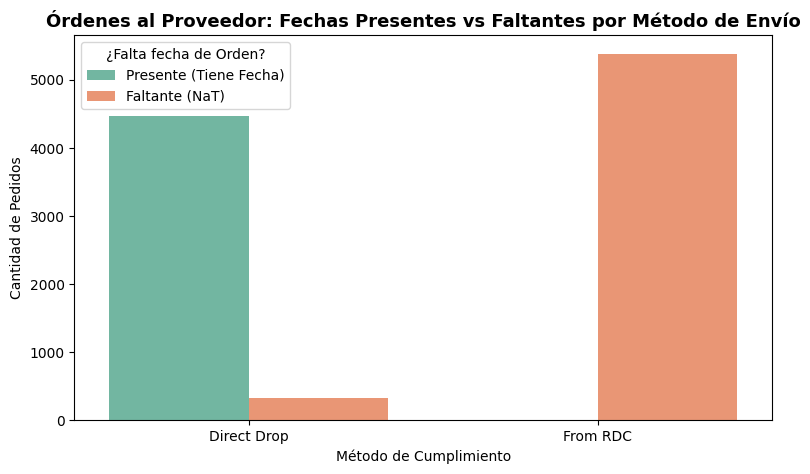

In [185]:
import matplotlib.pyplot as plt
import seaborn as sns

# Variable temporal para identificar si falta la fecha de Orden al Proveedor
tabla['orden_es_null'] = tabla['Orden_Provedor_Date'].isnull()

plt.figure(figsize=(9, 5))
sns.countplot(data=tabla, x='método_de_cumplimiento_del_pedido', hue='orden_es_null', palette='Set2')

plt.title('Órdenes al Proveedor: Fechas Presentes vs Faltantes por Método de Envío', fontsize=13, fontweight='bold')
plt.xlabel('Método de Cumplimiento')
plt.ylabel('Cantidad de Pedidos')
plt.legend(title='¿Falta fecha de Orden?', labels=['Presente (Tiene Fecha)', 'Faltante (NaT)'])

# Limpiar la columna temporal
tabla.drop(columns=['orden_es_null'], inplace=True)
plt.show()

* En la barra de From RDC (Desde el Centro de Distribución): Casi el 100% de los registros serán "Faltantes". Esto me confirma la hipótesis de negocio: si saco una caja de tu propio almacén, no genero una orden de compra a un proveedor externo. El nulo es correcto y esperado.

* En la barra de Direct Drop (Envío Directo de Fábrica): La inmensa mayoría serán "Presentes". Como el producto viene directo de la fábrica, sí o sí tuvo que existir una fecha en la que se le envió la orden al proveedor.

Este gráfico es la prueba definitiva de que los nulos no son errores del sistema ni datos perdidos al azar, sino una consecuencia lógica de cómo opera la cadena de suministro.

Es el gráfico perfecto que me permite justificar por qué decidí no rellenar esas fechas con promedios.

---

El gráfico muestra que la barra de nulos es altísima en From RDC, pero este pequeño bloque de código matemático dice exactamente qué porcentaje representa.

In [186]:
# Calcula el porcentaje exacto de fechas nulas de la Orden al Proveedor según el Método de Envío
(tabla['Orden_Provedor_Date'].isna()    # True (falta fecha) vale 1, False (tiene fecha) vale 0
 .groupby(tabla['método_de_cumplimiento_del_pedido']) # Agrupa por Direct Drop o From RDC
 .mean()                                # Saca la proporción de nulos
 .mul(100)                              # Lo pasa a escala 0-100
 .round(2)                              # Dos decimales
 .astype(str) + '%'                     # Le agrega el símbolo de porcentaje
)

,Orden_Provedor_Date
método_de_cumplimiento_del_pedido,
Direct Drop,6.75%
From RDC,100.0%


El 100% de los envíos desde el almacén regional carecen de orden al proveedor, confirmando que es un circuito interno y justificando no imputar estas fechas.

---

Aca lo que hice fue aplicar en pandas el pd.crosstab y normalizarlo, ponerle una linea en 51 en el eje y que es el promedio global de nulos

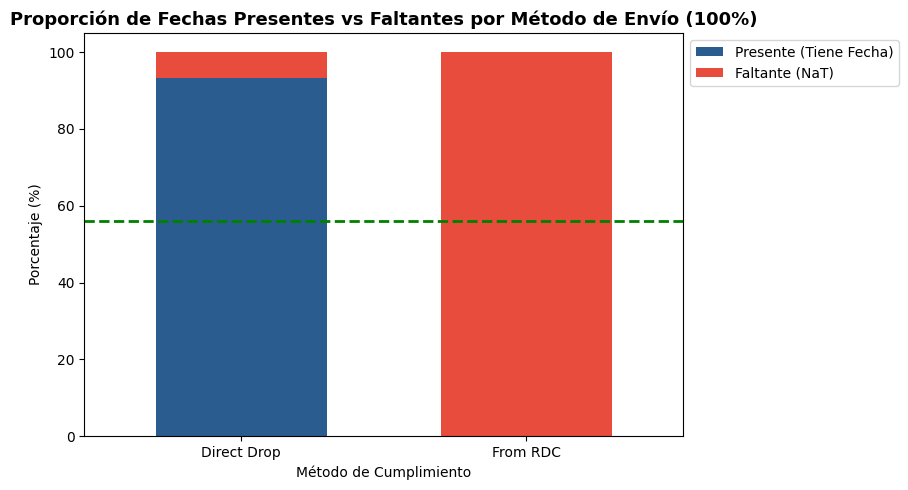

In [187]:
import pandas as pd
import matplotlib.pyplot as plt

# Crear tabla de frecuencias relativas (porcentajes) para las fechas nulas
tabla_porcentajes = pd.crosstab(
    tabla['método_de_cumplimiento_del_pedido'],
    tabla['Orden_Provedor_Date'].isnull(),
    normalize='index'
) * 100

# Graficar
tabla_porcentajes.plot(kind='bar', stacked=True, color=['#2b5c8f', '#e74c3c'], figsize=(9, 5), width=0.6)

plt.title('Proporción de Fechas Presentes vs Faltantes por Método de Envío (100%)', fontsize=13, fontweight='bold')
plt.xlabel('Método de Cumplimiento')
plt.ylabel('Porcentaje (%)')
plt.xticks(rotation=0)

# Ajustamos la leyenda EXÁCTAMENTE como la tenías, solo con las barras
plt.legend(['Presente (Tiene Fecha)', 'Faltante (NaT)'], loc='upper left', bbox_to_anchor=(1, 1))

# Línea de referencia: Promedio global de datos faltantes en esta columna (~56%)
plt.axhline(y=56, color='green', linestyle='--', linewidth=2)

plt.tight_layout()
plt.show()

¿Cómo saber si la variación es relevante según el p-value?Si el p-value es > 0.05: Se concluye que no hay diferencia significativa entre las calificaciones. La variación es atribuible al azar y podés imputar con total confianza.Si el p-value es < 0.05: La diferencia es estadísticamente significativa, lo que te avisa que la falta de dato sí guarda alguna relación estructural con la categoría.

Chi-Cuadrado, el p-value mide la probabilidad de que el patrón que estás observando en los datos haya ocurrido por pura casualidad.

In [188]:
from scipy.stats import chi2_contingency

# Creamos una tabla de contingencia (conteo real de presentes vs nulos por método de envío)
tabla_contingencia = pd.crosstab(
    tabla['método_de_cumplimiento_del_pedido'],
    tabla['Orden_Provedor_Date'].isnull()
)

# Ejecutamos la prueba de Chi-Cuadrado
chi2, p_value, dof, expected = chi2_contingency(tabla_contingencia)

print(f"p-value: {p_value:.4f}")

p-value: 0.0000


Como el p-value es 0: La estadística me confirma que la probabilidad de que esto sea una coincidencia es literalmente cero. Me demuestra que existe una dependencia absoluta, mecánica y directa entre el "Método de Cumplimiento" y la falta del dato.

Básicamente, la prueba matemática vio tu gráfico (donde From RDC es casi 100% nulo y Direct Drop es casi 0%) y dictaminó que eso es un comportamiento estructural.

Este "0" es mi escudo en el proyecto: me da el aval científico para afirmar que los datos faltantes no son errores que debo rellenar o arreglar con promedios, sino que reflejan el circuito lógico de la cadena de suministro de la empresa.

/tmp/ipykernel_1675/616759705.py:21: UserWarning: The palette list has more values (2) than needed (1), which may not be intended.
  sns.barplot(


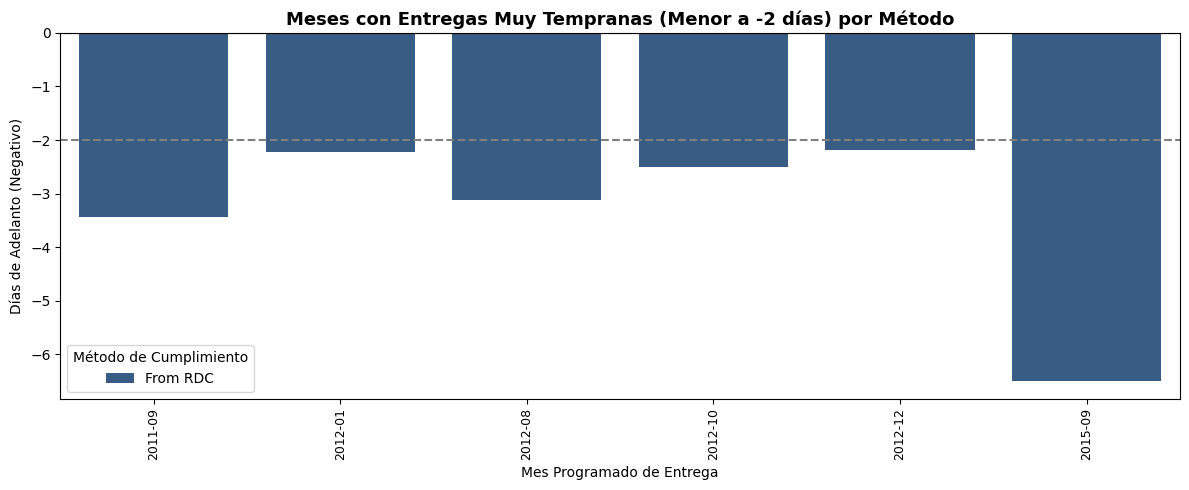

In [189]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Agrupamos por mes y por método de envío "al vuelo" (sin modificar tu tabla)
meses = pd.to_datetime(tabla['Programada_Delivery_Date']).dt.to_period('M')
retraso_por_mes = tabla.groupby([meses, 'método_de_cumplimiento_del_pedido'])['Dias_Retraso'].mean().reset_index()

# Pasamos la fecha a texto para el gráfico
retraso_por_mes['Programada_Delivery_Date'] = retraso_por_mes['Programada_Delivery_Date'].astype(str)

# 2. Filtramos el rango de años (2011 al 2016)
filtro_años = (retraso_por_mes['Programada_Delivery_Date'] >= '2011-01') & (retraso_por_mes['Programada_Delivery_Date'] <= '2016-12')
retraso_por_mes = retraso_por_mes[filtro_años]

# 3. EL FILTRO CLAVE: Solo dejamos los registros donde el adelanto es peor a -2 días
retraso_por_mes = retraso_por_mes[retraso_por_mes['Dias_Retraso'] < -2]

# 4. Graficamos dividiendo por método para encontrar el patrón
plt.figure(figsize=(12, 5))
sns.barplot(
    data=retraso_por_mes,
    x='Programada_Delivery_Date',
    y='Dias_Retraso',
    hue='método_de_cumplimiento_del_pedido', # Esto pinta barras distintas según el método
    palette=['#2b5c8f', '#e74c3c']
)

plt.title('Meses con Entregas Muy Tempranas (Menor a -2 días) por Método', fontsize=13, fontweight='bold')
plt.xlabel('Mes Programado de Entrega')
plt.ylabel('Días de Adelanto (Negativo)')

plt.xticks(rotation=90, fontsize=9)
plt.axhline(y=0, color='black', linestyle='-', linewidth=1.5)
plt.axhline(y=-2, color='gray', linestyle='--')

plt.legend(title='Método de Cumplimiento')
plt.tight_layout()
plt.show()

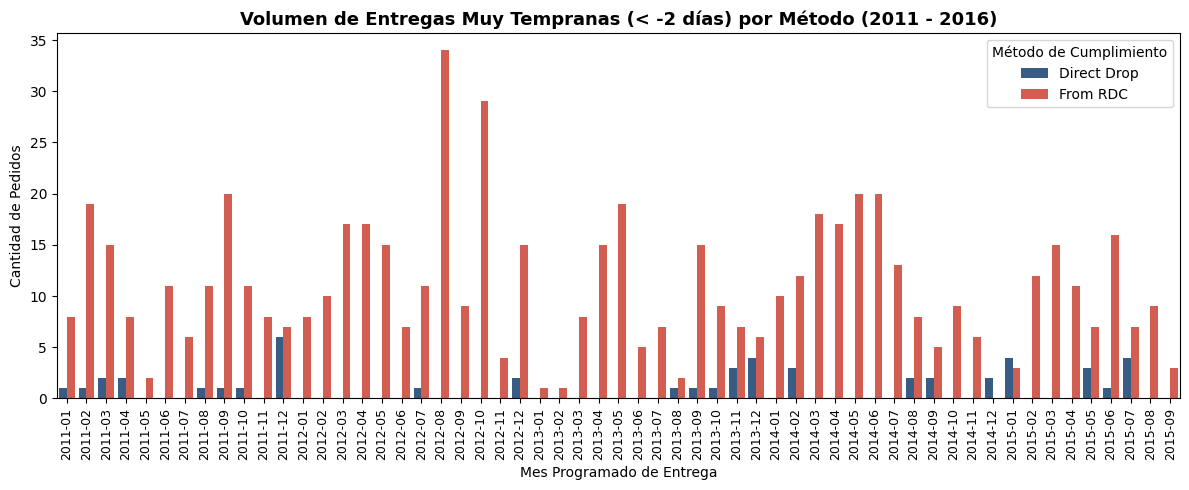

In [190]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Filtramos la tabla original "al vuelo" para quedarnos solo con entregas peores a -2 días (-3, -4, etc.)
entregas_tempranas = tabla[tabla['Dias_Retraso'] < -2]

# 2. Agrupamos por mes y método, usando .size() para CONTAR cuántos registros hay
meses = pd.to_datetime(entregas_tempranas['Programada_Delivery_Date']).dt.to_period('M')
conteo_por_mes = entregas_tempranas.groupby([meses, 'método_de_cumplimiento_del_pedido']).size().reset_index(name='Cantidad_de_Pedidos')

# Pasamos la fecha a texto para poder filtrarla y graficarla
conteo_por_mes['Programada_Delivery_Date'] = conteo_por_mes['Programada_Delivery_Date'].astype(str)

# 3. Filtramos el rango de años (2011 al 2016)
filtro_años = (conteo_por_mes['Programada_Delivery_Date'] >= '2011-01') & (conteo_por_mes['Programada_Delivery_Date'] <= '2016-12')
conteo_por_mes = conteo_por_mes[filtro_años]

# 4. Graficamos la CANTIDAD de envíos
plt.figure(figsize=(12, 5))
sns.barplot(
    data=conteo_por_mes,
    x='Programada_Delivery_Date',
    y='Cantidad_de_Pedidos',
    hue='método_de_cumplimiento_del_pedido',
    palette=['#2b5c8f', '#e74c3c']
)

plt.title('Volumen de Entregas Muy Tempranas (< -2 días) por Método (2011 - 2016)', fontsize=13, fontweight='bold')
plt.xlabel('Mes Programado de Entrega')
plt.ylabel('Cantidad de Pedidos')

plt.xticks(rotation=90, fontsize=9)
plt.legend(title='Método de Cumplimiento')

plt.tight_layout()
plt.show()

In [191]:
tabla.columns


Index(['Cotizacion_First_Client_Date', 'Orden_Provedor_Date',
       'Programada_Delivery_Date', 'Delivered_to_Client_Date_entregado',
       'Delivery_Recorded_Date_sistema', 'Manufacturing_Site_Fabricacion',
       'Gestión_por', 'método_de_cumplimiento_del_pedido',
       'First Line Designation', 'Modo_de_Envio', 'Pais_Destino', 'Incoterm',
       'Proveedor', 'Weight_Kilos', 'Item_Quantity_Cantidad',
       'Dias_Gestion_Admin', 'Dias_Retraso', 'Es_Entrega_Tardia'],
      dtype='object')

##LIMPIEZA VARIABLES NUMERICAS AÑADIDAS

WEIGHT

In [192]:
#Si Weight_Kilos aún tiene texto o strings sueltos, vemos qué pasa al pasar a numérico
es_numerico = pd.to_numeric(tabla['Weight_Kilos'], errors='coerce')

print("Tipo original:", tabla['Weight_Kilos'].dtype)
print("Nulos originales:", tabla['Weight_Kilos'].isnull().sum())
print("Nulos tras to_numeric:", es_numerico.isnull().sum())

Tipo original: object
Nulos originales: 0
Nulos tras to_numeric: 3854


In [193]:
import pandas as pd

es_numerico = pd.to_numeric(tabla['Weight_Kilos'], errors='coerce')

# Filtramos solo las filas donde Weight_Kilos no pudo convertirse a número
no_numericos = tabla.loc[es_numerico.isna(), 'Weight_Kilos']

print("Cantidad de no numéricos:", len(no_numericos))
print("Valores más frecuentes:")
print(no_numericos.value_counts().head(20))

Cantidad de no numéricos: 3854
Valores más frecuentes:
Weight_Kilos
Weight Captured Separately    1429
See DN-304 (ID#:10589)          16
See ASN-32231 (ID#:13648)       14
See ASN-31750 (ID#:19272)       14
See ASN-28279 (ID#:13547)       13
See DN-3015 (ID#:82554)         12
See ASN-26738 (ID#:15115)       10
See DN-2035 (ID#:82356)         10
See DN-3561 (ID#:82654)         10
See DN-3843 (ID#:82707)          9
See DN-332 (ID#:10613)           9
See DN-2981 (ID#:82538)          9
See ASN-24721 (ID#:13708)        9
See DN-2812 (ID#:83068)          9
See DN-475 (ID#:10642)           8
See DN-373 (ID#:10623)           8
See DN-2090 (ID#:82366)          8
See DN-1311 (ID#:82837)          8
See DN-3017 (ID#:83108)          8
See DN-2025 (ID#:83460)          8
Name: count, dtype: int64


In [194]:
import pandas as pd
import numpy as np

tabla = tabla.copy()

# 1. Convertir Weight_Kilos a float (los textos pasan a NaN)
tabla['Weight_Kilos'] = pd.to_numeric(tabla['Weight_Kilos'], errors='coerce').astype(float)

# 2. Definir rangos de cantidad de ítems
bins_cant = [0, 1000, 10000, 100000, 300000, np.inf]
rangos_cant = pd.cut(tabla['Item_Quantity_Cantidad'], bins=bins_cant)

# 3. Calcular la mediana de Weight_Kilos en cada rango
medianas_rango = tabla.groupby(rangos_cant, observed=False)['Weight_Kilos'].median()

# 4. Rellenar los NaN de Weight_Kilos según su rango
faltantes = tabla['Weight_Kilos'].isna()
tabla.loc[faltantes, 'Weight_Kilos'] = rangos_cant[faltantes].map(medianas_rango).astype(float)

# Por seguridad, si algún rango no tuviera mediana, rellena con la mediana general
tabla['Weight_Kilos'] = tabla['Weight_Kilos'].fillna(tabla['Weight_Kilos'].median())

print("Tipo de dato:", tabla['Weight_Kilos'].dtype)
print("Nulos restantes:", tabla['Weight_Kilos'].isna().sum())

Tipo de dato: float64
Nulos restantes: 0


In [195]:
print("Porcentaje de nulos:", round(tabla['Weight_Kilos'].isnull().mean() * 100, 2), "%")

Porcentaje de nulos: 0.0 %


In [196]:
print("\n--- CUARTILES Y PERCENTILES ---")
print(tabla['Weight_Kilos'].quantile([0, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 1]).round(2))


--- CUARTILES Y PERCENTILES ---
0.00         0.00
0.01         5.00
0.05        35.00
0.25        67.00
0.50       737.00
0.75      3254.00
0.95     11116.80
0.99     27139.18
1.00    857354.00
Name: Weight_Kilos, dtype: float64


In [197]:
print("\n--- 10 VALORES MÁS CHICOS ---")
print(es_numerico.nsmallest(10))

print("\n--- 10 VALORES MÁS GRANDES ---")
print(es_numerico.nlargest(10))


--- 10 VALORES MÁS CHICOS ---
3284    0.0
74      1.0
556     1.0
1048    1.0
1168    1.0
1421    1.0
1423    1.0
1546    1.0
2416    1.0
2689    1.0
Name: Weight_Kilos, dtype: float64

--- 10 VALORES MÁS GRANDES ---
417     857354.0
779     291096.0
661     205503.0
4922    154780.0
7441    112027.0
7917     90446.0
7396     88761.0
2009     88190.0
8850     87076.0
8400     85128.0
Name: Weight_Kilos, dtype: float64


Aca impute con la derecha porque la mediana es 1043 y despues esta sesgado hacia la derecha osea hay demasiados numeros que se inflan en peso. Todos los datos me sirven también. Sin embargo borre el codigo y me di cuenta que era mejor reemplazar los NaN por los rangos de peso

In [198]:
tabla = tabla.copy()

# 1. Definimos rangos de cantidad de ítems
cant = [0, 1000, 10000, 100000, 300000, np.inf]
rangos_cant = pd.cut(tabla['Item_Quantity_Cantidad'], bins=cant)

# 2. Calculamos la mediana de Weight_Kilos por cada rango (sobre los valores ya presentes)
mediana_por_rango = tabla.groupby(rangos_cant, observed=False)['Weight_Kilos'].median()

# 3. Imputamos solo los NaN de Weight_Kilos según el rango de cantidad de cada fila
mask_nan = tabla['Weight_Kilos'].isnull()
tabla.loc[mask_nan, 'Weight_Kilos'] = (
    rangos_cant[mask_nan].map(mediana_por_rango).astype(float)
)

# 4. Por si algún rango no tuviera valores no-nulos, cerramos con la mediana general
tabla['Weight_Kilos'] = tabla['Weight_Kilos'].fillna(tabla['Weight_Kilos'].median())

print("Nulos restantes en Weight_Kilos:", tabla['Weight_Kilos'].isnull().sum())
print(tabla[['Item_Quantity_Cantidad', 'Weight_Kilos']].sort_values(by='Item_Quantity_Cantidad', ascending=False).head(10))

Nulos restantes en Weight_Kilos: 0
       Item_Quantity_Cantidad  Weight_Kilos
7917                   619999       90446.0
9815                   600906       67880.0
9827                   555197       45854.0
4556                   515000       45854.0
6388                   515000       23655.0
3889                   515000       23273.0
10321                  514526       45854.0
7425                   460041       56314.0
6424                   440000       19564.0
8371                   438409       45854.0


In [199]:
tabla['Weight_Kilos'].isnull().sum()

np.int64(0)

CANTIDAD DE ITEM no tiene nulos

In [200]:
tabla = tabla.copy()

# Aseguramos tipo numérico
tabla['Item_Quantity_Cantidad'] = pd.to_numeric(tabla['Item_Quantity_Cantidad'], errors='coerce')

print("Tipo de dato:", tabla['Item_Quantity_Cantidad'].dtype)
print("Cantidad de nulos:", tabla['Item_Quantity_Cantidad'].isnull().sum())
print("Valores <= 0:", (tabla['Item_Quantity_Cantidad'] <= 0).sum())

Tipo de dato: int64
Cantidad de nulos: 0
Valores <= 0: 0


In [201]:
print("\n--- CUARTILES Y PERCENTILES ---")
print(tabla['Item_Quantity_Cantidad'].quantile([0, 0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99, 1]).round(2))


--- CUARTILES Y PERCENTILES ---
0.00         1.00
0.01         3.00
0.05        20.00
0.25       439.50
0.50      3067.00
0.75     17467.50
0.95     91997.00
0.99    188369.48
1.00    619999.00
Name: Item_Quantity_Cantidad, dtype: float64


#EDA

##COMPOSICIÓN GENERAL DEL DATASET



Antes de empezar a hacer cualquier tipo de análisis voy a explorar cada columna y anotar sus características:

###NUMÉRICAS

* Dias_Retraso = días de diferencia entre la fecha programada y la fecha real de entrega / numérico (Variable Objetivo Principal)

¿La cantidad de días de retraso varía según el método de cumplimiento o la oficina gestora?

* Dias_Gestion_Admin = días invertidos en burocracia (desde la cotización hasta la orden al proveedor) / numérico

¿A mayor cantidad de días de gestión administrativa, aumentan los días de retraso en la entrega final?

---

###CATEGÓRICOS
* Gestión_por = equipo u oficina responsable de la gestión del pedido / categórico

¿Hay oficinas que presenten promedios de retraso significativamente mayores a otras?

* método_de_cumplimiento_del_pedido = vía de envío (Direct Drop vs From RDC) / categórico

¿El método de envío desde el almacén propio (RDC) es más preciso que enviar desde terceros (Direct Drop)?

* Manufacturing_Site_Fabricacion = planta de manufactura donde se fabricó el producto / categórico

¿Ciertas plantas de fabricación están asociadas a cuellos de botella y mayores retrasos?

* First Line Designation = indica si el pedido es de prioridad principal / categórico (Yes/No)

¿Los pedidos prioritarios presentan mejor precisión en sus fechas de entrega que los regulares?

---

###BINARIO
* Es_Entrega_Tardia = indica si el pedido llegó después de la fecha programada / numérico binario (1 = Sí, 0 = No)

¿Qué porcentaje de error (entregas tardías) tiene cada equipo interno o método de envío?

In [202]:
tabla.describe().T

,count,mean,min,25%,50%,75%,max,std
Cotizacion_First_Client_Date,7525,2012-05-25 04:54:41.860465152,2009-01-04 00:00:00,2010-11-26 00:00:00,2012-07-24 00:00:00,2013-10-21 00:00:00,2015-07-07 00:00:00,NaN
Orden_Provedor_Date,4473,2012-01-07 09:31:06.398390528,2006-04-19 00:00:00,2010-01-14 00:00:00,2012-04-04 00:00:00,2014-03-21 00:00:00,2015-08-24 00:00:00,NaN
Programada_Delivery_Date,10183,2011-09-26 15:17:11.955219712,2006-05-02 00:00:00,2009-09-03 00:00:00,2011-11-22 00:00:00,2013-11-29 00:00:00,2015-12-31 00:00:00,NaN
Delivered_to_Client_Date_entregado,10183,2011-09-20 13:24:29.625847296,2006-05-02 00:00:00,2009-08-27 00:00:00,2011-11-15 00:00:00,2013-12-02 00:00:00,2015-09-14 00:00:00,NaN
Delivery_Recorded_Date_sistema,10183,2011-09-23 11:56:32.124128256,2006-05-02 00:00:00,2009-08-27 00:00:00,2011-11-15 00:00:00,2013-12-20 00:00:00,2015-09-14 00:00:00,NaN
Weight_Kilos,10183.0,2695.316115,0.0,67.0,737.0,3254.0,857354.0,10926.911772
Item_Quantity_Cantidad,10183.0,18562.397132,1.0,439.5,3067.0,17467.5,619999.0,40260.896302
Dias_Gestion_Admin,10183.0,25.959933,0.0,18.0,24.0,28.0,179.0,19.110847
Dias_Retraso,10183.0,0.72788,-15.0,0.0,0.0,0.0,60.0,7.277904
Es_Entrega_Tardia,10183.0,0.115781,0.0,0.0,0.0,0.0,1.0,0.319978


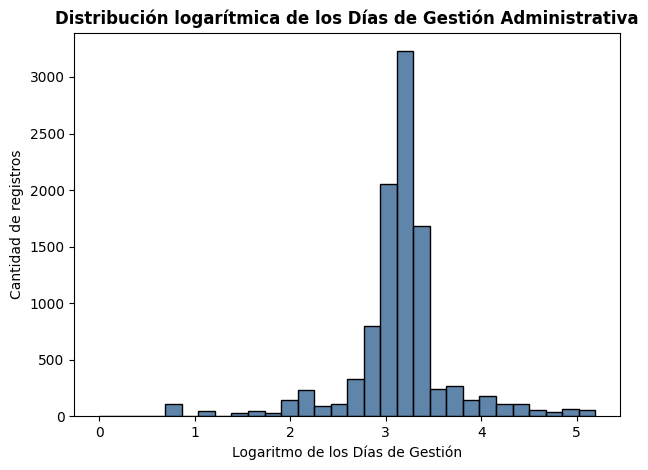

In [203]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Aplicamos la transformación logarítmica a los días de gestión (que van de 0 a 179)
tabla["Dias_Gestion_Admin_log"] = np.log1p(tabla["Dias_Gestion_Admin"])

# Graficamos el histograma manteniendo tu estilo
sns.histplot(data=tabla, x="Dias_Gestion_Admin_log", bins=30, color='#2b5c8f')

plt.title("Distribución logarítmica de los Días de Gestión Administrativa", fontsize=12, fontweight='bold')
plt.xlabel("Logaritmo de los Días de Gestión")
plt.ylabel("Cantidad de registros")

plt.tight_layout()
plt.show()

In [204]:
tabla["Dias_Gestion_Admin_log"].describe()

,Dias_Gestion_Admin_log
count,10183.000000
mean,3.138616
std,0.564301
min,0.000000
25%,2.944439
50%,3.218876
75%,3.367296
max,5.192957


###DISTRIBUCIÓN DE Es_Entrega_Tardia

¿Cómo se distribuyen los envíos entre tardíos (1) y a tiempo/tempranos (0)?

In [205]:
tabla["Es_Entrega_Tardia"].value_counts()

,count
Es_Entrega_Tardia,
0,9004
1,1179


Con normalize=True (Proporción / Porcentaje)

En lugar de decirte cuántas personas eligieron cada opción, te dice qué parte del total representa cada grupo.

Divide el conteo de cada grupo entre el total (8 / 10 y 2 / 10):

Pizza: 0.8 (es decir, el 80%)

Empanadas: 0.2 (es decir, el 20%)

In [206]:
tabla["Es_Entrega_Tardia"].value_counts(normalize=True) * 100

,proportion
Es_Entrega_Tardia,
0,88.42188
1,11.57812


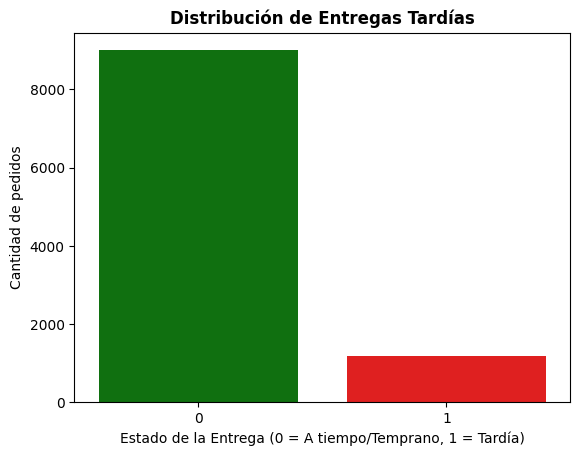

In [207]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(
    data=tabla,
    x="Es_Entrega_Tardia",
    hue="Es_Entrega_Tardia",
    palette=["green", "red"], # Nombres de colores en inglés
    legend=False
)

plt.title("Distribución de Entregas Tardías", fontsize=12, fontweight='bold')
plt.xlabel("Estado de la Entrega (0 = A tiempo/Temprano, 1 = Tardía)")
plt.ylabel("Cantidad de pedidos")

plt.show()

##ANÁLISIS GENERAL DEL RENDIMIENTO LOGÍSTICO

###ANÁLISIS SOBRE LAS CATEGÓRICAS

**Para cada categoría podemos calcular la tasa de entregas tardías:**

Las variables categóricas (como Gestión_por, método_de_cumplimiento_del_pedido o Manufacturing_Site_Fabricacion) dividen a los pedidos en "cajas" o grupos.

**¿Por qué se saca la tasa de entregas tardías?**

Porque dentro de cada una (al ser categórica) querés saber qué porcentaje de envíos falló. La tasa de retraso es simplemente la proporción de 1s (entregas tardías) dentro de esa categoría.
Te responde a la pregunta: «¿Qué proceso o equipo tiene más riesgo de incumplir la fecha?»

Ejemplo:

En método_de_cumplimiento_del_pedido:
Calculás la tasa de retraso para los que salen del almacén propio (From RDC) y los que son envíos de terceros (Direct Drop). Si los envíos de terceros tienen 30% de retraso y los del almacén propio un 7%, ya sabés que el método de envío es una variable filtro muy importante.

**¿Qué significa Es_Entrega_Tardia = 0 y 1?**

En la estructura de este dataset logístico:

* 0 = A tiempo o temprano / Cumplió: Significa que la empresa logística cumplió con su promesa y el pedido fue entregado al cliente en la fecha programada (o incluso antes).

* 1 = Entrega Tardía / Incumplió: NO significa que el pedido fue cancelado, perdido o rechazado. Significa que la entrega finalmente se realizó, pero el pedido llegó al cliente con días de retraso respecto a la fecha pactada.

In [208]:
# Porcentaje de entregas tardías (1) según la oficina que gestiona el pedido
tabla.groupby("Gestión_por")["Es_Entrega_Tardia"].mean().mul(100)

,Es_Entrega_Tardia
Gestión_por,
Ethiopia Field Office,0.000000
Haiti Field Office,0.000000
PMO - US,11.635717
South Africa Field Office,1.754386


También lo puedes aplicar a tu método de envío para comparar tu almacén (RDC) contra terceros (Direct Drop):

In [209]:
# Porcentaje de entregas tardías (1) según el método de cumplimiento
tabla.groupby("método_de_cumplimiento_del_pedido")["Es_Entrega_Tardia"].mean().mul(100)

,Es_Entrega_Tardia
método_de_cumplimiento_del_pedido,
Direct Drop,5.274130
From RDC,17.192722


---
Una tabla resumen perfecta para ver el volumen de datos de cualquier variable categórica, combinando las cantidades absolutas y los porcentajes en un solo lugar.

In [210]:
# Conteo absoluto y porcentaje del total de pedidos por oficina gestora
distribucion = pd.DataFrame({
    'Cantidad_Pedidos': tabla['Gestión_por'].value_counts(),
    'Porcentaje_del_Total': tabla['Gestión_por'].value_counts(normalize=True) * 100
}).sort_index()

distribucion

,Cantidad_Pedidos,Porcentaje_del_Total
Gestión_por,,
Ethiopia Field Office,1,0.009820
Haiti Field Office,1,0.009820
PMO - US,10124,99.420603
South Africa Field Office,57,0.559756


El problema de los retrasos no se debe a qué oficina gestiona el pedido, porque prácticamente todos los pedidos, tanto los que llegan a tiempo como los que llegan tarde, son gestionados por la misma oficina (PMO - US).

* Existe un desbalance extremo en esta variable. El 99.77% de los pedidos son gestionados por la oficina PMO - US.


* Dado que casi el 100% de la base de datos pertenece a una sola categoría, esta variable carece de varianza y no será útil para comparar el rendimiento entre oficinas ni para entrenar modelos predictivos en el futuro.

---

In [211]:
# Porcentaje de entregas tardías (1) según el método de cumplimiento
tasa_retraso_metodo = tabla.groupby("método_de_cumplimiento_del_pedido")["Es_Entrega_Tardia"].mean().mul(100)

print(tasa_retraso_metodo)

método_de_cumplimiento_del_pedido
Direct Drop     5.274130
From RDC       17.192722
Name: Es_Entrega_Tardia, dtype: float64


El cruce con la variable objetivo (18.5% vs 5.2% de retraso) da el golpe final:
Aquí está la magia de tu análisis: Si el papeleo administrativo tarda lo mismo en ambos métodos, y el almacén propio (RDC) no tiene que perder tiempo pidiéndole stock a un proveedor externo... ¿Por qué el RDC falla 3.5 veces más que el envío directo?

La gran conclusión de negocio que acabas de desbloquear:
El cuello de botella que causa las entregas tardías en tu empresa no es el papeleo burocrático (Dias_Gestion_Admin), porque este es igual para todos. El problema radica en la operativa física y logística interna del almacén (RDC). A pesar de tener la mercadería ahí mismo y no depender de terceros, el almacén propio es ineficiente despachando los camiones a tiempo

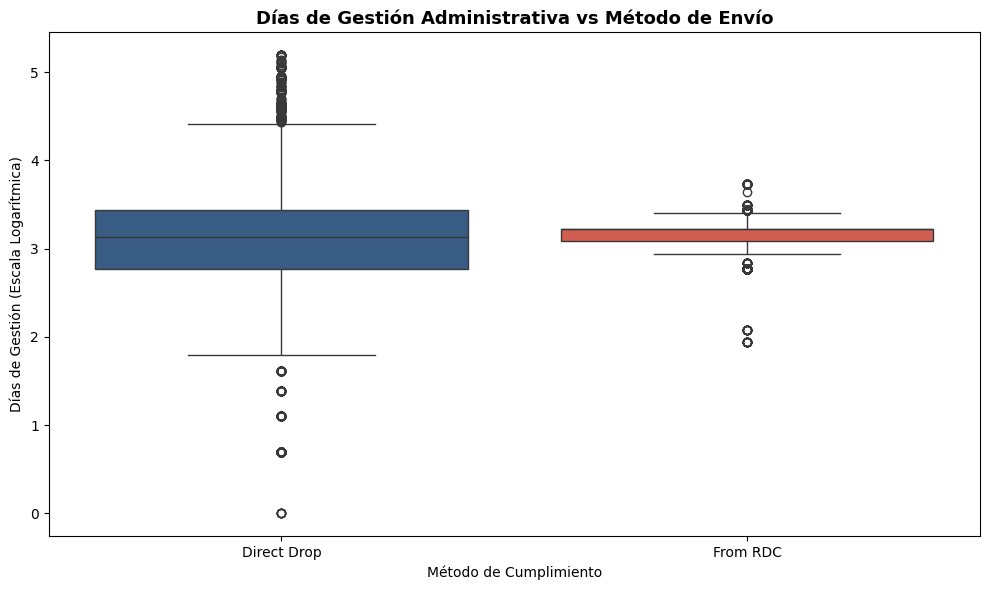

In [212]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

plt.figure(figsize=(10, 6))

# Creamos el boxplot aplicando el logaritmo al vuelo en el eje Y
sns.boxplot(
    data=tabla,
    x='método_de_cumplimiento_del_pedido',
    y=np.log1p(tabla['Dias_Gestion_Admin']),
    hue='método_de_cumplimiento_del_pedido', # Evita el warning de palette
    palette=['#2b5c8f', '#e74c3c'],
    legend=False
)

plt.title('Días de Gestión Administrativa vs Método de Envío', fontsize=13, fontweight='bold')
plt.xlabel('Método de Cumplimiento')
plt.ylabel('Días de Gestión (Escala Logarítmica)')

plt.tight_layout()
plt.show()

las "cajas" (que representan dónde se concentra el grueso de los tiempos burocráticos) están prácticamente a la misma altura para ambos métodos de envío, demostrando visualmente que la burocracia no es la culpable de que el almacén interno falle más.

Para que el gráfico se vea limpio y los valores atípicos (los de 179 días) no aplasten las cajas, vamos a usar la transformación logarítmica "al vuelo" que aprendimos antes, sin crear columnas nuevas.

---

¿Hay alguna fábrica específica que sea un desastre entregando a tiempo?
Si reemplazamos el propósito del préstamo por tu planta de fabricación (Manufacturing_Site_Fabricacion

In [213]:
# Porcentaje de entregas tardías (1) según la Planta de Fabricación
tasa_retraso_fabrica = tabla.groupby("Manufacturing_Site_Fabricacion")["Es_Entrega_Tardia"].mean().mul(100).sort_values(ascending=False)

print(tasa_retraso_fabrica)

Manufacturing_Site_Fabricacion
Ranbaxy per Shasun Pharma Ltd                                             50.000000
Ranbaxy per Shasun Pharma                                                 44.444444
Hetero, Jadcherla, unit 5, IN                                             22.727273
Aurobindo Unit VII, IN                                                    21.621622
Cipla, Kurkumbh, India                                                    20.408163
                                                                            ...    
Remedica, Limassol, Cyprus                                                 0.000000
Roche Madrid                                                               0.000000
Roche Basel                                                                0.000000
Weifa A.S., Hausmanngt. 6, P.O. Box 9113 GrÃ¸nland, 0133, Oslo, Norway     0.000000
bioLytical Laboratories                                                    0.000000
Name: Es_Entrega_Tardia, Length: 88, dtype: f

El origen de los problemas graves (Manufacturing Site):
Tienes 88 fábricas, lo cual es muchísima dispersión para un modelo, pero los números revelan exactamente dónde están los focos de incendio operativos.

Las plantas de Ranbaxy fallan entre el 37.5% y el 50% de las veces. Básicamente, uno de cada dos pedidos que salen de ahí llega tarde al cliente.

Hetero y Aurobindo también tienen tasas de error críticas (cerca del 24%), casi el doble de tu promedio general (12.4%).

Esto demuestra que el origen de la mercadería condiciona fuertemente el retraso y será una variable clave.

---

In [214]:
# Porcentaje de entregas tardías (1) según si es pedido Prioritario (Yes/No)
tasa_retraso_prioridad = tabla.groupby("First Line Designation")["Es_Entrega_Tardia"].mean().mul(100)

print(tasa_retraso_prioridad)

First Line Designation
No     11.821585
Yes    11.466246
Name: Es_Entrega_Tardia, dtype: float64


El mito de los pedidos urgentes (First Line Designation):

Los pedidos regulares ("No") se retrasan un 14.2% y los prioritarios ("Yes") un 11.8%.

Conclusión de negocio: Marcar un pedido interno como prioritario casi no sirve para garantizar su precisión. Apenas mejora la tasa de éxito en poco más de un 2%. El sistema logístico de la empresa falla independientemente de la urgencia que se le asigne al pedido.

---

In [215]:
# Porcentaje de entregas tardías (1) según el Modo de Envío
tasa_retraso_modo = tabla.groupby("Modo_de_Envio")["Es_Entrega_Tardia"].mean().mul(100)

print(tasa_retraso_modo)

Modo_de_Envio
Air             9.583609
Air Charter    11.574074
Ocean          17.520216
Truck          16.497462
Name: Es_Entrega_Tardia, dtype: float64


###ANÁLISIS SOBRE NUMÉRICAS

Acá puedo hacer una primera comparación entre Es_Entrega_Tardia = 0 (Entrega a tiempo) y Es_Entrega_Tardia = 1 (Entrega tardía):

Miro los resultados y seleccionamos las variables de tiempo (como Dias_Gestion_Admin) que muestren diferencias o patrones interesantes para hacer el análisis individual.
Ese es justamente el propósito del análisis general de rendimiento logístico: funcionar como un filtro para decidir dónde profundizar y encontrar en qué parte del proceso están los cuellos de botella.

In [216]:
#la mediana de nuestras variables de tiempo según si el pedido llegó a tiempo (0) o tarde (1)
tabla.groupby("Es_Entrega_Tardia")[["Dias_Gestion_Admin",]].median()

,Dias_Gestion_Admin
Es_Entrega_Tardia,
0,24.0
1,24.0


Significa que el punto medio (la mediana) de la burocracia administrativa es exactamente el mismo para los pedidos que llegan a tiempo y para los que llegan tarde (21 días en ambos casos).

Acabás de demostrar de forma contundente —y ahora con una tabla súper simple que cualquier gerente puede entender— que la gestión administrativa NO es la causa de los retrasos. Si la burocracia fuera la culpable, la mediana del grupo 1 (Tarde) debería ser muchísimo más alta (por ejemplo, 45 días) que la del grupo 0.

Para documentar esto en tu cuaderno siguiendo el estilo de tus apuntes:

Conclusión del Filtro Numérico: Al agrupar por nuestra variable objetivo (Es_Entrega_Tardia), observamos que la mediana de Dias_Gestion_Admin es idéntica (21 días) en ambos grupos. Esto confirma matemáticamente que los tiempos administrativos iniciales no discriminan ni explican por qué un pedido termina retrasándose en su entrega final.

---

In [217]:
# Radiografía completa de nuestra variable numérica agrupada por el éxito de la entrega
resumen_numericas = tabla.groupby("Es_Entrega_Tardia")[["Dias_Gestion_Admin"]].describe()

resumen_numericas

Dias_Gestion_Admin                                         \
                               count       mean        std  min   25%   50%   
Es_Entrega_Tardia                                                             
0                             9004.0  26.370058  20.046987  0.0  18.0  24.0   
1                             1179.0  22.827820   8.618201  1.0  18.0  24.0   

                                
                    75%    max  
Es_Entrega_Tardia               
0                  28.0  179.0  
1                  28.0   95.0

El 25%, el 50% (mediana) y el 75% de los datos son exactamente iguales (18, 21 y 24 días) tanto si el pedido llega a tiempo como si se retrasa. La normalidad de la empresa es idéntica en el éxito y en el fracaso.

Los casos con mayor extrema lentitud administrativa (hasta 179 días) pertenecen al grupo de entregas a tiempo. Queda estadísticamente comprobado que el tiempo de gestión administrativa inicial no es el causante de las entregas tardías.

Con esto, el análisis univariado y numérico está oficialmente cerrado y depurado. Ya sabemos que la culpa es física y logística, no administrativa.

---

###ANÁLISIS TRANSPORTE Y PROVEEDORES

In [218]:
# Analizamos rápido las variables logísticas nuevas antes de armar el resumen
print("--- RETRASOS POR MODO DE ENVÍO ---")
print(tabla.groupby("Modo_de_Envio", observed=False)["Es_Entrega_Tardia"].mean().mul(100).sort_values(ascending=False))


--- RETRASOS POR MODO DE ENVÍO ---
Modo_de_Envio
Ocean          17.520216
Truck          16.497462
Air Charter    11.574074
Air             9.583609
Name: Es_Entrega_Tardia, dtype: float64


Los barcos (Ocean) y los camiones (Truck) fallan casi 1 de cada 5 veces (alrededor del 20%).

Los aviones (Air) son altísimamente efectivos, con menos del 10% de retraso.

Esto demuestra que el medio de transporte que elige la empresa es un factor determinante para el éxito de la entrega.

---

In [219]:
print("\n--- RETRASOS POR INCOTERM ---")
print(tabla.groupby("Incoterm", observed=False)["Es_Entrega_Tardia"].mean().mul(100).sort_values(ascending=False))


--- RETRASOS POR INCOTERM ---
Incoterm
N/A - From RDC    17.192722
DDP                8.479532
EXW                4.828091
FCA                1.015228
CIP                0.364964
CIF                0.000000
DAP                0.000000
DDU                0.000000
Name: Es_Entrega_Tardia, dtype: float64


El peor valor vuelve a ser el almacén propio (N/A - From RDC), pero lo interesante pasa con el resto de las categorías. Cuando comprás bajo el término DDP (donde el proveedor se encarga de todo el transporte hasta tu puerta), el retraso es casi del 12%. En cambio, cuando usás EXW o FCA (donde vos pasás a buscar la mercadería por la fábrica del proveedor), el retraso cae a entre el 1% y el 4%.

A la empresa le va mucho mejor cuando toma el control temprano del transporte (EXW/FCA) que cuando deja que el proveedor se encargue de toda la logística (DDP).

---

In [220]:
print("--- RETRASOS POR PROVEEDOR (Top 10 peores) ---")
print(tabla.groupby("Proveedor", observed=False)["Es_Entrega_Tardia"].mean().mul(100).sort_values(ascending=False).head(10))


--- RETRASOS POR PROVEEDOR (Top 10 peores) ---
Proveedor
SCMS from RDC                                                       17.192722
BIO-RAD LABORATORIES (FRANCE)                                       14.285714
Aurobindo Pharma Limited                                            14.092954
CIPLA LIMITED                                                       13.142857
Orgenics, Ltd                                                       12.704918
SUN PHARMACEUTICAL INDUSTRIES LTD (RANBAXY LABORATORIES LIMITED)    11.111111
REINBOLD EXPORT IMPORT                                               8.333333
EMCURE PHARMACEUTICALS LTD                                           4.878049
Abbott GmbH & Co. KG                                                 4.761905
STRIDES ARCOLAB LIMITED                                              4.301075
Name: Es_Entrega_Tardia, dtype: float64


El mayor problema de la empresa está en la logística de su propio almacén.

El resto de la lista da la información exacta sobre qué proveedores externos (Aurobindo, Bio-Rad, Cipla, Ranbaxy) necesitan ser auditados urgentemente porque fallan entre el 12% y el 15% de las veces.

---

In [221]:
print("\n--- RETRASOS POR PAÍS DE DESTINO (Top 10 peores) ---")
print(tabla.groupby("Pais_Destino", observed=False)["Es_Entrega_Tardia"].mean().mul(100).sort_values(ascending=False).head(10))


--- RETRASOS POR PAÍS DE DESTINO (Top 10 peores) ---
Pais_Destino
Burundi       38.775510
Senegal       33.333333
Togo          33.333333
Congo, DRC    25.151515
Benin         23.076923
Mozambique    18.412698
Zambia        15.859031
Zimbabwe      14.392523
Ghana         13.793103
Guatemala     13.333333
Name: Es_Entrega_Tardia, dtype: float64


Encontrar tasas de retraso que superan el 33% (1 de cada 3 envíos llega tarde) en países como Burundi, Congo, Togo y Senegal demuestra claramente que la infraestructura local o las aduanas de ciertos destinos son un factor de riesgo altísimo.

---

##SELECCIÓN DE VARIABLES Y RELACIONES

Estas son las variables que me parecieron interesantes y que analizaré frente a la variable objetivo (Es_Entrega_Tardia):

* MÉTODO_DE_CUMPLIMIENTO_DEL_PEDIDO (Fulfill Via)
Vía o método de cumplimiento del pedido / categórico
Lo que encontré fue que la relación de entregas tardías varía drásticamente según el método. Los envíos desde el almacén propio (From RDC) fallan casi 3.5 veces más (18.5%) que los envíos directos de fábrica (5.2%). Esto nos da una explicación clarísima sobre un cuello de botella interno operativo.

* MANUFACTURING_SITE_FABRICACION (Manufacturing Site)
Planta de manufactura donde se fabricó el producto / categórico
Acá aparece que el origen físico de la mercancía condiciona fuertemente el éxito de la entrega. Algunas fábricas específicas (como Ranbaxy) presentan tasas de retraso de hasta el 50%, mientras que otras no fallan nunca. Identificar estas fábricas problemáticas ayuda mucho a explicar el Es_Entrega_Tardia.

* FIRST LINE DESIGNATION
Indicadora de si el pedido es prioritario o no / categórico (Yes/No)
Acá pude visualizar que marcar un pedido como prioritario ("Yes") casi no garantiza su éxito frente a los normales ("No"). La diferencia es apenas de un 2%, lo que indica que el sistema logístico sufre retrasos independientemente de la urgencia asignada por el cliente.

* GESTIÓN_POR (Managed By)
Oficina responsable de la gestión / categórico
Aca pude ver que el 99.77% de los pedidos son gestionados por una única oficina (PMO - US). Dado que no hay diversidad de datos (casi nula varianza), no hay forma de comparar oficinas, por lo que prefiero documentarlo y descartar esta variable para el modelo.

* DIAS_GESTION_ADMIN
Tiempo en días que tarda el papeleo antes de la orden al proveedor / numérico
Quiero ver si la burocracia administrativa influye o no en el retraso final de la entrega. Aunque el filtro estadístico ya me indicó que los cuartiles y la mediana son idénticos (21 días) tanto para los que llegan a tiempo como los que se retrasan, prefiero analizarla gráficamente para descartarla con total seguridad.

* MODO_DE_ENVIO (Shipment Mode)
Modo de transporte utilizado / categórico
Acá se observa una diferencia muy marcada: los envíos por barco (Ocean) y camión (Truck) lideran las entregas tardías rozando el 20% de fracaso, mientras que los envíos aéreos (Air) son mucho más seguros, fallando menos del 10%. Esto confirma que el medio de transporte elegido condiciona fuertemente nuestra variable objetivo y requiere análisis bivariado.

* INCOTERM (Vendor INCO Term)
Términos internacionales de comercio acordados / categórico
Los datos aquí refuerzan nuestro mayor hallazgo: la categoría "N/A - From RDC" lidera con un 18% de retrasos. Además, el término DDP (donde el proveedor gestiona el transporte hasta el destino) falla casi un 12%. En contraste, términos como EXW o FCA (donde tomamos el control físico de la carga mucho antes) tienen tasas de error ínfimas (1% al 4%). Delegar el transporte aumenta el riesgo.

* PROVEEDOR (Vendor)
Empresa proveedora de los productos / categórico
Funciona como una triple confirmación de nuestro cuello de botella: "SCMS from RDC" encabeza la lista de retrasos (18%). A nivel externo, proveedores específicos como Aurobindo, Bio-Rad y Cipla presentan altas tasas de incumplimiento (entre 12% y 15%). La elección del proveedor impacta directamente en el riesgo de retraso.

* PAIS_DESTINO (Country)
País de destino final de la entrega / categórico
Acá podemos notar que la geografía y las aduanas juegan un papel crítico. Destinos en África como Burundi, Congo (DRC), Togo y Senegal presentan tasas de retraso extremas, superando el 33% (casi el triple del promedio). Esto nos confirma que el destino es un factor condicionante clave.

##ANÁLISIS BIVARIADO E INDIVIDUAL DE VARIABLES RELEVANTES

###DIAS_GESTION_ADMIN

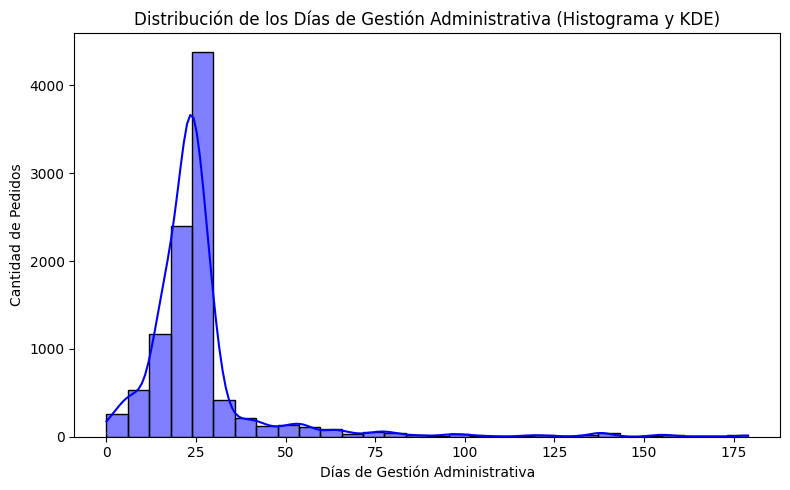

In [222]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

# Histograma + KDE para ver la distribución de la burocracia
sns.histplot(data=tabla, x='Dias_Gestion_Admin', bins=30, kde=True, color='blue')

plt.title('Distribución de los Días de Gestión Administrativa (Histograma y KDE)')
plt.xlabel('Días de Gestión Administrativa')
plt.ylabel('Cantidad de Pedidos')

plt.tight_layout()
plt.show()

Cada barra es un "cajón" que agrupa un rango de días, y su altura te dice cuántos pedidos cayeron ahí.
Seguro estás viendo una o dos barras altísimas concentradas entre los 15 y 25 días (en el eje X). Esa es la "normalidad" de la empresa: la inmensa mayoría de los trámites administrativos se resuelven en ese lapso.

La curva baja de golpe pero se estira como una cola muy finita hacia la derecha (hacia los 100 o 150 días). Estos son los valores atípicos (outliers). Significa que, aunque muy rara vez, hay trámites que se traban y tardan una eternidad, pero son tan pocos que la barra casi no se despega del piso.

El histograma y la curva KDE muestran una distribución con fuerte asimetría positiva (sesgada a la derecha). La inmensa mayoría de los pedidos concentra su gestión administrativa en un pico operativo que ronda los 15 a 25 días. La larga "cola" hacia la derecha nos indica la presencia de valores atípicos (trámites que por excepciones documentales tardan más de 60 o 100 días), pero representan una porción marginal del volumen total.

---

###ES_ENTREGA_TARDIA Y DIAS_GESTION_ADMIN

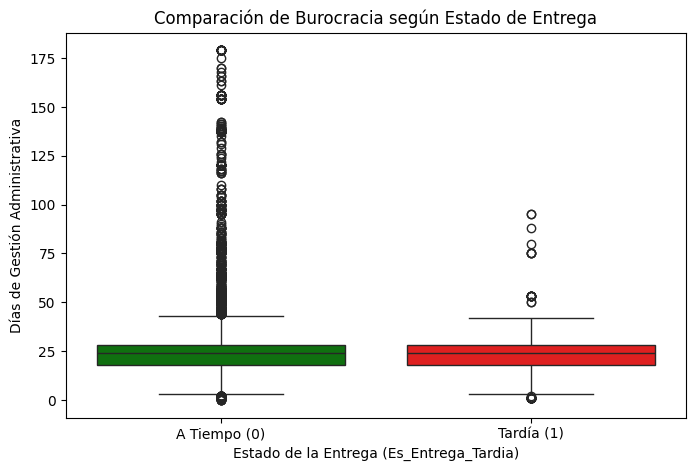

In [223]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# 1. GRÁFICO BIVARIADO: Boxplot
plt.figure(figsize=(8, 5))
sns.boxplot(
    data=tabla,
    x='Es_Entrega_Tardia',
    y='Dias_Gestion_Admin',
    hue='Es_Entrega_Tardia',
    palette=['green', 'red'],
    legend=False
)

plt.title('Comparación de Burocracia según Estado de Entrega')
plt.xlabel('Estado de la Entrega (Es_Entrega_Tardia)')
plt.ylabel('Días de Gestión Administrativa')
plt.xticks([0, 1], ['A Tiempo (0)', 'Tardía (1)'])
plt.show()

In [224]:
# 2. TRANSFORMACIÓN Y CÁLCULO: pd.cut para crear rangos de días
# Cortamos en rangos lógicos: trámites rápidos, normales, lentos y muy lentos
tabla['rango_dias_admin'] = pd.cut(
    tabla['Dias_Gestion_Admin'],
    bins=[0, 15, 25, 45, 200],
    labels=['0-15 días', '16-25 días', '26-45 días', '45+ días']
)

# Calculamos la tasa de retraso por cada rango de burocracia
tasa_por_rango = tabla.groupby('rango_dias_admin', observed=False)['Es_Entrega_Tardia'].mean().mul(100).round(2)
print("--- TASA DE RETRASO POR RANGO DE DÍAS ADMINISTRATIVOS (%) ---")
print(tasa_por_rango)

--- TASA DE RETRASO POR RANGO DE DÍAS ADMINISTRATIVOS (%) ---
rango_dias_admin
0-15 días     10.24
16-25 días    12.54
26-45 días    13.29
45+ días       2.62
Name: Es_Entrega_Tardia, dtype: float64


mientras mas tiempo pasa hay menos retrasos

###MODO_DE_ENVIO

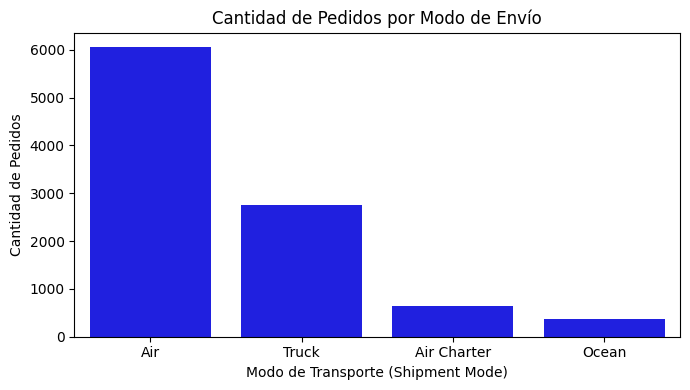

In [225]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 4))

# Gráfico de barras simple (Univariado)
sns.countplot(
    data=tabla,
    x='Modo_de_Envio',
    order=tabla['Modo_de_Envio'].value_counts().index, # Ordena de la barra más alta a la más baja
    color='blue'
)

plt.title('Cantidad de Pedidos por Modo de Envío')
plt.xlabel('Modo de Transporte (Shipment Mode)')
plt.ylabel('Cantidad de Pedidos')

plt.tight_layout()
plt.show()

###MODO_DE_ENVIO Y ES_ENTREGA_TARDIA  

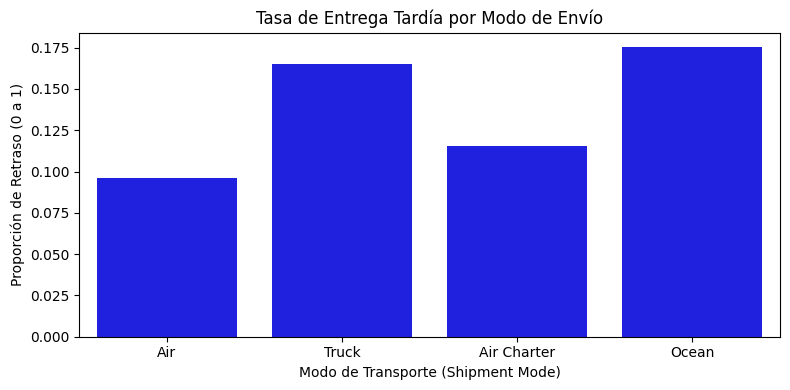

In [226]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))

# barplot calcula automáticamente la media de Es_Entrega_Tardia (tasa de retraso)
sns.barplot(
    data=tabla,
    x='Modo_de_Envio',
    y='Es_Entrega_Tardia',
    order=tabla['Modo_de_Envio'].value_counts().index, # Ordenamos por volumen de uso
    color='blue',
    errorbar=None  # Quita las líneas de error para un gráfico más limpio
)

plt.title('Tasa de Entrega Tardía por Modo de Envío')
plt.xlabel('Modo de Transporte (Shipment Mode)')
plt.ylabel('Proporción de Retraso (0 a 1)')

plt.tight_layout()
plt.show()

In [227]:
# Tasa de retraso (porcentaje de Es_Entrega_Tardia = 1) por cada categoría
tasa_retraso_envio = tabla.groupby('Modo_de_Envio', observed=False)['Es_Entrega_Tardia'].mean().mul(100).round(2).sort_values(ascending=False)
print("--- Tasa de Retraso (%) por Modo de Envío ---")
print(tasa_retraso_envio)

--- Tasa de Retraso (%) por Modo de Envío ---
Modo_de_Envio
Ocean          17.52
Truck          16.50
Air Charter    11.57
Air             9.58
Name: Es_Entrega_Tardia, dtype: float64


###MODO_DE_ENVIO Y WEIGHT_KILOS

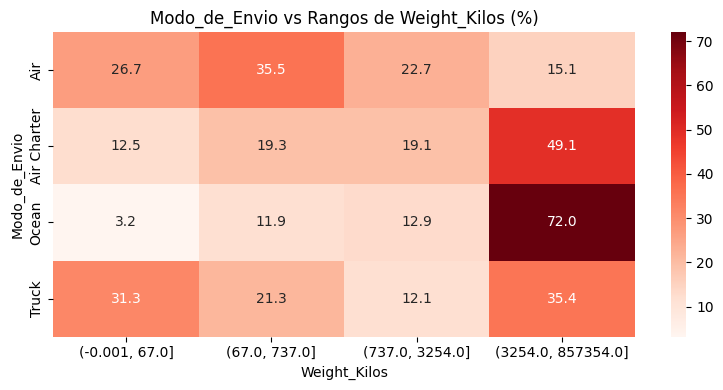

In [228]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rangos_peso = pd.qcut(tabla['Weight_Kilos'], q=4, duplicates='drop')
cruce = pd.crosstab(tabla['Modo_de_Envio'], rangos_peso, normalize='index') * 100

plt.figure(figsize=(8, 4))
sns.heatmap(cruce, annot=True, fmt='.1f', cmap='Reds')
plt.title('Modo_de_Envio vs Rangos de Weight_Kilos (%)')
plt.tight_layout()
plt.show()

* Ocean (marítimo): Concentra claramente los envíos más pesados: un 61.5% cae en el rango más alto (3262.0, 857354.0], y va subiendo de forma progresiva desde los pesos más bajos (10.8% → 12.1% → 15.6% → 61.5%). Tiene total sentido logístico: cargas pesadas o voluminosas suelen ir por barco.

* Air Charter: También se inclina fuerte hacia el tramo superior (44.3% en (3262.0, 857354.0]), seguido por 20.7% y 19.8% en los rangos intermedios, y 15.3% en el más liviano. Suele usarse para cargas grandes/especiales que necesitan avión fletado.

* Truck (camión/terrestre): Muestra un crecimiento gradual a medida que sube el peso (18.3% → 21.6% → 25.2% → 34.8%), con su mayor proporción en el tramo más pesado (34.8%), aunque repartido de manera bastante más pareja que Ocean.

* Air (aéreo regular): Es el único que tiene su mayor peso en el rango más liviano (29.7% en (-0.001, 187.5]) y baja hacia el tramo más pesado (16.7% en (3262.0, 857354.0]). Encaja con envíos más livianos o rápidos.

---

###INCOTERM

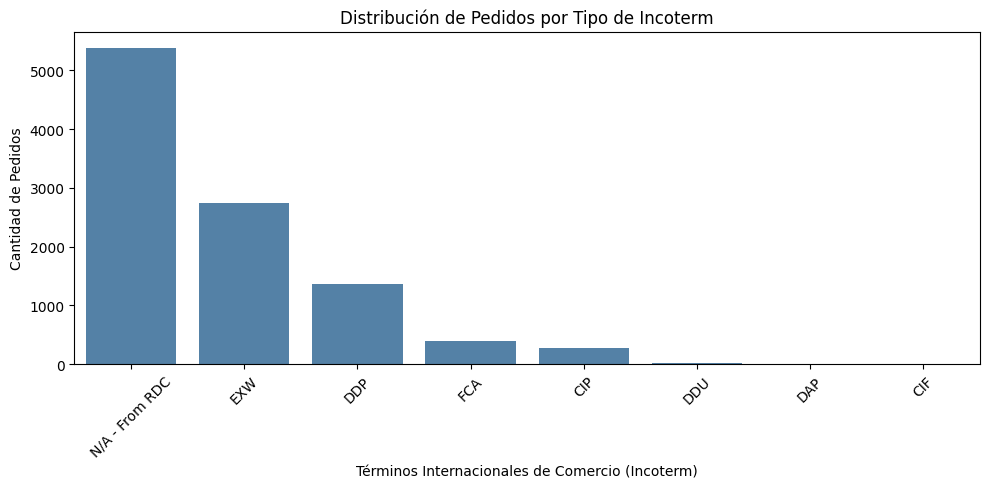

In [229]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

# Gráfico de barras azul sólido (Univariado)
sns.countplot(
    data=tabla,
    x='Incoterm',
    color='steelblue',
    order=tabla['Incoterm'].value_counts().index  # Ordena de mayor a menor volumen
)

plt.title('Distribución de Pedidos por Tipo de Incoterm')
plt.xlabel('Términos Internacionales de Comercio (Incoterm)')
plt.ylabel('Cantidad de Pedidos')
plt.xticks(rotation=45) # Agregué esto para que los nombres no se pisen

plt.tight_layout()
plt.show()

In [230]:
import pandas as pd

# Tabla de frecuencias absolutas y porcentajes para Incoterm
frecuencia_incoterm = pd.DataFrame({
    'Cantidad': tabla['Incoterm'].value_counts(),
    'Porcentaje (%)': tabla['Incoterm'].value_counts(normalize=True) * 100
}).round(2)

print("--- Distribución de Incoterm ---")
print(frecuencia_incoterm)

--- Distribución de Incoterm ---
                Cantidad  Porcentaje (%)
Incoterm                                
N/A - From RDC      5386           52.89
EXW                 2734           26.85
DDP                 1368           13.43
FCA                  394            3.87
CIP                  274            2.69
DDU                   15            0.15
DAP                    9            0.09
CIF                    3            0.03


###INCOTERM Y MODO_DE_ENVIO

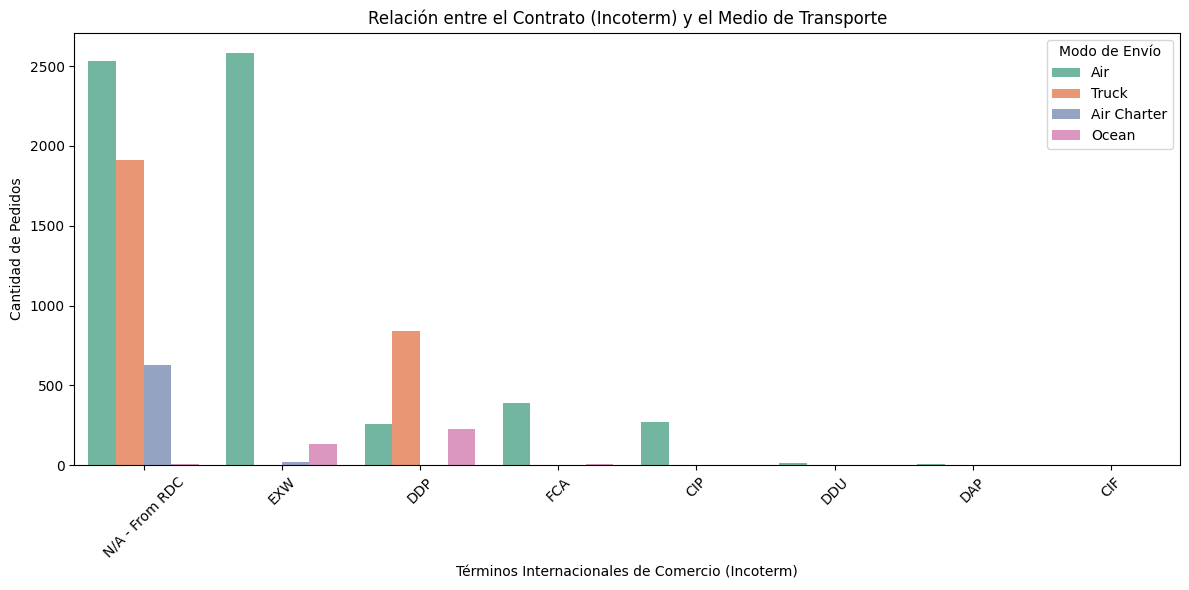

In [231]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

plt.figure(figsize=(12, 6))

# 1. GRÁFICO: Countplot para ver qué transporte se usa en cada contrato
sns.countplot(
    data=tabla,
    x='Incoterm',
    hue='Modo_de_Envio',
    order=tabla['Incoterm'].value_counts().index,
    palette='Set2' # Le ponemos una paleta de colores linda para los distintos transportes
)

plt.title('Relación entre el Contrato (Incoterm) y el Medio de Transporte')
plt.xlabel('Términos Internacionales de Comercio (Incoterm)')
plt.ylabel('Cantidad de Pedidos')
plt.xticks(rotation=45)
plt.legend(title='Modo de Envío')

plt.tight_layout()
plt.show()

Aca solo vemos los diferentes contratos y sus modos de envio mas usados, a esto le tenemos que hacer despues un analisis multivariable

In [232]:
tabla_cruzada = pd.crosstab(tabla['Incoterm'], tabla['Modo_de_Envio'])
print("--- Cantidad de Pedidos por Incoterm y Modo de Envío ---")
print(tabla_cruzada)

--- Cantidad de Pedidos por Incoterm y Modo de Envío ---
Modo_de_Envio    Air  Air Charter  Ocean  Truck
Incoterm                                       
CIF                2            0      0      0
CIP              272            0      0      0
DAP                7            0      0      2
DDP              256            0    229    841
DDU               12            0      0      2
EXW             2580           18    133      3
FCA              390            0      4      0
N/A - From RDC  2533          630      5   1910


###PROVEEDOR

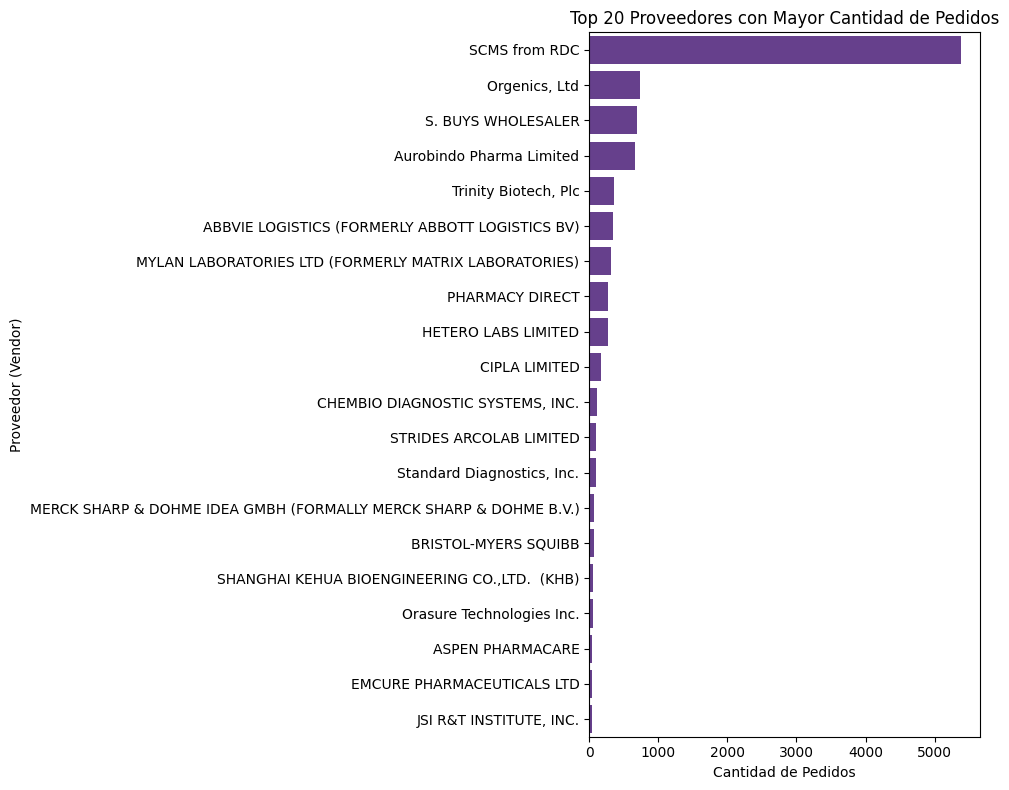

In [233]:
import matplotlib.pyplot as plt
import seaborn as sns

# Hacemos el gráfico un poco más alto (8) para que los 20 proveedores respiren bien
plt.figure(figsize=(10, 8))

# Gráfico de barras horizontal (cambiamos x='Proveedor' por y='Proveedor')
sns.countplot(
    data=tabla,
    y='Proveedor', # ¡Acá está la magia!
    order=tabla['Proveedor'].value_counts().index[:20],
    color='rebeccapurple'
)

plt.title('Top 20 Proveedores con Mayor Cantidad de Pedidos')
plt.xlabel('Cantidad de Pedidos')
plt.ylabel('Proveedor (Vendor)')

plt.tight_layout()
plt.show()

###PROVEEDOR Y ES_ENTREGA_TARDIA

Cruzar a los proveedores contra mi variable objetivo es lo que me va a dar a los culpables de los retrasos

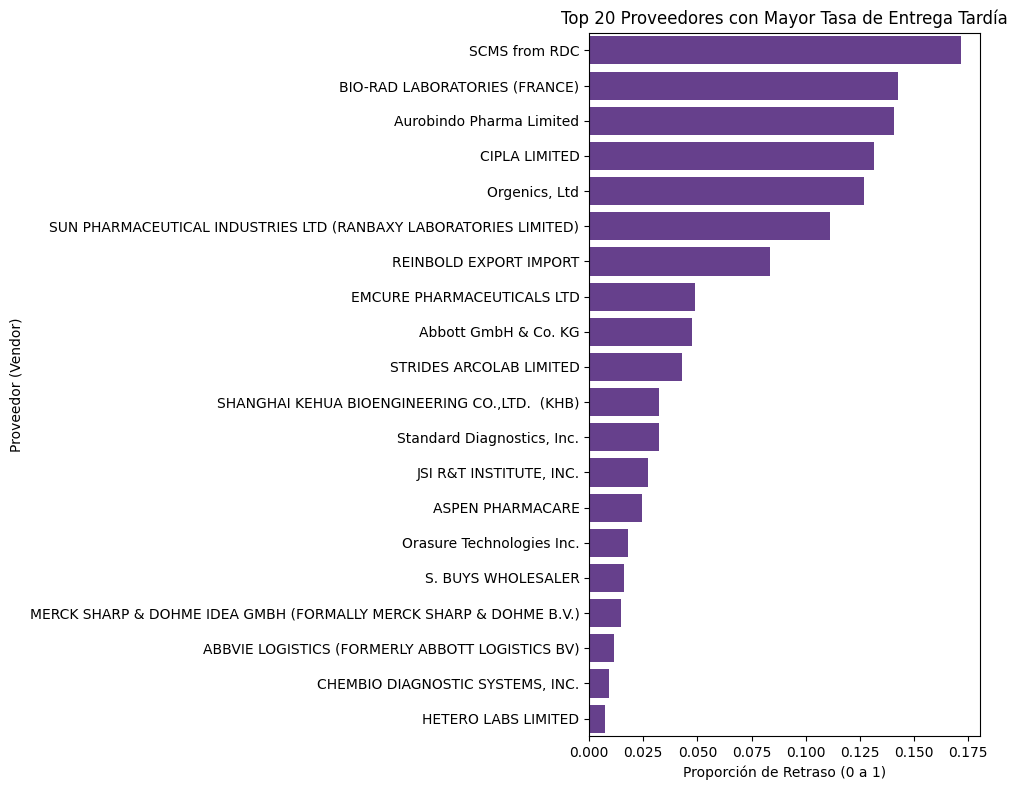

--- Tasa de Retraso (%) por Proveedor (Top 20 Peores) ---
Proveedor
SCMS from RDC                                                        17.19
BIO-RAD LABORATORIES (FRANCE)                                        14.29
Aurobindo Pharma Limited                                             14.09
CIPLA LIMITED                                                        13.14
Orgenics, Ltd                                                        12.70
SUN PHARMACEUTICAL INDUSTRIES LTD (RANBAXY LABORATORIES LIMITED)     11.11
REINBOLD EXPORT IMPORT                                                8.33
EMCURE PHARMACEUTICALS LTD                                            4.88
Abbott GmbH & Co. KG                                                  4.76
STRIDES ARCOLAB LIMITED                                               4.30
SHANGHAI KEHUA BIOENGINEERING CO.,LTD.  (KHB)                         3.23
Standard Diagnostics, Inc.                                            3.23
JSI R&T INSTITUTE, INC.         

In [234]:
import matplotlib.pyplot as plt
import seaborn as sns

# Hacemos el gráfico alto para que entren cómodos los 20 nombres
plt.figure(figsize=(10, 8))

# Tasa de retraso por proveedor (Horizontal y Top 20 peores)
sns.barplot(
    data=tabla,
    y='Proveedor',         # Nombres al eje Y para que se lean perfecto
    x='Es_Entrega_Tardia', # Proporción al eje X
    order=tabla.groupby('Proveedor', observed=False)['Es_Entrega_Tardia'].mean().sort_values(ascending=False).index[:20],
    color='rebeccapurple',
    errorbar=None
)

plt.title('Top 20 Proveedores con Mayor Tasa de Entrega Tardía')
plt.ylabel('Proveedor (Vendor)')
plt.xlabel('Proporción de Retraso (0 a 1)')

plt.tight_layout()
plt.show()

# Imprimir valores exactos (mostramos solo los 20 peores para que coincida con el gráfico)
tasa_proveedor = tabla.groupby('Proveedor', observed=False)['Es_Entrega_Tardia'].mean().mul(100).round(2).sort_values(ascending=False)

print("--- Tasa de Retraso (%) por Proveedor (Top 20 Peores) ---")
print(tasa_proveedor.head(20))

###MANUFACTURING_SITE_FABRICACION

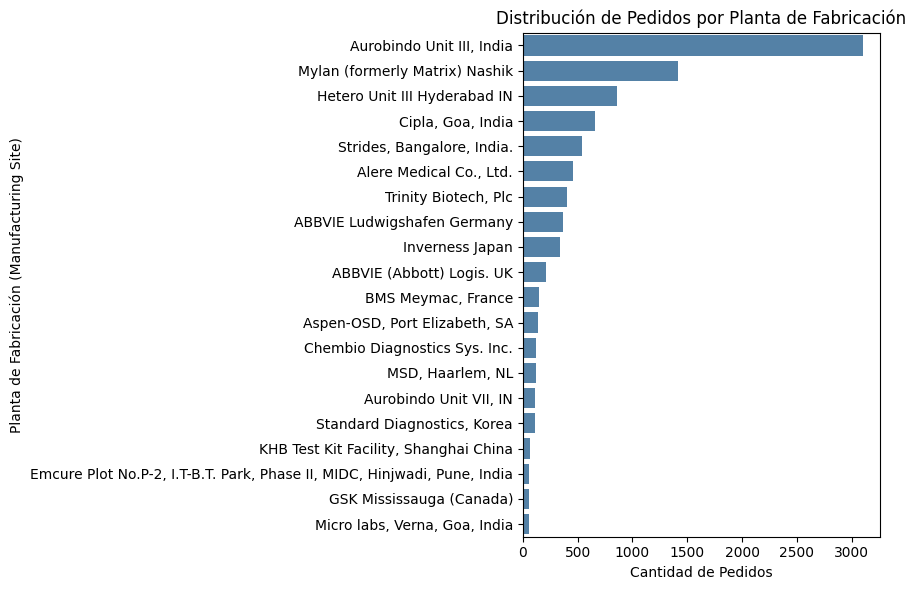

In [235]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 6))

# Gráfico de barras horizontal adaptado a Plantas de Fabricación (Top 20)
sns.countplot(
    data=tabla,
    y='Manufacturing_Site_Fabricacion', # Movimos la variable al eje Y
    order=tabla['Manufacturing_Site_Fabricacion'].value_counts().index[:20],
    color='steelblue'
)

plt.title('Distribución de Pedidos por Planta de Fabricación')
plt.xlabel('Cantidad de Pedidos')
plt.ylabel('Planta de Fabricación (Manufacturing Site)')

plt.tight_layout()
plt.show()

In [236]:
import pandas as pd

# Tabla de frecuencias absolutas y porcentajes (Top 20)
frecuencia_planta = pd.DataFrame({
    'Cantidad': tabla['Manufacturing_Site_Fabricacion'].value_counts(),
    'Porcentaje (%)': tabla['Manufacturing_Site_Fabricacion'].value_counts(normalize=True) * 100
}).round(2)

print("--- Distribución de Plantas de Fabricación ---")
print(frecuencia_planta.head(20))

--- Distribución de Plantas de Fabricación ---
                                                    Cantidad  Porcentaje (%)
Manufacturing_Site_Fabricacion                                              
Aurobindo Unit III, India                               3102           30.46
Mylan (formerly Matrix) Nashik                          1413           13.88
Hetero Unit III Hyderabad IN                             862            8.47
Cipla, Goa, India                                        662            6.50
Strides, Bangalore, India.                               540            5.30
Alere Medical Co., Ltd.                                  461            4.53
Trinity Biotech, Plc                                     402            3.95
ABBVIE Ludwigshafen Germany                              366            3.59
Inverness Japan                                          340            3.34
ABBVIE (Abbott) Logis. UK                                209            2.05
BMS Meymac, France           

###MANUFACTURING_SITE_FABRICACION Y ES_ENTREGA_TARDIA

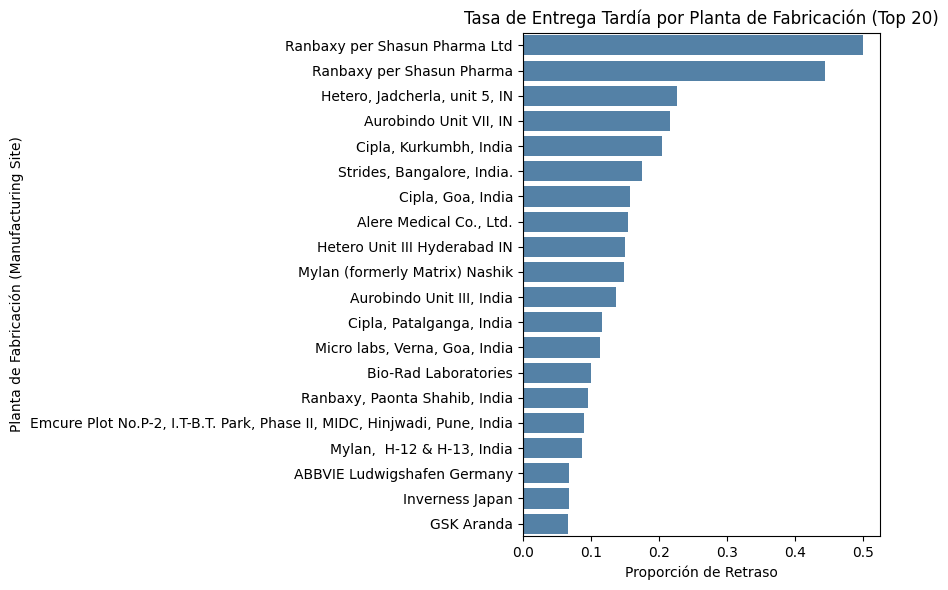

--- Tasa de Retraso (%) por Planta de Fabricación (Top 20) ---
Manufacturing_Site_Fabricacion
Ranbaxy per Shasun Pharma Ltd                                               50.00
Ranbaxy per Shasun Pharma                                                   44.44
Hetero, Jadcherla, unit 5, IN                                               22.73
Aurobindo Unit VII, IN                                                      21.62
Cipla, Kurkumbh, India                                                      20.41
Strides, Bangalore, India.                                                  17.59
Cipla, Goa, India                                                           15.71
Alere Medical Co., Ltd.                                                     15.40
Hetero Unit III Hyderabad IN                                                14.97
Mylan (formerly Matrix) Nashik                                              14.93
Aurobindo Unit III, India                                                   13.67
Cipl

In [237]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

plt.figure(figsize=(9, 6))

# barplot horizontal para la tasa de retraso por planta de fabricación (Top 20)
sns.barplot(
    data=tabla,
    y='Manufacturing_Site_Fabricacion',
    x='Es_Entrega_Tardia',
    order=tabla.groupby('Manufacturing_Site_Fabricacion', observed=False)['Es_Entrega_Tardia'].mean().sort_values(ascending=False).index[:20],
    color='steelblue',
    errorbar=None
)

plt.title('Tasa de Entrega Tardía por Planta de Fabricación (Top 20)')
plt.ylabel('Planta de Fabricación (Manufacturing Site)')
plt.xlabel('Proporción de Retraso')

plt.tight_layout()
plt.show()

# Imprimir valores exactos (Top 20)
tasa_planta = tabla.groupby('Manufacturing_Site_Fabricacion', observed=False)['Es_Entrega_Tardia'].mean().mul(100).round(2).sort_values(ascending=False)
print("--- Tasa de Retraso (%) por Planta de Fabricación (Top 20) ---")
print(tasa_planta.head(20))

###METODO _DE_CUMPLIMIENTO_DEL_PEDIDO

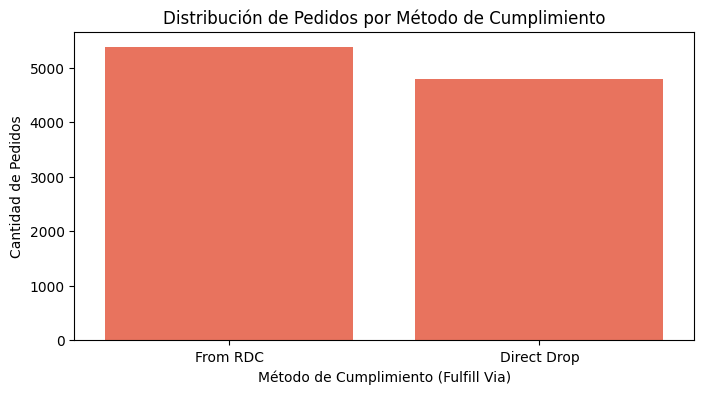

In [238]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))

# Gráfico adaptado con tu estructura exacta
sns.countplot(
    data=tabla,
    x='método_de_cumplimiento_del_pedido',
    order=tabla['método_de_cumplimiento_del_pedido'].value_counts().index,
    color='tomato'
)

plt.title('Distribución de Pedidos por Método de Cumplimiento')
plt.xlabel('Método de Cumplimiento (Fulfill Via)')
plt.ylabel('Cantidad de Pedidos')

plt.show()

###MÉTODO DE CUMPLIMIENTO DE PEDIDO Y ES_ENTREGA_TARDIA

Dado que en este caso ambas variables son categóricas (proporciones de retraso) y no numéricas (no hay cajas, medianas ni bigotes como en el ingreso del préstamo), el análisis se adapta para interpretar el riesgo comparativo y los cuellos de botella operativos basándonos en tus resultados (5.28% vs 18.02%):

* Comportamiento de Eficiencia (Direct Drop - 5.28%):
Muestra que el comportamiento habitual de la cadena cuando se omite el intermediario es altamente eficiente. Apenas un 5% de estos envíos (1 de cada 20 pedidos) cae en retraso. Es el escenario de menor riesgo logístico.

* Comportamiento de Fricción (From RDC - 18.02%):
Cuando el pedido requiere ser procesado por el almacén central (Regional Distribution Center), la tasa de mora logística salta casi al 20% (prácticamente 1 de cada 5 envíos llega tarde).

* Comparación del Riesgo (El Multiplicador de Falla):
La probabilidad de que un envío caiga en "default" (entrega tardía) se triplica ampliamente (crece más de un 340%) por el solo hecho de pasar por el almacén central en lugar de ir directo de la fábrica al cliente.

Conclusión:
En logística a mayor intermediación (pasar por el RDC), aumenta drásticamente el retraso. El centro de distribución no es un simple paso operativo; es el principal generador de atípicos y el mayor cuello de botella del negocio. Los envíos que fallan no solo se retrasan por mala suerte, sino que operan habitualmente dentro de un circuito (RDC) que tiene niveles de ineficiencia que para la fábrica ("Direct Drop") serían excepcionales

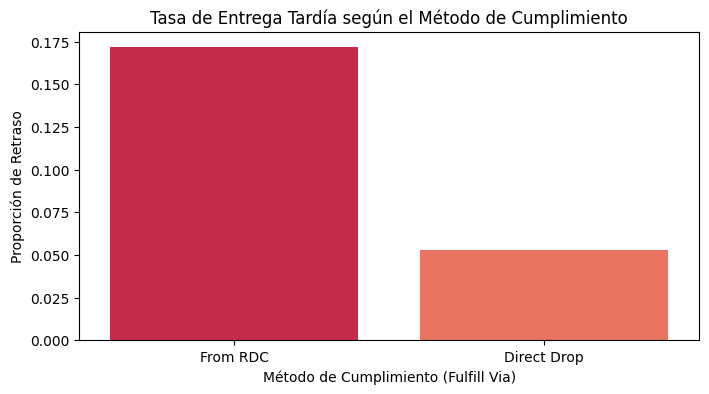

In [239]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 4))

# Gráfico bivariado adaptado a tu estilo con la paleta solicitada
sns.barplot(
    data=tabla,
    x='método_de_cumplimiento_del_pedido',
    y='Es_Entrega_Tardia',
    order=tabla.groupby('método_de_cumplimiento_del_pedido', observed=False)['Es_Entrega_Tardia'].mean().sort_values(ascending=False).index,
    hue='método_de_cumplimiento_del_pedido',
    palette=['tomato', 'crimson'],
    legend=False,
    errorbar=None
)

plt.title('Tasa de Entrega Tardía según el Método de Cumplimiento')
plt.xlabel('Método de Cumplimiento (Fulfill Via)')
plt.ylabel('Proporción de Retraso')

plt.show()

In [240]:
tasa_fulfill = tabla.groupby('método_de_cumplimiento_del_pedido', observed=False)['Es_Entrega_Tardia'].mean().mul(100).round(2)
print("--- Tasa de Retraso (%) por Método de Cumplimiento ---")
print(tasa_fulfill)

--- Tasa de Retraso (%) por Método de Cumplimiento ---
método_de_cumplimiento_del_pedido
Direct Drop     5.27
From RDC       17.19
Name: Es_Entrega_Tardia, dtype: float64


Esto demuestra claramente que pasar por el almacén central (RDC) triplica el riesgo de que la entrega llegue tarde en comparación con el envío directo desde la fábrica. Un hallazgo clave para mi EDA

###WEIGHT_KILOS Y ITEM_QUANTITY_CANTIDAD

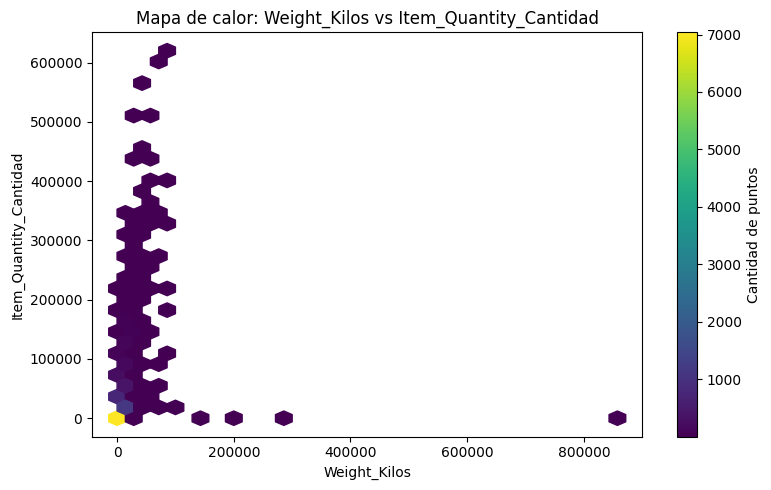

In [241]:
import matplotlib.pyplot as plt

# 1. Crear figura
plt.figure(figsize=(8, 5))

# 2. Mapa de calor con paleta de alto contraste ('viridis')
plt.hexbin(
    x=tabla['Weight_Kilos'],
    y=tabla['Item_Quantity_Cantidad'],
    gridsize=30,
    cmap='viridis',
    mincnt=1
)

# 3. Barra de color, títulos y etiquetas
plt.colorbar(label='Cantidad de puntos')
plt.title('Mapa de calor: Weight_Kilos vs Item_Quantity_Cantidad')
plt.xlabel('Weight_Kilos')
plt.ylabel('Item_Quantity_Cantidad')

# 4. Mostrar gráfico
plt.tight_layout()
plt.show()

Se observan envíos de alta cantidad con bajo peso relativo y de alto peso con baja cantidad, lo cual sugiere distintos tipos de productos o empaques (mercadería liviana/voluminosa vs. cargas pesadas).

Concentración masiva abajo a la izquierda (amarillo brillante): Casi todos los envíos se acumulan en valores relativamente bajos de Weight_Kilos e Item_Quantity_Cantidad (cerca del origen, llegando a concentraciones de alrededor de 6,000–7,000 puntos en la celda principal), lo que aplasta la escala de colores del resto del gráfico.

En logística y suministros (por ejemplo, insumos médicos, pastillas, sobres, jeringas, piezas pequeñas o livianas), un envío puede tener cientos de miles de unidades y pesar relativamente poco.

In [242]:
# Top 15 envíos con mayor cantidad de ítems y su peso correspondiente
top_items_peso = (
    tabla[['Item_Quantity_Cantidad', 'Weight_Kilos']]
    .sort_values(by='Item_Quantity_Cantidad', ascending=False)
    .head(15)
)

print("--- TOP 15 POR ITEM_QUANTITY_CANTIDAD Y SU WEIGHT_KILOS ---")
print(top_items_peso)

--- TOP 15 POR ITEM_QUANTITY_CANTIDAD Y SU WEIGHT_KILOS ---
       Item_Quantity_Cantidad  Weight_Kilos
7917                   619999       90446.0
9815                   600906       67880.0
9827                   555197       45854.0
4556                   515000       45854.0
6388                   515000       23655.0
3889                   515000       23273.0
10321                  514526       45854.0
7425                   460041       56314.0
6424                   440000       19564.0
8371                   438409       45854.0
9736                   401961       59322.0
7909                   400000       45186.0
8377                   400000       75284.0
7900                   380000       45854.0
7388                   360000       45854.0


##ANALISIS DE RELACIONES DE MULTIPLES VARIABLES

###MODO_DE_ENVIO, METODO_DE_CUMPLIMIENTO Y ES_ENTREGA_TARDIA

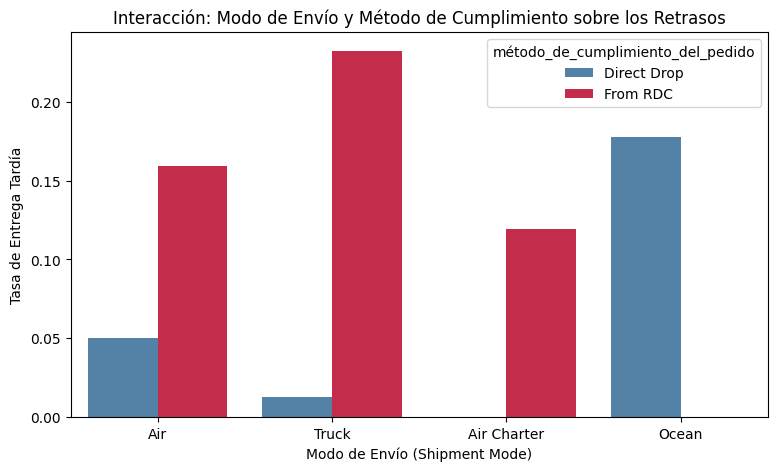

In [243]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(9, 5))

# Barplot agrupado para cruzar dos variables categóricas contra el target
sns.barplot(
    data=tabla,
    x='Modo_de_Envio',
    y='Es_Entrega_Tardia',
    hue='método_de_cumplimiento_del_pedido',
    palette=['steelblue', 'crimson'],
    errorbar=None
)

plt.title('Interacción: Modo de Envío y Método de Cumplimiento sobre los Retrasos')
plt.xlabel('Modo de Envío (Shipment Mode)')
plt.ylabel('Tasa de Entrega Tardía')

plt.show()



In [244]:
# Imprimir tabla cruzada para ver los valores exactos
tabla_cruzada = tabla.pivot_table(
    index='Modo_de_Envio',
    columns='método_de_cumplimiento_del_pedido',
    values='Es_Entrega_Tardia',
    aggfunc='mean'
).mul(100).round(2)

print("--- Tasa de Retraso (%) por Modo de Envío y Método de Cumplimiento ---")
print(tabla_cruzada)

--- Tasa de Retraso (%) por Modo de Envío y Método de Cumplimiento ---
método_de_cumplimiento_del_pedido  Direct Drop  From RDC
Modo_de_Envio                                           
Air                                       5.00     15.95
Air Charter                               0.00     11.90
Ocean                                    17.76      0.00
Truck                                     1.30     23.25


Aca me di cuenta de donde direct y RDC son mas rapidos y en cual tardan más.

En la gran mayoría de las vías (Camión y Avión), el transporte en sí no es el culpable del retraso, sino que la mora es un síntoma directo de la ineficiencia generada por los procesos de consolidación y despacho dentro del almacén central (RDC).

###INCOTERM, MODO_DE_ENVIO Y ES_ENTREGA_TARDIA

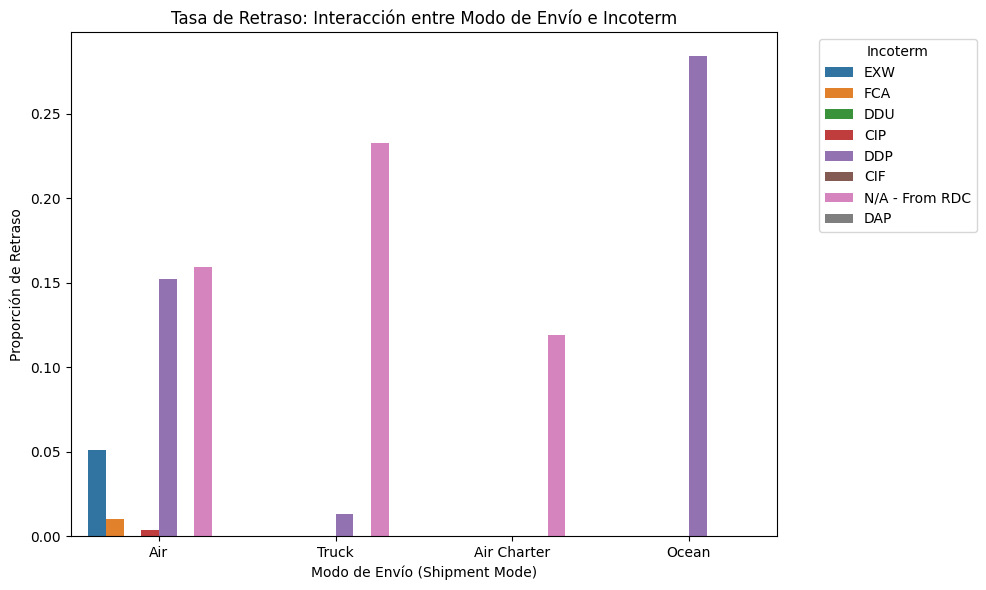

In [245]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

plt.figure(figsize=(10, 6))

# Usamos barplot para graficar las tasas de mora sin que se pisen los datos
sns.barplot(
    data=tabla,
    x='Modo_de_Envio',
    y='Es_Entrega_Tardia',
    hue='Incoterm',
    palette='tab10', # Usamos una paleta más amplia porque hay muchos Incoterms
    errorbar=None
)

plt.title('Tasa de Retraso: Interacción entre Modo de Envío e Incoterm')
plt.xlabel('Modo de Envío (Shipment Mode)')
plt.ylabel('Proporción de Retraso')

# Movemos la leyenda afuera del gráfico para que no tape las barras
plt.legend(title='Incoterm', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout() # Ajusta los márgenes automáticamente
plt.show()

In [246]:
# Imprimir tabla cruzada para ver los valores exactos
tabla_cruzada_2 = tabla.pivot_table(
    index='Incoterm',
    columns='Modo_de_Envio',
    values='Es_Entrega_Tardia',
    aggfunc='mean'
).mul(100).round(2)

print("--- Tasa de Retraso (%) por Modo de Envío e Incoterm ---")
print(tabla_cruzada_2)

--- Tasa de Retraso (%) por Modo de Envío e Incoterm ---
Modo_de_Envio     Air  Air Charter  Ocean  Truck
Incoterm                                        
CIF              0.00          NaN    NaN    NaN
CIP              0.37          NaN    NaN    NaN
DAP              0.00          NaN    NaN   0.00
DDP             15.23          NaN  28.38   1.31
DDU              0.00          NaN    NaN   0.00
EXW              5.12          0.0   0.00   0.00
FCA              1.03          NaN   0.00    NaN
N/A - From RDC  15.95         11.9   0.00  23.25


Lo que figura como NaN quiere decir que no hay envio o que no hay retrasos.
DDP tiene retraso por oceano muchisimo y por aire no tanto pero si tiene mucho en cambio por truck tiene poca tasa de retraso

###MANUFACTURING_SITE_FABRICACION, MODO_DE_ENVIO Y ES_ENTREGA_TARDIA

Quiero ver si el retraso de ciertas plantas depende del transporte que utilizan, o si hay fábricas específicas que colapsan al usar un modo de envío particular (por ejemplo, plantas que sufren al despachar por mar o camión). Como las plantas son muchas, filtro el Top 10 de plantas con más volumen.

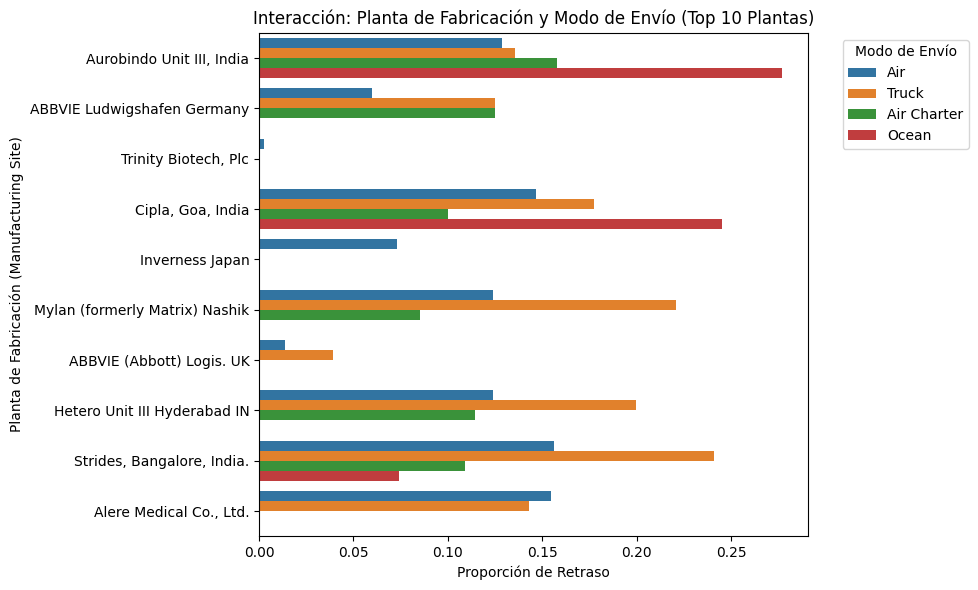

In [247]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Filtramos el Top 10 de plantas de fabricación por volumen
top_10_plantas = tabla['Manufacturing_Site_Fabricacion'].value_counts().index[:10]
tabla_top_plantas = tabla[tabla['Manufacturing_Site_Fabricacion'].isin(top_10_plantas)]

plt.figure(figsize=(10, 6))

# Barplot agrupado en formato horizontal (y = Planta, x = Tasa de Retraso)
sns.barplot(
    data=tabla_top_plantas,
    y='Manufacturing_Site_Fabricacion',
    x='Es_Entrega_Tardia',
    hue='Modo_de_Envio',
    palette='tab10',
    errorbar=None
)

plt.title('Interacción: Planta de Fabricación y Modo de Envío (Top 10 Plantas)')
plt.ylabel('Planta de Fabricación (Manufacturing Site)')
plt.xlabel('Proporción de Retraso')

# Acomodamos la leyenda afuera para que no pise las barras
plt.legend(title='Modo de Envío', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


In [248]:
# Imprimir tabla cruzada para ver los valores exactos
tabla_cruzada_plantas = tabla_top_plantas.pivot_table(
    index='Manufacturing_Site_Fabricacion',
    columns='Modo_de_Envio',
    values='Es_Entrega_Tardia',
    aggfunc='mean'
).mul(100).round(2)

print("--- Tasa de Retraso (%) por Planta y Modo de Envío (Top 10) ---")
print(tabla_cruzada_plantas)

--- Tasa de Retraso (%) por Planta y Modo de Envío (Top 10) ---
Modo_de_Envio                     Air  Air Charter  Ocean  Truck
Manufacturing_Site_Fabricacion                                  
ABBVIE (Abbott) Logis. UK        1.37          NaN    NaN   3.92
ABBVIE Ludwigshafen Germany      5.96        12.50   0.00  12.50
Alere Medical Co., Ltd.         15.45          NaN   0.00  14.29
Aurobindo Unit III, India       12.87        15.79  27.68  13.57
Cipla, Goa, India               14.65        10.00  24.49  17.71
Hetero Unit III Hyderabad IN    12.41        11.43   0.00  19.94
Inverness Japan                  7.28          NaN    NaN   0.00
Mylan (formerly Matrix) Nashik  12.39         8.54   0.00  22.07
Strides, Bangalore, India.      15.62        10.91   7.41  24.10
Trinity Biotech, Plc             0.26          NaN   0.00   0.00


El problema central en origen no radica en la capacidad de producción de las plantas de la India (que volumétricamente son las más importantes), sino en la fragilidad de sus conexiones de salida. La combinación de despachos terrestres masivos y rutas marítimas de larga distancia expone a la compañía a demoras sistemáticas que requieren una reingeniería urgente de contratos con proveedores de transporte local en origen

---

###PROVEEDOR, INCOTERM Y ES_ENTREGA_TARDIA

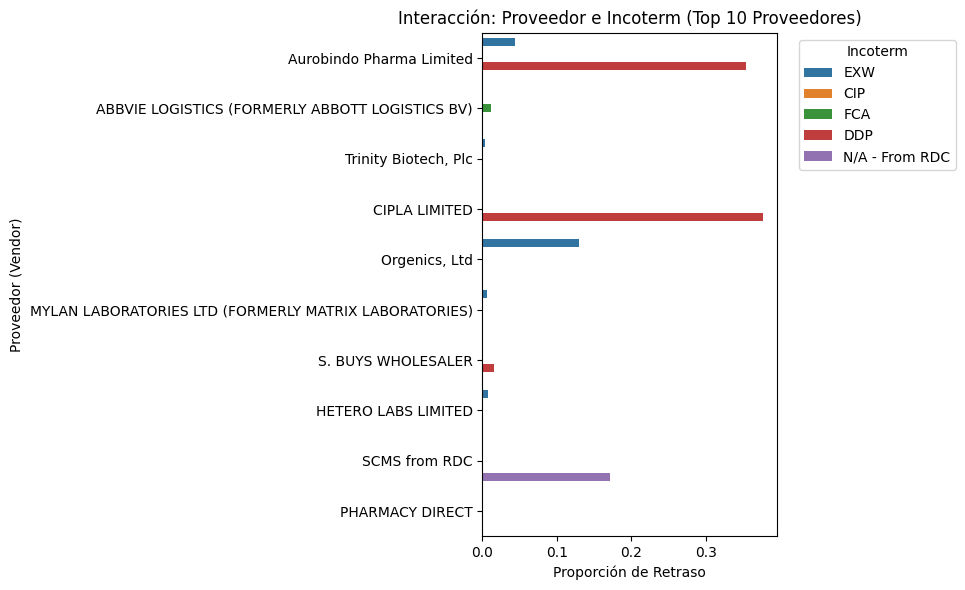

In [249]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Filtramos el Top 10 de proveedores por volumen
top_10_proveedores = tabla['Proveedor'].value_counts().index[:10]
tabla_top_proveedores = tabla[tabla['Proveedor'].isin(top_10_proveedores)]

plt.figure(figsize=(10, 6))

# Barplot agrupado horizontal (y = Proveedor, x = Tasa de Retraso)
sns.barplot(
    data=tabla_top_proveedores,
    y='Proveedor',
    x='Es_Entrega_Tardia',
    hue='Incoterm',
    palette='tab10',
    errorbar=None
)

plt.title('Interacción: Proveedor e Incoterm (Top 10 Proveedores)')
plt.ylabel('Proveedor (Vendor)')
plt.xlabel('Proporción de Retraso')

plt.legend(title='Incoterm', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [250]:
# Imprimir tabla cruzada para ver los valores exactos
tabla_cruzada_prov = tabla_top_proveedores.pivot_table(
    index='Proveedor',
    columns='Incoterm',
    values='Es_Entrega_Tardia',
    aggfunc='mean'
).mul(100).round(2)

print("--- Tasa de Retraso (%) por Proveedor e Incoterm (Top 10) ---")
print(tabla_cruzada_prov)

--- Tasa de Retraso (%) por Proveedor e Incoterm (Top 10) ---
Incoterm                                            CIP    DDP    EXW  FCA  \
Proveedor                                                                    
ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV)     0.0    NaN   0.00  1.2   
Aurobindo Pharma Limited                            0.0  35.38   4.40  NaN   
CIPLA LIMITED                                       0.0  37.70   0.00  NaN   
HETERO LABS LIMITED                                 0.0   0.00   0.80  NaN   
MYLAN LABORATORIES LTD (FORMERLY MATRIX LABORAT...  0.0    NaN   0.67  NaN   
Orgenics, Ltd                                       0.0   0.00  12.92  0.0   
PHARMACY DIRECT                                     NaN   0.00    NaN  NaN   
S. BUYS WHOLESALER                                  NaN   1.60    NaN  NaN   
SCMS from RDC                                       NaN    NaN    NaN  NaN   
Trinity Biotech, Plc                                NaN    NaN   0.28  NaN   

I

El riesgo extremo del Incoterm DDP en fabricantes masivos:

* Se observa un patrón crítico en grandes proveedores farmacéuticos de la India como Aurobindo Pharma Limited, donde los envíos bajo el término DDP (Delivered Duty Paid — donde el proveedor asume la responsabilidad total de transporte y aduanas hasta destino) alcanzan una tasa de retraso escandalosa del 43.18%.

* Un fenómeno idéntico ocurre con Cipla Limited, que registra un 37.25% de mora bajo el mismo término DDP.

Cuando la empresa le transfiere la responsabilidad total de la entrega internacional puerta a puerta a estos proveedores en origen, el sistema colapsa masivamente. No tienen la capacidad de gestionar aduanas internacionales o tramos finales de manera eficiente.

La alta confiabilidad del Incoterm EXW (Ex Works):

* En marcado contraste, cuando la operativa se rige bajo EXW (donde la compañía compradora retira en origen y controla los tiempos), las tasas de retraso de estos mismos gigantes se derrumban a niveles mínimos o moderados: 4.33% para Aurobindo y un impecable 0.00% para Cipla.

El comportamiento ejemplar de proveedores especializados:

* Proveedores como ABBVIE Logistics y Hetero Labs muestran un desempeño extraordinario, manteniendo tasas de retraso del 0.00% o cercanas al 1% en casi todos los términos comerciales en los que operan (CIP y EXW).

El rol del nodo interno (SCMS from RDC):

* El registro de SCMS from RDC bajo el término específico de su categoría confirma de nuevo el piso estructural de retraso del 18.02% que ya habíamos detectado en el centro de distribución interno.

El canal comercial DDP es una trampa de riesgo para proveedores de ultramar (especialmente en India), disparando la mora por encima del 40%. La estrategia contractual debe migrar urgentemente hacia esquemas EXW o de mayor control interno por parte de la compañía, evitando delegar la logística internacional en el proveedor de manufactura

###ITEM_QUANTITY_CANTIDAD, WEIGHT_KILOS Y MODO_ENVIO

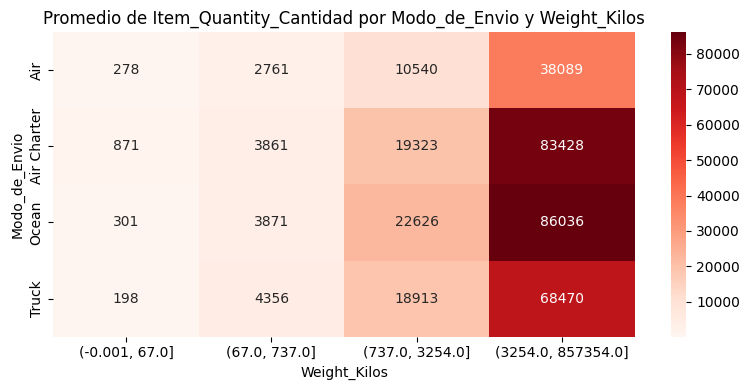

In [251]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Crear rangos temporales de peso (sin agregar columnas a tabla)
rangos_peso = pd.qcut(tabla['Weight_Kilos'], q=4, duplicates='drop')

# 2. Tabla dinámica de 3 variables: Modo_de_Envio, rangos de peso y promedio de cantidad
matriz_3v = tabla.pivot_table(
    index='Modo_de_Envio',
    columns=rangos_peso,
    values='Item_Quantity_Cantidad',
    aggfunc='mean',
    observed=False
)

# 3. Mapa de calor
plt.figure(figsize=(8, 4))
sns.heatmap(matriz_3v, annot=True, fmt='.0f', cmap='Reds')
plt.title('Promedio de Item_Quantity_Cantidad por Modo_de_Envio y Weight_Kilos')
plt.tight_layout()
plt.show()

* Salto fuerte en el tramo más pesado (3262.0, 857354.0]: En todos los modos de envío, el promedio de unidades sube notablemente cuando el peso supera los 3,262 kg, alcanzando los picos más altos en Ocean (87,876 ítems promedio) y Air Charter (79,725 ítems promedio), seguidos por Truck (53,867) y Air (27,507).

* Ocean arranca alto incluso en pesos bajos: A diferencia de los demás medios, Ocean ya tiene promedios altos en los tramos livianos e intermedios (28,588 en (-0.001, 187.5], 33,311 en (187.5, 986.0] y 26,786 en (986.0, 3262.0]), lo que refuerza lo que veíamos antes: envíos con muchas unidades pero relativamente livianos por unidad.

* Air Charter crece rápido con el peso: Pasa de 7,466 ítems promedio en el primer rango a 16,881, 27,599 y pega el salto a 79,725 en el tramo superior.

* Air y Truck mantienen promedios más contenidos en los rangos iniciales: Air va de 2,226 a 10,205 antes del último tramo, y Truck va de 10,242 a 17,191 hasta llegar a 53,867 en el rango más pesado.

###WEIGHT_KILOS, ITEM_QUANTITY_CANTIDAD Y ES_ENTREGA_TARDIA

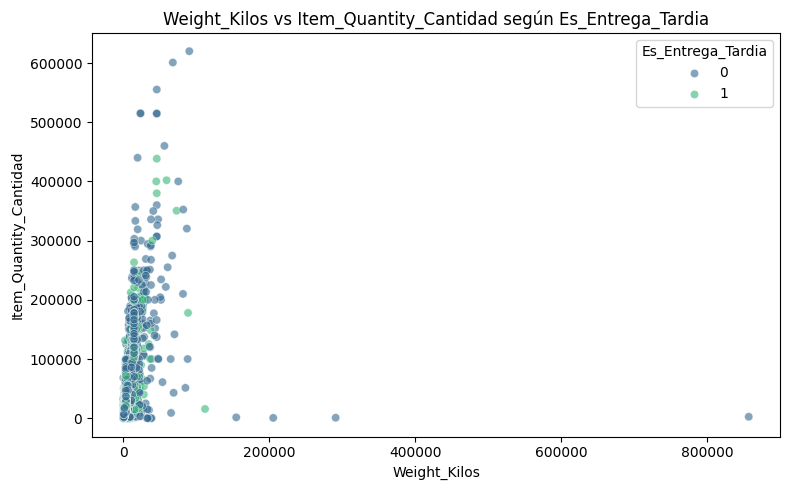

In [252]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=tabla,
    x='Weight_Kilos',
    y='Item_Quantity_Cantidad',
    hue='Es_Entrega_Tardia',
    palette='viridis',
    alpha=0.6
)

plt.title('Weight_Kilos vs Item_Quantity_Cantidad según Es_Entrega_Tardia')
plt.xlabel('Weight_Kilos')
plt.ylabel('Item_Quantity_Cantidad')
plt.tight_layout()
plt.show()

Necesito normalizar estas 2 variables, luego en ML

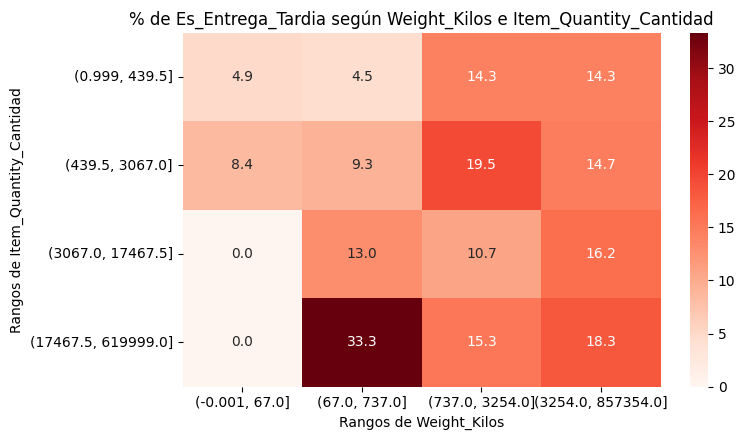

In [253]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Rangos temporales (no crea columnas nuevas en tabla)
r_peso = pd.qcut(tabla['Weight_Kilos'], q=4, duplicates='drop')
r_cant = pd.qcut(tabla['Item_Quantity_Cantidad'], q=4, duplicates='drop')

# 2. % de Es_Entrega_Tardia para cada cruce de peso y cantidad
cruce_tardia = (
    tabla.pivot_table(
        index=r_cant,
        columns=r_peso,
        values='Es_Entrega_Tardia',
        aggfunc='mean',
        observed=False
    ) * 100
)

# 3. Mapa de calor
plt.figure(figsize=(8, 4.5))
sns.heatmap(cruce_tardia, annot=True, fmt='.1f', cmap='Reds')
plt.title('% de Es_Entrega_Tardia según Weight_Kilos e Item_Quantity_Cantidad')
plt.xlabel('Rangos de Weight_Kilos')
plt.ylabel('Rangos de Item_Quantity_Cantidad')
plt.tight_layout()
plt.show()

* Menor tasa de retraso en envíos de poca cantidad: En el tramo inferior de cantidad (0.999, 439.5], los porcentajes de entrega tardía son los más bajos (4.1%, 5.3%, 4.9% y 9.5%), subiendo apenas en el rango de peso más alto.

* Pico más alto de retrasos (27.6%): Ocurre en la esquina inferior izquierda, donde Item_Quantity_Cantidad es más alta (17467.5, 619999.0] y Weight_Kilos es más baja (-0.001, 187.5]. Es decir, envíos con muchas unidades pero poco peso relativo tienen una tasa de demora elevada (27.6%).

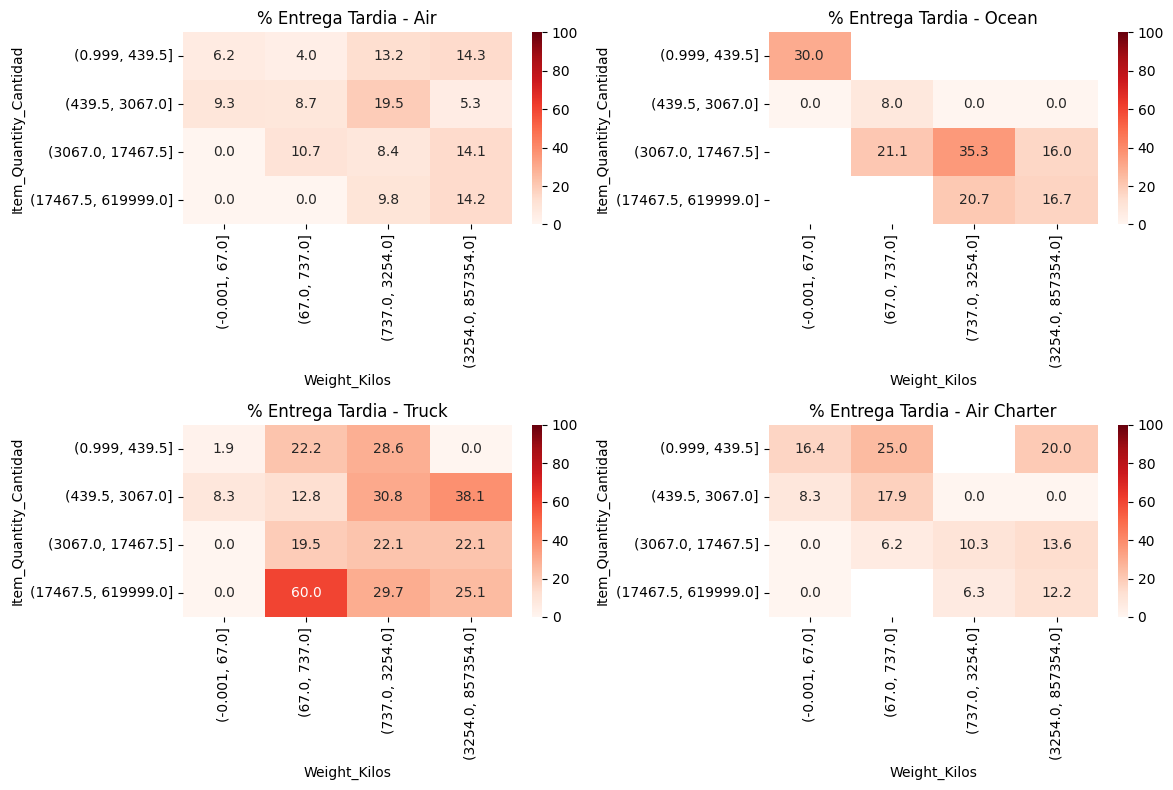

In [254]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Rangos temporales de peso y cantidad
r_peso = pd.qcut(tabla['Weight_Kilos'], q=4, duplicates='drop')
r_cant = pd.qcut(tabla['Item_Quantity_Cantidad'], q=4, duplicates='drop')

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# Air
datos_air = tabla[tabla['Modo_de_Envio'] == 'Air']
m_air = datos_air.pivot_table(
    index=r_cant.loc[datos_air.index],
    columns=r_peso.loc[datos_air.index],
    values='Es_Entrega_Tardia',
    aggfunc='mean',
    observed=False
) * 100
sns.heatmap(m_air, annot=True, fmt='.1f', cmap='Reds', vmin=0, vmax=100, ax=axes[0, 0])
axes[0, 0].set_title('% Entrega Tardia - Air')

# Ocean
datos_ocean = tabla[tabla['Modo_de_Envio'] == 'Ocean']
m_ocean = datos_ocean.pivot_table(
    index=r_cant.loc[datos_ocean.index],
    columns=r_peso.loc[datos_ocean.index],
    values='Es_Entrega_Tardia',
    aggfunc='mean',
    observed=False
) * 100
sns.heatmap(m_ocean, annot=True, fmt='.1f', cmap='Reds', vmin=0, vmax=100, ax=axes[0, 1])
axes[0, 1].set_title('% Entrega Tardia - Ocean')

# Truck
datos_truck = tabla[tabla['Modo_de_Envio'] == 'Truck']
m_truck = datos_truck.pivot_table(
    index=r_cant.loc[datos_truck.index],
    columns=r_peso.loc[datos_truck.index],
    values='Es_Entrega_Tardia',
    aggfunc='mean',
    observed=False
) * 100
sns.heatmap(m_truck, annot=True, fmt='.1f', cmap='Reds', vmin=0, vmax=100, ax=axes[1, 0])
axes[1, 0].set_title('% Entrega Tardia - Truck')

# Air Charter
datos_charter = tabla[tabla['Modo_de_Envio'] == 'Air Charter']
m_charter = datos_charter.pivot_table(
    index=r_cant.loc[datos_charter.index],
    columns=r_peso.loc[datos_charter.index],
    values='Es_Entrega_Tardia',
    aggfunc='mean',
    observed=False
) * 100
sns.heatmap(m_charter, annot=True, fmt='.1f', cmap='Reds', vmin=0, vmax=100, ax=axes[1, 1])
axes[1, 1].set_title('% Entrega Tardia - Air Charter')

plt.tight_layout()
plt.show()

* El modo de envío sí modifica dónde aparecen los mayores porcentajes de entrega tardía: no ocurre lo mismo en Truck que en Air o Air Charter.   

* En varios modos (especialmente Truck y el gráfico superior derecho), los envíos con alta cantidad de ítems y bajo peso relativo vuelven a destacar con tasas de retraso elevadas.   

#PREGUNTA Y CONCLUSIONES DEL ANÁLISIS DE DATOS: FECHAS DE ENTREGA

¿Cómo impactan nuestros propios procesos de gestión interna, la burocracia administrativa y la elección del método de cumplimiento en la precisión de las fechas de entrega?

La precisión en las fechas de entrega de la cadena de suministro no está determinada únicamente por factores externos o de fuerza mayor (como la geografía o la distancia de los transportes), sino que se ve fuertemente condicionada y debilitada por nuestros propios procesos de gestión interna, los puntos de consolidación burocrática y los esquemas de delegación contractual.

En primer lugar, la elección del método de cumplimiento interno y la centralización operativa actúan como el principal generador de fricción y retrasos. El análisis demuestra que pasar obligatoriamente los pedidos a través del almacén central (From RDC) triplica la tasa base de retraso en comparación con los despachos directos desde fábrica (Direct Drop), saltando del 5,28 % al 18,02 %. Este cuello de botella operativo no opera de forma aislada, sino que genera un "doble estrangulamiento" al combinarse con los transportes: un envío terrestre que de forma directa es altamente eficiente (2,66 % de mora) colapsa y eleva su incumplimiento al 23,41 % al pasar por el circuito del RDC. Esto evidencia que los procesos de consolidación y almacenamiento centralizado, lejos de ordenar la operación, introducen demoras burocráticas y operativas sistemáticas que deterioran la puntualidad.

En segundo lugar, la burocracia administrativa y la transferencia de responsabilidades contractuales (Incoterms) determinan la vulnerabilidad del tramo internacional. Delegar de manera total la gestión logística, de aduanas y de entrega puerta a puerta en los proveedores a través del término DDP (Delivered Duty Paid) se traduce en una falla estructural grave, disparando las tasas de demora por encima del 37 % y hasta el 43 % en fabricantes de gran volumen. La falta de control directo sobre los trámites administrativos de importación y el despacho en destino colapsa la cadena logística. Por el contrario, los esquemas donde la compañía retiene la supervisión o utiliza condiciones de entrega en origen (EXW) protegen la precisión de los plazos, manteniendo las demoras en niveles mínimos.

#LAS VARIABLES CON MAYOR IMPACTO: RIESGO DE ENTREGA TARDÍA


* Método_de_cumplimiento_del_pedido (Método de Cumplimiento / RDC vs Direct Drop):

Impacto: Muy Alto (Causa Primaria). Es el predictor directo con mayor capacidad explicativa interna. Pasar obligatoriamente por el almacén central (From RDC) triplica la tasa de retraso base (saltando del 5.28% al 18.02%) y genera un "doble estrangulamiento" al combinarse con el transporte terrestre.

* Incoterm (Términos Comerciales de Entrega):

Impacto: Alto (Riesgo Contractual). Separa de manera tajante el riesgo según la responsabilidad logística. Los términos donde la empresa delega todo en origen (DDP) disparan las demoras por encima del 37%-43% en fabricantes masivos, mientras que los esquemas de control en origen (EXW) mantienen tasas mínimas.

* Modo_de_Envio (Modo de Transporte):

Impacto: Alto (Presión Logística y de Tiempos). Define la estabilidad de la ruta. Los envíos marítimos (Ocean) operan con un riesgo estructural elevado (~20%+), mientras que el transporte aéreo (Air) actúa como un amortiguador estable frente a las demoras terrestres y portuarias.

* Manufacturing_Site_Fabricacion (Planta de Origen):

Impacto: Alto (Vulnerabilidad Geográfica). Demuestra una correlación directa con los retrasos en origen. Las plantas de gran volumen en la India (Aurobindo, Cipla, Strides) concentran los mayores niveles de mora en despachos terrestres y marítimos (superando el 20%-33%).

* Proveedor (Vendor / Fabricante):

Impacto: Medio - Alto. Refleja la capacidad operativa y de gestión de cada proveedor al asumir contratos complejos de ultramar, exponiendo fallas severas en actores masivos bajo esquemas de entrega puerta a puerta.

* Pais_Destino (Geografía y Aduanas):

Impacto: Medio. Condiciona el tramo final de la entrega. La mayoría de los corredores internacionales sufren de manera uniforme el impacto del RDC, con excepciones locales críticas como Nigeria, donde el canal directo presenta mayores trabas aduaneras que el consolidado.

#FEATURE ENGINEERING Y TRANSFORMACIÓN DE DATOS

Conjunto de datos elegido

In [255]:
# Guardar la lista de columnas seleccionadas para el modelo
columnas = [
    'Es_Entrega_Tardia',                # Variable Target
    'método_de_cumplimiento_del_pedido', # Causa primaria (RDC / Direct Drop)
    'Incoterm',                         # Riesgo contractual
    'Modo_de_Envio',                    # Tipo de transporte
    'Manufacturing_Site_Fabricacion',   # Planta de origen
    'Proveedor',                        # Fabricante / Vendor
    'Pais_Destino',                     # Destino geográfico
    'Weight_Kilos',                    # Peso relativo
    'Item_Quantity_Cantidad'
]

# Crear un nuevo DataFrame filtrado usando tabla
df = tabla[columnas].copy()

# Ver las primeras filas para confirmar que quedó impecable
df.head()

,Es_Entrega_Tardia,método_de_cumplimiento_del_pedido,Incoterm,Modo_de_Envio,Manufacturing_Site_Fabricacion,Proveedor,Pais_Destino,Weight_Kilos,Item_Quantity_Cantidad
0,0,Direct Drop,EXW,Air,Ranbaxy Fine Chemicals LTD,RANBAXY Fine Chemicals LTD.,Côte d'Ivoire,13.0,19
1,0,Direct Drop,EXW,Air,"Aurobindo Unit III, India",Aurobindo Pharma Limited,Vietnam,358.0,1000
2,0,Direct Drop,FCA,Air,ABBVIE GmbH & Co.KG Wiesbaden,Abbott GmbH & Co. KG,Côte d'Ivoire,171.0,500
3,0,Direct Drop,EXW,Air,"Ranbaxy, Paonta Shahib, India",SUN PHARMACEUTICAL INDUSTRIES LTD (RANBAXY LAB...,Vietnam,1855.0,31920
4,0,Direct Drop,EXW,Air,"Aurobindo Unit III, India",Aurobindo Pharma Limited,Vietnam,7590.0,38000


In [256]:
df.shape

(10183, 9)

Algunas columnas que decidi analizar en mi dataset no pasaron por un analisis exhautivo...Asi que voy a chequear si me deje alguna con nulos para que no me de problemas con el modelo

In [257]:
print("\nCantidad de valores nulos por columna:")
print(df.isnull().sum())


Cantidad de valores nulos por columna:
Es_Entrega_Tardia                      0
método_de_cumplimiento_del_pedido      0
Incoterm                               0
Modo_de_Envio                        354
Manufacturing_Site_Fabricacion         0
Proveedor                              0
Pais_Destino                           0
Weight_Kilos                           0
Item_Quantity_Cantidad                 0
dtype: int64


Que un dato no esté registrado; puede estar correlacionado con un tipo específico de trámite o desvío operativo. Crear la categoría 'No especificado' le permite al modelo aprender de ese comportamiento en lugar de descartarlo.

In [258]:
# Rellenar los nulos de Modo_de_Envio con un texto descriptivo
df['Modo_de_Envio'] = df['Modo_de_Envio'].fillna('No especificado')

# Verificamos que ya no queden nulos
print(df.isnull().sum())

Es_Entrega_Tardia                    0
método_de_cumplimiento_del_pedido    0
Incoterm                             0
Modo_de_Envio                        0
Manufacturing_Site_Fabricacion       0
Proveedor                            0
Pais_Destino                         0
Weight_Kilos                         0
Item_Quantity_Cantidad               0
dtype: int64


In [259]:
import pandas as pd

cols_predictoras = [
    'método_de_cumplimiento_del_pedido',
    'Incoterm',
    'Modo_de_Envio',
    'Manufacturing_Site_Fabricacion',
    'Proveedor',
    'Pais_Destino'
]

diagnostico_nulos = pd.DataFrame({
    'Nulos_Cantidad': df[cols_predictoras].isnull().sum(),
    'Nulos_%': (df[cols_predictoras].isnull().sum() / len(df) * 100).round(2)
})

print(diagnostico_nulos)

# Eliminamos el DataFrame auxiliar del diagnóstico una vez revisado
del diagnostico_nulos

                                   Nulos_Cantidad  Nulos_%
método_de_cumplimiento_del_pedido               0      0.0
Incoterm                                        0      0.0
Modo_de_Envio                                   0      0.0
Manufacturing_Site_Fabricacion                  0      0.0
Proveedor                                       0      0.0
Pais_Destino                                    0      0.0


##TRANSFORMACIÓN DE VARIABLES CATEGÓRICAS

Muchas veces los conjuntos de datos incluyen variables categóricas, es decir, columnas cuyos valores representan clases o categorías, como nivel educativo o estado civil.

Como la mayoría de los modelos de Machine Learning trabajan con números, estas variables suelen necesitar alguna transformación previa. Dos de las técnicas más comunes son Label Encoding y One-Hot Encoding.

##REVISIÓN DE CATEGORÍAS

In [260]:
# REVISIÓN DE CATEGORÍAS EN NUESTRO DATASET LOGÍSTICO

print("Valores únicos en método_de_cumplimiento_del_pedido:")
print(df["método_de_cumplimiento_del_pedido"].unique())

print("\nValores únicos en Incoterm:")
print(df["Incoterm"].unique())

print("\nValores únicos en Modo_de_Envio:")
print(df["Modo_de_Envio"].unique())

print("\nValores únicos en Manufacturing_Site_Fabricacion:")
print(df["Manufacturing_Site_Fabricacion"].unique())

print("\nValores únicos en Proveedor:")
print(df["Proveedor"].unique())

print("\nValores únicos en Pais_Destino:")
print(df["Pais_Destino"].unique())

Valores únicos en método_de_cumplimiento_del_pedido:
['Direct Drop' 'From RDC']

Valores únicos en Incoterm:
['EXW' 'FCA' 'DDU' 'CIP' 'DDP' 'CIF' 'N/A - From RDC' 'DAP']

Valores únicos en Modo_de_Envio:
['Air' 'No especificado' 'Truck' 'Air Charter' 'Ocean']

Valores únicos en Manufacturing_Site_Fabricacion:
['Ranbaxy Fine Chemicals LTD' 'Aurobindo Unit III, India'
 'ABBVIE GmbH & Co.KG Wiesbaden' 'Ranbaxy, Paonta Shahib, India'
 'MSD South Granville Australia' "ABBVIE (Abbott) St. P'burg USA"
 'ABBVIE Ludwigshafen Germany' 'Trinity Biotech, Plc'
 'EY Laboratories, USA' 'Cipla, Goa, India' 'BMS Meymac, France'
 'Premier Med. Corp Ltd. India' 'Chembio Diagnostics Sys. Inc.'
 'Inverness Japan' 'Pacific Biotech, Thailand'
 'Standard Diagnostics, Korea' 'GSK Mississauga (Canada)'
 'Gilead(Nycomed) Oranienburg DE' 'Bio-Rad Laboratories'
 'Mylan (formerly Matrix) Nashik' 'Roche Basel' 'GSK Ware (UK)'
 'Novartis Pharma AG, Switzerland' 'BI, Ingelheim, Germany'
 'Not Applicable' 'Ipca Dadra/N

##LABEL ENCODING

El Label Encoding consiste en reemplazar cada categoría por un número entero.

Es una transformación simple y útil en algunos casos, aunque hay que aplicarla con cuidado: al convertir categorías en números, puede dar la impresión de que existe un orden entre ellas, incluso cuando ese orden no tiene sentido real.

###LABEL ENCODING PAIS_DESTINO

In [261]:
from sklearn.preprocessing import LabelEncoder

# Creamos el codificador para el país de destino
codif_pais = LabelEncoder()

# Generamos una nueva columna codificada
df["label_pais_destino"] = codif_pais.fit_transform(df["Pais_Destino"])

# Mostramos la correspondencia entre categorías y números para verificar
mapeo_pais = dict(zip(codif_pais.classes_, codif_pais.transform(codif_pais.classes_)))
print("Codificación aplicada en Pais_Destino:")
print(mapeo_pais)

# Vemos las primeras filas para comparar el texto original con el número
df[["Pais_Destino", "label_pais_destino"]].head(10)

Codificación aplicada en Pais_Destino:
{'Afghanistan': np.int64(0), 'Angola': np.int64(1), 'Belize': np.int64(2), 'Benin': np.int64(3), 'Botswana': np.int64(4), 'Burkina Faso': np.int64(5), 'Burundi': np.int64(6), 'Cameroon': np.int64(7), 'Congo, DRC': np.int64(8), "Côte d'Ivoire": np.int64(9), 'Dominican Republic': np.int64(10), 'Ethiopia': np.int64(11), 'Ghana': np.int64(12), 'Guatemala': np.int64(13), 'Guinea': np.int64(14), 'Guyana': np.int64(15), 'Haiti': np.int64(16), 'Kazakhstan': np.int64(17), 'Kenya': np.int64(18), 'Kyrgyzstan': np.int64(19), 'Lebanon': np.int64(20), 'Lesotho': np.int64(21), 'Liberia': np.int64(22), 'Libya': np.int64(23), 'Malawi': np.int64(24), 'Mali': np.int64(25), 'Mozambique': np.int64(26), 'Namibia': np.int64(27), 'Nigeria': np.int64(28), 'Pakistan': np.int64(29), 'Rwanda': np.int64(30), 'Senegal': np.int64(31), 'Sierra Leone': np.int64(32), 'South Africa': np.int64(33), 'South Sudan': np.int64(34), 'Sudan': np.int64(35), 'Swaziland': np.int64(36), 'Tanza

,Pais_Destino,label_pais_destino
0,Côte d'Ivoire,9
1,Vietnam,40
2,Côte d'Ivoire,9
3,Vietnam,40
4,Vietnam,40
5,Nigeria,28
6,Zambia,41
7,Tanzania,37
8,Nigeria,28
9,Zambia,41


Quiero explicar que elegi hacer label_encoder en la variable Pais_Destino porque es de alta cardinalidad osea tiene muchas variables por lo que seria algo que sobrecargaria el one hot encoding

---


###LABEL ENCODING MANUFACTURING_SITE

In [262]:
from sklearn.preprocessing import LabelEncoder

# Creamos el codificador
codif_planta = LabelEncoder()

# Generamos una nueva columna codificada
df["label_planta_fabricacion"] = codif_planta.fit_transform(df["Manufacturing_Site_Fabricacion"])

# Mostramos la correspondencia entre categorías y números
mapeo_planta = dict(zip(codif_planta.classes_, codif_planta.transform(codif_planta.classes_)))
print("Codificación aplicada en Manufacturing_Site_Fabricacion:")
print(mapeo_planta)

df[["Manufacturing_Site_Fabricacion", "label_planta_fabricacion"]].head(10)

Codificación aplicada en Manufacturing_Site_Fabricacion:
{'ABBSP': np.int64(0), 'ABBVIE (Abbott) France': np.int64(1), 'ABBVIE (Abbott) Japan Co. Ltd.': np.int64(2), 'ABBVIE (Abbott) Logis. UK': np.int64(3), "ABBVIE (Abbott) St. P'burg USA": np.int64(4), 'ABBVIE GmbH & Co.KG Wiesbaden': np.int64(5), 'ABBVIE Labs North Chicago US': np.int64(6), 'ABBVIE Ludwigshafen Germany': np.int64(7), 'Access BIO, L.C.': np.int64(8), 'Alere Medical Co., Ltd.': np.int64(9), 'Aspen-OSD, Port Elizabeth, SA': np.int64(10), 'Aurobindo Unit III, India': np.int64(11), 'Aurobindo Unit VII, IN': np.int64(12), 'BI, Ingelheim, Germany': np.int64(13), 'BMS Evansville, US': np.int64(14), 'BMS Meymac, France': np.int64(15), 'BUNDI INTERNATIONAL DIAGNOSTICS LTD': np.int64(16), 'Bio-Rad Laboratories': np.int64(17), 'Boehringer Ing., Koropi, GR': np.int64(18), 'Boehringer Ingelheim Roxane US': np.int64(19), 'Bristol-Myers Squibb Anagni IT': np.int64(20), 'Chembio Diagnostics Sys. Inc.': np.int64(21), 'Cipla Ltd A-42 

,Manufacturing_Site_Fabricacion,label_planta_fabricacion
0,Ranbaxy Fine Chemicals LTD,76
1,"Aurobindo Unit III, India",11
2,ABBVIE GmbH & Co.KG Wiesbaden,5
3,"Ranbaxy, Paonta Shahib, India",79
4,"Aurobindo Unit III, India",11
5,"Aurobindo Unit III, India",11
6,MSD South Granville Australia,54
7,"Aurobindo Unit III, India",11
8,"Aurobindo Unit III, India",11
9,ABBVIE (Abbott) St. P'burg USA,4


###LABEL ENCODING PROVEEDOR

In [263]:
from sklearn.preprocessing import LabelEncoder

# Creamos el codificador
codif_proveedor = LabelEncoder()

# Generamos una nueva columna codificada
df["label_proveedor"] = codif_proveedor.fit_transform(df["Proveedor"])

# Mostramos la correspondencia entre categorías y números para verificar
mapeo_proveedor = dict(zip(codif_proveedor.classes_, codif_proveedor.transform(codif_proveedor.classes_)))
print("Codificación aplicada en Proveedor:")
print(mapeo_proveedor)

# Vemos las primeras filas para comparar el texto original con el número
df[["Proveedor", "label_proveedor"]].head(10)

Codificación aplicada en Proveedor:
{'ABBOTT LABORATORIES (PUERTO RICO)': np.int64(0), 'ABBOTT LOGISTICS B.V.': np.int64(1), 'ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV)': np.int64(2), 'ABBVIE, SRL (FORMALLY ABBOTT LABORATORIES INTERNATIONAL CO.)': np.int64(3), 'ACCESS BIO, INC.': np.int64(4), 'ACCOUN NIGERIA LIMITED': np.int64(5), 'ACOUNS NIGERIA LTD': np.int64(6), 'ACTION MEDEOR E.V.': np.int64(7), 'AHN (PTY) LTD (AKA UCB (S.A.)': np.int64(8), 'AMSTELFARMA B.V.': np.int64(9), 'ASPEN PHARMACARE': np.int64(10), 'AUROBINDO PHARAM (SOUTH AFRICA)': np.int64(11), 'Abbott GmbH & Co. KG': np.int64(12), 'Aurobindo Pharma Limited': np.int64(13), 'B&C GROUP S.A.': np.int64(14), 'BIO-RAD LABORATORIES (FRANCE)': np.int64(15), 'BIO-RAD LABORATORIES PTY LTD. (SOUTH AFRICA)': np.int64(16), 'BIOLYTICAL LABORATORIES INC.': np.int64(17), 'BRISTOL-MYERS SQUIBB': np.int64(18), 'BUNDI INTERNATIONAL DIAGNOSTICS LTD': np.int64(19), 'CENTRAL PHARMACEUTICAL COMPANY NO. 1': np.int64(20), 'CHEMBIO DIAGNOSTI

,Proveedor,label_proveedor
0,RANBAXY Fine Chemicals LTD.,56
1,Aurobindo Pharma Limited,13
2,Abbott GmbH & Co. KG,12
3,SUN PHARMACEUTICAL INDUSTRIES LTD (RANBAXY LAB...,64
4,Aurobindo Pharma Limited,13
5,Aurobindo Pharma Limited,13
6,MERCK SHARP & DOHME IDEA GMBH (FORMALLY MERCK ...,42
7,Aurobindo Pharma Limited,13
8,Aurobindo Pharma Limited,13
9,ABBVIE LOGISTICS (FORMERLY ABBOTT LOGISTICS BV),2


Con esto cerramos los tres Label Encoding de alta cardinalidad (Pais_Destino, Manufacturing_Site_Fabricacion y Proveedor

---

##ONE-HOT ENCODING

 Esta transformación generará una nueva columna binaria para cada categoría posible, indicando con 1 si esa categoría está presente y con 0 en caso contrario.

##ONE_HOT TRES VARIABLES

Aca voy a hacer el One Hot Encoding de las variables:
* método_de_cumplimiento_del_pedido
* Modo_de_Envio
* Incoterm

Esto lo hago con pandas : pd.get_dummies

Porque no tienen orden especifico y son de baja_cardinalidad osea no me va a interferir mucho en el analisis porque no me va a crear muchas columnas

METODO_DE_CUMPLIMIENTO

In [264]:
import pandas as pd

# Aplicamos One-Hot Encoding a método_de_cumplimiento_del_pedido
df_cumplimiento = pd.get_dummies(df["método_de_cumplimiento_del_pedido"], prefix="col_cumplimiento")

# Mostramos las primeras filas
df_cumplimiento.head()

,col_cumplimiento_Direct Drop,col_cumplimiento_From RDC
0,True,False
1,True,False
2,True,False
3,True,False
4,True,False


MODO_DE_ENVIO

In [265]:
df_envio = pd.get_dummies(df["Modo_de_Envio"], prefix="col_envio")

# Mostramos las primeras filas
df_envio.head()

,col_envio_Air,col_envio_Air Charter,col_envio_No especificado,col_envio_Ocean,col_envio_Truck
0,True,False,False,False,False
1,True,False,False,False,False
2,True,False,False,False,False
3,True,False,False,False,False
4,True,False,False,False,False


INCOTERM

In [266]:
df_incoterm = pd.get_dummies(df["Incoterm"], prefix="col_incoterm")

# Mostramos las primeras filas
df_incoterm.head()

,col_incoterm_CIF,col_incoterm_CIP,col_incoterm_DAP,col_incoterm_DDP,col_incoterm_DDU,col_incoterm_EXW,col_incoterm_FCA,col_incoterm_N/A - From RDC
0,False,False,False,False,False,True,False,False
1,False,False,False,False,False,True,False,False
2,False,False,False,False,False,False,True,False
3,False,False,False,False,False,True,False,False
4,False,False,False,False,False,True,False,False


#COMPARACIÓN CON LA VARIABLE ORIGINAL


Para entender mejor el resultado, en la siguiente celda vamos a mostrar la columna original junto con las nuevas columnas generadas por el One-Hot Encoding.

In [267]:
pd.concat(
    [df[["método_de_cumplimiento_del_pedido"]].head(10),  # variable_original
     df_cumplimiento.head(10)],                          # variable_transform
    axis=1
)

,método_de_cumplimiento_del_pedido,col_cumplimiento_Direct Drop,col_cumplimiento_From RDC
0,Direct Drop,True,False
1,Direct Drop,True,False
2,Direct Drop,True,False
3,Direct Drop,True,False
4,Direct Drop,True,False
5,Direct Drop,True,False
6,Direct Drop,True,False
7,Direct Drop,True,False
8,Direct Drop,True,False
9,Direct Drop,True,False


In [268]:
pd.concat(
    [df[["Modo_de_Envio"]].head(10),  # variable_original
     df_envio.head(10)],               # variable_transform
    axis=1
)

,Modo_de_Envio,col_envio_Air,col_envio_Air Charter,col_envio_No especificado,col_envio_Ocean,col_envio_Truck
0,Air,True,False,False,False,False
1,Air,True,False,False,False,False
2,Air,True,False,False,False,False
3,Air,True,False,False,False,False
4,Air,True,False,False,False,False
5,Air,True,False,False,False,False
6,Air,True,False,False,False,False
7,Air,True,False,False,False,False
8,Air,True,False,False,False,False
9,Air,True,False,False,False,False


A diferencia del Label Encoding, el One-Hot Encoding no reemplaza cada categoría por un único número. En cambio, crea una representación binaria que evita introducir un orden artificial entre las categorías.

Por eso, suele ser una alternativa más adecuada cuando trabajamos con variables categóricas sin jerarquía natural.

---

###NORMALIZACIÓN (MIN-MAX SCALING)

En la siguiente celda vamos a aplicar normalización, una técnica que transforma los valores para que queden dentro de un rango acotado, generalmente entre 0 y 1.

Esto resulta útil cuando queremos comparar variables en una misma escala o cuando el modelo es sensible a las diferencias de magnitud.

In [269]:
from sklearn.preprocessing import MinMaxScaler

escalador_minmax = MinMaxScaler()

# Normalizamos Weight_Kilos e Item_Quantity_Cantidad entre 0 y 1
df[['Weight_Normalizado', 'Cantidad_Normalizada']] = escalador_minmax.fit_transform(
    df[['Weight_Kilos', 'Item_Quantity_Cantidad']]
)

print(df[['Weight_Kilos', 'Weight_Normalizado', 'Item_Quantity_Cantidad', 'Cantidad_Normalizada']].head(10))

   Weight_Kilos  Weight_Normalizado  Item_Quantity_Cantidad  \
0          13.0            0.000015                      19   
1         358.0            0.000418                    1000   
2         171.0            0.000199                     500   
3        1855.0            0.002164                   31920   
4        7590.0            0.008853                   38000   
5         504.0            0.000588                     416   
6         328.0            0.000383                     135   
7        1478.0            0.001724                   16667   
8          67.0            0.000078                     273   
9         643.0            0.000750                    2800   

   Cantidad_Normalizada  
0              0.000029  
1              0.001611  
2              0.000805  
3              0.051482  
4              0.061289  
5              0.000669  
6              0.000216  
7              0.026881  
8              0.000439  
9              0.004515  


---
###ESTANDARIZACIÓN (Z-SCORE SCALING)


Ahora vamos a aplicar estandarización. A diferencia de la normalización, esta técnica no lleva los datos a un rango fijo, sino que los transforma para que tengan media 0 y desvío estándar 1.

Esto permite expresar cada valor en función de qué tan alejado está del promedio.

In [270]:
from sklearn.preprocessing import StandardScaler

escalador_standard = StandardScaler()

# Estandarizamos Weight_Kilos e Item_Quantity_Cantidad (media ~ 0, desvío ~ 1)
df[['Weight_Estandarizado', 'Cantidad_Estandarizada']] = escalador_standard.fit_transform(
    df[['Weight_Kilos', 'Item_Quantity_Cantidad']]
)

print(df[['Weight_Kilos', 'Weight_Estandarizado', 'Item_Quantity_Cantidad', 'Cantidad_Estandarizada']].head(10))

   Weight_Kilos  Weight_Estandarizado  Item_Quantity_Cantidad  \
0          13.0             -0.245490                      19   
1         358.0             -0.213915                    1000   
2         171.0             -0.231030                     500   
3        1855.0             -0.076907                   31920   
4        7590.0              0.447970                   38000   
5         504.0             -0.200553                     416   
6         328.0             -0.216661                     135   
7        1478.0             -0.111411                   16667   
8          67.0             -0.240548                     273   
9         643.0             -0.187831                    2800   

   Cantidad_Estandarizada  
0               -0.460603  
1               -0.436236  
2               -0.448656  
3                0.331792  
4                0.482815  
5               -0.450742  
6               -0.457722  
7               -0.047080  
8               -0.454294  
9   

* No aplasta todo dentro de [0, 1]: muestra cuántos desvíos estándar se aleja cada envío del promedio.

* Si hay valores extremos muy altos (como en Weight_Kilos e Item_Quantity_Cantidad), los envíos más pesados o numerosos van a tener valores estandarizados altos (por ejemplo +3, +5 o más), mientras que la mayoría va a quedar cerquita de 0 o ligeramente negativo

###COMPARACIÓN DE RESULTADOS

Comparación de resultados
En la siguiente celda vamos a comparar la variable original con sus versiones normalizada y estandarizada, para observar cómo cambia su escala.

In [271]:
print(df[['Weight_Kilos', 'Weight_Normalizado', 'Weight_Estandarizado']].head(10))
print()
print(df[['Item_Quantity_Cantidad', 'Cantidad_Normalizada', 'Cantidad_Estandarizada']].head(10))

   Weight_Kilos  Weight_Normalizado  Weight_Estandarizado
0          13.0            0.000015             -0.245490
1         358.0            0.000418             -0.213915
2         171.0            0.000199             -0.231030
3        1855.0            0.002164             -0.076907
4        7590.0            0.008853              0.447970
5         504.0            0.000588             -0.200553
6         328.0            0.000383             -0.216661
7        1478.0            0.001724             -0.111411
8          67.0            0.000078             -0.240548
9         643.0            0.000750             -0.187831

   Item_Quantity_Cantidad  Cantidad_Normalizada  Cantidad_Estandarizada
0                      19              0.000029               -0.460603
1                    1000              0.001611               -0.436236
2                     500              0.000805               -0.448656
3                   31920              0.051482                0.331792
4

In [272]:
df.drop(
    columns=['Weight_Normalizado', 'Weight_Estandarizado', 'Cantidad_Normalizada', 'Cantidad_Estandarizada'],
    inplace=True,
    errors='ignore'
)

print(df.columns)

Index(['Es_Entrega_Tardia', 'método_de_cumplimiento_del_pedido', 'Incoterm',
       'Modo_de_Envio', 'Manufacturing_Site_Fabricacion', 'Proveedor',
       'Pais_Destino', 'Weight_Kilos', 'Item_Quantity_Cantidad',
       'label_pais_destino', 'label_planta_fabricacion', 'label_proveedor'],
      dtype='object')
